In [ ]:

# =============================================================
# C3-08 SECTION 1
# PHYSICAL GEOMETRY — SOURCE AND CALIBRATION EVIDENCE DISCOVERY
#
# New notebook / Existing research project
# Read-only raw dataset inspection
# CPU only / No model training / No physical-unit assumptions
# =============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import os
import json
import hashlib
import re
import time

# -------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# -------------------------------------------------------------

from google.colab import drive

drive.mount("/content/drive")

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

RAW = Path(
    "/content/drive/MyDrive/manushi_research_data"
)

assert BASE.is_dir(), (
    f"Existing project folder missing: {BASE}"
)

assert RAW.is_dir(), (
    f"Existing research datasets missing: {RAW}"
)

print("Google Drive: CONNECTED")
print("Existing CRDL project: FOUND")
print("Existing research datasets: FOUND")


# -------------------------------------------------------------
# 2. CHECK EXISTING PROJECT STRUCTURE
# -------------------------------------------------------------

EXPECTED = [
    "00_project_docs",
    "01_notebooks",
    "02_dataset_audits",
    "03_splits_manifests",
    "04_geometry_targets",
    "05_training_runs",
    "06_model_checkpoints",
    "07_evaluation",
    "08_backend_release",
    "09_archive"
]

for name in EXPECTED:
    path = BASE / name
    assert path.is_dir(), f"Missing: {path}"

print("\nExisting project structure: PASS")


# -------------------------------------------------------------
# 3. REGISTER THE CANDIDATE METRIC DATASETS
# -------------------------------------------------------------

CANDIDATES = {
    "Butt RGB-LiDAR": "butt_rgb_lidar",
    "Fan Stereo Pothole": "fan_stereo_pothole",
    "Fan Road Surface": "fan_road_surface",
    "PothRGBD": "pothrgbd",
    "SHREC 2022": "shrec2022"
}

# Previous engineering assessment:
# - Fan XYZ references: useful geometric evidence
# - Fan stereo scale: not independently certified
# - PothRGBD raw depth encoding: not verified metric
# - Butt/SHREC reference conversion: requires inspection
#
# None is automatically approved for mm/m supervision.


# -------------------------------------------------------------
# 4. METADATA SEARCH RULES
# -------------------------------------------------------------

KEYWORDS = (
    "calib",
    "intrinsic",
    "extrinsic",
    "camera",
    "baseline",
    "stereo",
    "parameter",
    "readme",
    "metadata",
    "sensor",
    "unit",
    "scale",
    "transform"
)

TEXT_EXTENSIONS = {
    ".txt", ".json", ".yaml", ".yml",
    ".ini", ".cfg", ".xml", ".md",
    ".csv", ".toml"
}

MAX_NAMES_PER_DATASET = 8000
MAX_METADATA_FILES = 30
MAX_TEXT_BYTES = 64 * 1024

# Absolutely exclude the protected Fan dataset 2.
PROTECTED_PARTS = {
    "dataset2",
    "dataset_2",
    "dataset 2",
    "data set 2"
}

def protected_path(path):
    return any(
        part.lower() in PROTECTED_PARTS
        for part in Path(path).parts
    )


def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()


def discover_metadata(root):

    candidates = []
    scanned_names = 0
    capped = False

    # Metadata/filename discovery only.
    # No image, depth, or point-cloud data is decoded.

    for directory, dirs, files in os.walk(root):

        dirs[:] = sorted(
            d for d in dirs
            if not protected_path(
                Path(directory) / d
            )
        )

        for filename in sorted(files):

            scanned_names += 1

            if scanned_names > MAX_NAMES_PER_DATASET:
                capped = True
                break

            path = Path(directory) / filename

            if protected_path(path):
                continue

            lowered = filename.lower()

            if not any(
                token in lowered
                for token in KEYWORDS
            ):
                continue

            if (
                path.suffix.lower()
                not in TEXT_EXTENSIONS
            ):
                continue

            candidates.append(path)

            if len(candidates) >= MAX_METADATA_FILES:
                capped = True
                break

        if capped:
            break

    return candidates, scanned_names, capped


# -------------------------------------------------------------
# 5. READ ONLY BOUNDED TEXT METADATA
# -------------------------------------------------------------

def metadata_preview(path):

    try:
        size = path.stat().st_size

        if size > MAX_TEXT_BYTES:
            return {
                "relative_file": str(path.relative_to(RAW)),
                "file_size": size,
                "status": "TOO_LARGE_FOR_PREVIEW"
            }

        content = path.read_bytes()

        text = content.decode(
            "utf-8",
            errors="replace"
        )

        # Avoid logging potentially binary text blobs.
        if "\x00" in text:
            return {
                "relative_file": str(path.relative_to(RAW)),
                "status": "NON_TEXT_CONTENT"
            }

        # Preserve a bounded excerpt as source evidence.
        excerpt = text[:1400]

        return {
            "relative_file": str(path.relative_to(RAW)),
            "file_size": size,
            "sha256": sha256_bytes(content),
            "status": "TEXT_PREVIEW",
            "excerpt": excerpt
        }

    except Exception as exc:

        return {
            "relative_file": str(path.relative_to(RAW)),
            "status": "READ_ERROR",
            "error": str(exc)[:200]
        }


# -------------------------------------------------------------
# 6. COLLECT DATASET EVIDENCE
# -------------------------------------------------------------

evidence = {}

print("\n" + "=" * 65)
print("CANDIDATE CALIBRATION METADATA")
print("=" * 65)

for display_name, folder_name in CANDIDATES.items():

    root = RAW / folder_name

    if not root.is_dir():

        evidence[display_name] = {
            "path": str(root),
            "available": False
        }

        print(f"\n{display_name}: MISSING")
        continue

    start = time.perf_counter()

    paths, scanned, capped = discover_metadata(root)

    previews = [
        metadata_preview(p)
        for p in paths
    ]

    evidence[display_name] = {
        "path": str(root),
        "available": True,
        "files_names_examined": scanned,
        "discovery_capped": capped,
        "metadata_candidates": previews,
        "metric_unit_status": "NOT_VERIFIED",
        "physical_training_authorized": False
    }

    print(f"\nDATASET: {display_name}")
    print("Folder:", root)
    print("Names examined:", scanned)
    print("Metadata candidates:", len(previews))
    print("Search capped:", capped)

    for item in previews[:10]:
        print(
            "  -",
            item["relative_file"],
            "|",
            item["status"]
        )

    print(
        "Elapsed:",
        round(time.perf_counter()-start, 2),
        "s"
    )


# -------------------------------------------------------------
# 7. INDEX EXISTING RESEARCH EVIDENCE
# -------------------------------------------------------------

# These are prior experiment folders, not raw sensor data.
# We index names only; no protected evaluation content
# is opened.

RESEARCH_FOLDERS = [
    "02_dataset_audits",
    "03_splits_manifests",
    "04_geometry_targets",
    "06_model_checkpoints",
    "07_evaluation",
    "08_backend_release"
]

research_index = {}

for name in RESEARCH_FOLDERS:

    path = BASE / name

    entries = sorted(
        p.name
        for p in path.iterdir()
    )

    research_index[name] = {
        "folder": str(path),
        "entry_count": len(entries),
        "recent_or_relevant_entries": [
            entry
            for entry in entries
            if (
                "C3-01" in entry
                or "C3-02" in entry
                or "C3-04" in entry
                or "C3-06" in entry
                or "C3-07" in entry
            )
        ][:30]
    }

print("\nExisting research artifact inventory: PASS")


# -------------------------------------------------------------
# 8. CREATE VERSIONED RESEARCH OUTPUT
# -------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "02_dataset_audits" / (
    f"C3-08_section01_METRIC_EVIDENCE_{stamp}"
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

protocol = {
    "stage": "C3-08_SECTION01",
    "objective": (
        "Identify original metric calibration "
        "and unit evidence before physical "
        "pothole supervision."
    ),
    "dataset_search_limits": {
        "max_names": MAX_NAMES_PER_DATASET,
        "max_metadata": MAX_METADATA_FILES,
        "max_text_bytes": MAX_TEXT_BYTES
    },
    "protected_fan_dataset2_opened": False,
    "frozen_399_benchmark_opened": False,
    "sensor_binary_arrays_decoded": False,
    "all_metric_sources_approved": False,
    "new_model_training": False
}

(OUT / "protocol.json").write_text(
    json.dumps(protocol, indent=2)
)

(OUT / "calibration_evidence_index.json").write_text(
    json.dumps(evidence, indent=2)
)

(OUT / "previous_research_index.json").write_text(
    json.dumps(research_index, indent=2)
)


# -------------------------------------------------------------
# 9. SAVE INTEGRITY CHECKSUMS
# -------------------------------------------------------------

def sha256_file(path):

    h = hashlib.sha256()

    with path.open("rb") as file:
        for block in iter(
            lambda: file.read(1024*1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


lines = []

for path in sorted(OUT.iterdir()):

    if path.is_file():

        lines.append(
            f"{sha256_file(path)}  {path.name}"
        )

(OUT / "checksums.sha256").write_text(
    "\n".join(lines) + "\n"
)


# -------------------------------------------------------------
# 10. FINAL METRIC EVIDENCE GATE
# -------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-08 SECTION 1 — METRIC REFERENCE DISCOVERY")
print("=" * 65)

print(
    "Candidate sources available:",
    sum(v["available"] for v in evidence.values()),
    "/",
    len(CANDIDATES)
)

print(
    "Total metadata candidates discovered:",
    sum(
        len(v.get("metadata_candidates", []))
        for v in evidence.values()
    )
)

print("Existing research folders indexed: PASS")
print("Protected evaluation data opened: NO")
print("Physical metric units verified: NOT YET")
print("Physical model training authorized: NOT YET")

print("\nSaved:", OUT)
print("=" * 65)


Mounted at /content/drive
Google Drive: CONNECTED
Existing CRDL project: FOUND
Existing research datasets: FOUND

Existing project structure: PASS

CANDIDATE CALIBRATION METADATA

DATASET: Butt RGB-LiDAR
Folder: /content/drive/MyDrive/manushi_research_data/butt_rgb_lidar
Names examined: 8001
Metadata candidates: 0
Search capped: True
Elapsed: 132.08 s

DATASET: Fan Stereo Pothole
Folder: /content/drive/MyDrive/manushi_research_data/fan_stereo_pothole
Names examined: 165
Metadata candidates: 1
Search capped: False
  - fan_stereo_pothole/stereo_pothole_datasets-master/README.md | TEXT_PREVIEW
Elapsed: 13.03 s

DATASET: Fan Road Surface
Folder: /content/drive/MyDrive/manushi_research_data/fan_road_surface
Names examined: 265
Metadata candidates: 1
Search capped: False
  - fan_road_surface/road_surface_3d_reconstruction_datasets-master/README.md | TEXT_PREVIEW
Elapsed: 2.94 s

DATASET: PothRGBD
Folder: /content/drive/MyDrive/manushi_research_data/pothrgbd
Names examined: 3004
Metadata cand

In [ ]:

# ============================================================
# C3-08 SECTION 2 — FAN CALIBRATION PROVENANCE
# Small-file inspection, CPU only.
# No physical-unit conversion or model training.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

RAW = Path(
    "/content/drive/MyDrive/manushi_research_data"
)

S1 = BASE / "02_dataset_audits" / (
    "C3-08_section01_METRIC_EVIDENCE_"
    "20261020T171513_778003Z"
)

STEREO = RAW / (
    "fan_stereo_pothole/"
    "stereo_pothole_datasets-master"
)

ROAD = RAW / (
    "fan_road_surface/"
    "road_surface_3d_reconstruction_datasets-master"
)

ROAD_CAL = ROAD / "dataset 1/stereoParams.mat"

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

assert S1.is_dir()
assert STEREO.is_dir()
assert ROAD.is_dir()
assert ROAD_CAL.is_file()


# ------------------------------------------------------------
# 1. VERIFY THE PREVIOUS EVIDENCE AUDIT
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as fp:
        for block in iter(
            lambda: fp.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


checks = {}

for line in (
    S1 / "checksums.sha256"
).read_text().splitlines():

    if line.strip():
        digest, filename = line.split(None, 1)
        checks[filename.strip()] = digest

assert sha(
    S1 / "calibration_evidence_index.json"
) == checks["calibration_evidence_index.json"]

prior = json.loads(
    (
        S1 / "calibration_evidence_index.json"
    ).read_text()
)

assert len(prior) == 5

print("C3-08 Section 1 integrity: PASS")


# ------------------------------------------------------------
# 2. READ THE ORIGINAL DATASET DOCUMENTATION
# ------------------------------------------------------------

documentation = {}

for name, path in {
    "fan_pothole": STEREO / "README.md",
    "fan_road_surface": ROAD / "README.md"
}.items():

    assert path.is_file()

    data = path.read_bytes()

    assert len(data) <= 32_768

    content = data.decode(
        "utf-8",
        errors="replace"
    )

    documentation[name] = {
        "relative_path": str(path.relative_to(RAW)),
        "sha256": sha(path),
        "text": content
    }

print("\n" + "=" * 64)
print("ORIGINAL DATASET DOCUMENTATION")
print("=" * 64)

for name, record in documentation.items():

    print(f"\n{name}")
    print("-" * 35)

    for line in record["text"].splitlines():

        if any(
            keyword in line.lower()
            for keyword in (
                "calibrat",
                "point cloud",
                "ptcloud",
                "disparity",
                "camera",
                "unit",
                "scale",
                "stereo"
            )
        ):
            print(line[:250])


# ------------------------------------------------------------
# 3. INSPECT FAN ROAD-SURFACE CALIBRATION FILE
# ------------------------------------------------------------

size = ROAD_CAL.stat().st_size

assert 0 < size < 2_000_000, (
    "Unexpected calibration-file size"
)

with ROAD_CAL.open("rb") as fp:
    header = fp.read(128)

mat_info = {
    "relative_path": str(ROAD_CAL.relative_to(RAW)),
    "file_size_bytes": size,
    "sha256": sha(ROAD_CAL),
    "header": header[:116].decode(
        "latin-1", errors="replace"
    ),
    "mat_variables": None,
    "mat_read_status": "NOT_ATTEMPTED",
    "parameter_fields": [],
    "parser_errors": []
}

print("\n" + "=" * 64)
print("FAN ROAD-SURFACE STEREO CALIBRATION")
print("=" * 64)

print("File:", ROAD_CAL.name)
print("Size:", size, "bytes")
print("MAT header:", mat_info["header"])

# MATLAB may store this as a serialized camera object,
# which some scipy.io versions cannot decode.
# Any parsing failure is recorded, not treated as
# evidence that calibration is absent.

try:

    from scipy.io import whosmat, loadmat

    try:

        variables = whosmat(
            str(ROAD_CAL)
        )

        mat_info["mat_variables"] = [
            {
                "name": str(v[0]),
                "shape": list(v[1]),
                "class": str(v[2])
            }
            for v in variables
        ]

        print("\nMAT variables:")
        print(mat_info["mat_variables"])

    except Exception as error:

        mat_info["parser_errors"].append(
            "whosmat: "
            + type(error).__name__
            + ": "
            + str(error)[:300]
        )

    try:

        objects = loadmat(
            str(ROAD_CAL),
            squeeze_me=True,
            struct_as_record=False
        )

        mat_info["mat_read_status"] = (
            "SCIPY_DECODED"
        )

        # Summarize only top-level fields.
        # Do not serialize a large MATLAB object.

        for key, value in objects.items():

            if key.startswith("__"):
                continue

            entry = {
                "variable": key,
                "python_type": type(value).__name__,
                "shape": list(
                    np.shape(value)
                ),
                "fields": []
            }

            if hasattr(value, "_fieldnames"):

                entry["fields"] = [
                    str(f)
                    for f in value._fieldnames
                ]

            elif (
                isinstance(value, np.ndarray)
                and value.dtype.names
            ):

                entry["fields"] = list(
                    value.dtype.names
                )

            mat_info[
                "parameter_fields"
            ].append(entry)

    except Exception as error:

        mat_info["mat_read_status"] = (
            "SCIPY_DECODE_FAILED"
        )

        mat_info["parser_errors"].append(
            "loadmat: "
            + type(error).__name__
            + ": "
            + str(error)[:300]
        )

except ImportError as error:

    mat_info["mat_read_status"] = (
        "SCIPY_UNAVAILABLE"
    )

    mat_info["parser_errors"].append(
        str(error)
    )


print(
    "\nMAT read status:",
    mat_info["mat_read_status"]
)

print(
    "Parameter fields:",
    mat_info["parameter_fields"]
)

for error in mat_info["parser_errors"]:
    print("Parser note:", error)


# ------------------------------------------------------------
# 4. CHECK WHICH COLLECTION THE CALIBRATION BELONGS TO
# ------------------------------------------------------------

# Inspect only top-level folder names, not sensor content.
# No dataset2 or final test data is opened.

road_dataset1 = ROAD / "dataset 1"
pothole_dataset1 = STEREO / "dataset1"

assert road_dataset1.is_dir()
assert pothole_dataset1.is_dir()

road_items = sorted(
    p.name
    for p in road_dataset1.iterdir()
)

pothole_items = sorted(
    p.name
    for p in pothole_dataset1.iterdir()
)

print("\n" + "=" * 64)
print("DATASET PROVENANCE CHECK")
print("=" * 64)

print("\nFan road-surface dataset 1:")
print(road_items)

print("\nFan pothole dataset 1:")
print(pothole_items)

print(
    "\nCalibration ownership:",
    "Fan ROAD-SURFACE dataset 1"
)

print(
    "Transfer to Fan POTHOLE dataset:",
    "NOT VERIFIED"
)


# ------------------------------------------------------------
# 5. PREVIOUS PHYSICAL-EVIDENCE REQUESTS
# ------------------------------------------------------------

requirements = {
    "Fan road surface": [
        "Decode original stereo calibration object",
        "Find explicit calibration length units",
        "Verify camera and image correspondences"
    ],

    "Fan stereo pothole": [
        "Identify XYZ coordinate units",
        "Verify stereo calibration for pothole frames",
        "Check whether the road-surface calibration applies"
    ],

    "Butt RGB-LiDAR": [
        "Obtain depth PNG encoding formula",
        "Verify RGB-to-depth registration",
        "Identify physical sensor units"
    ],

    "PothRGBD": [
        "Obtain RealSense depth_scale",
        "Obtain camera intrinsics",
        "Verify RGB-to-depth alignment"
    ],

    "SHREC 2022": [
        "Verify camera calibration",
        "Verify disparity or depth encoding",
        "Confirm relevant sensor coordinate units"
    ]
}


# ------------------------------------------------------------
# 6. EXPLICIT SOURCE AUTHORIZATION GATE
# ------------------------------------------------------------

authorization = {
    "fan_road_surface": {
        "calibration_file_found": True,
        "calibration_units_verified": False,
        "pothole_supervision_authorized": False
    },

    "fan_stereo_pothole": {
        "xyz_and_disparity_available": True,
        "xyz_units_verified": False,
        "pothole_supervision_authorized": False
    },

    "butt_rgb_lidar": {
        "physical_depth_encoding_verified": False,
        "pothole_supervision_authorized": False
    },

    "pothrgbd": {
        "raw_depth_scale_verified": False,
        "pothole_supervision_authorized": False
    },

    "shrec2022": {
        "sensor_depth_units_verified": False,
        "pothole_supervision_authorized": False
    }
}


# ------------------------------------------------------------
# 7. SAVE VERSIONED EVIDENCE AND CHECKSUMS
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "02_dataset_audits" / (
    "C3-08_section02_FAN_CALIBRATION_"
    + stamp
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

report = {
    "stage": "C3-08_SECTION02",
    "documentation": documentation,
    "calibration_file": mat_info,

    "road_dataset1_direct_entries":
        road_items,

    "pothole_dataset1_direct_entries":
        pothole_items,

    "outstanding_requirements": requirements,
    "source_authorization": authorization,

    "protected_test_data_opened": False,
    "pointcloud_arrays_opened": False,
    "physical_units_certified": False,
    "metric_training_authorized": False,

    "scientific_warning": (
        "Rectified images and a stereo calibration "
        "file do not independently establish XYZ units "
        "or prove that this calibration applies to "
        "a separate pothole dataset."
    )
}

(
    OUT / "calibration_provenance_report.json"
).write_text(
    json.dumps(report, indent=2)
)

(
    OUT / "outstanding_evidence_requests.json"
).write_text(
    json.dumps(requirements, indent=2)
)

protocol = {
    "stage": "C3-08_SECTION02",
    "previous_audit_sha256":
        checks["calibration_evidence_index.json"],

    "inspected": [
        str(ROAD_CAL.relative_to(RAW)),
        documentation["fan_pothole"]["relative_path"],
        documentation["fan_road_surface"]["relative_path"]
    ],

    "protected_data_opened": False,
    "physical_conversion_performed": False,
    "model_training_performed": False
}

(
    OUT / "protocol.json"
).write_text(
    json.dumps(protocol, indent=2)
)

lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):

        lines.append(
            f"{sha(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 8. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 64)
print("C3-08 SECTION 2 — CALIBRATION PROVENANCE")
print("=" * 64)

print("Fan calibration file discovered: YES")

print(
    "MATLAB file read status:",
    mat_info["mat_read_status"]
)

print(
    "Pothole XYZ unit verified: NO"
)

print(
    "Calibration applicable to pothole frames:",
    "NOT VERIFIED"
)

print(
    "Metric training authorized: NO"
)

print(
    "\nSaved:", OUT
)

print("=" * 64)


C3-08 Section 1 integrity: PASS

ORIGINAL DATASET DOCUMENTATION

fan_pothole
-----------------------------------
These datasets were published along with our IEEE Transactions on Image Processing (T-IP) paper ["Pothole Detection Based on Disparity Transformation and Road Surface Modeling"](https://www.ruirangerfan.com/pdf/tip2019_fan.pdf):
- `disp`: disparity maps
- `disp_tc`: transformed disparity maps in color
- `disp_tg`: transformed disparity maps in gray-scale
- `ptcloud`: 3D point clouds
  title={Pothole Detection Based on Disparity Transformation and Road Surface Modeling},
  title={Road surface 3D reconstruction based on dense subpixel disparity map estimation},

fan_road_surface
-----------------------------------
The datasets were used for stereo vision-based road surface 3D reconstruction and pothole detection. Kindly refer to our paper: ["Road Surface 3D Reconstruction Based on Dense Subpixel Disparity Map Estimation"](https://www.ruirangerfan.com/pdf/tip20
Each dataset inc

In [ ]:

# ============================================================
# C3-08 SECTION 3 — FAN SCALE EVIDENCE TRIANGULATION
#
# Original published camera specification versus
# previously inferred pothole point-cloud parameters.
#
# CPU only | No protected images | No model training
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import math
import re
import csv

import numpy as np
from scipy.io import loadmat


# ------------------------------------------------------------
# 1. ORIGINAL RESEARCH PATHS
# ------------------------------------------------------------

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

RAW = Path(
    "/content/drive/MyDrive/manushi_research_data"
)

AUDITS = BASE / "02_dataset_audits"

C301 = AUDITS / (
    "C3-01_section03_"
    "20261020T050850_399530Z"
)

C3082 = AUDITS / (
    "C3-08_section02_FAN_CALIBRATION_"
    "20261020T172357_629125Z"
)

POTHOLE = RAW / (
    "fan_stereo_pothole/"
    "stereo_pothole_datasets-master"
)

ROAD = RAW / (
    "fan_road_surface/"
    "road_surface_3d_reconstruction_datasets-master"
)

CAL = ROAD / "dataset 1/stereoParams.mat"

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for folder in (C301, C3082, POTHOLE, ROAD):
    assert folder.is_dir(), f"Missing: {folder}"

assert CAL.is_file()


# ------------------------------------------------------------
# 2. SOURCE CHECKSUM VERIFICATION
# ------------------------------------------------------------

def sha(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def verify(folder, filename):

    declared = {}

    with (
        folder / "checksums.sha256"
    ).open() as f:

        for line in f:

            if not line.strip():
                continue

            digest, relative = line.split(
                None, 1
            )

            relative = relative.strip()
            rel = Path(relative)

            assert not rel.is_absolute()
            assert ".." not in rel.parts
            assert relative not in declared

            declared[relative] = digest

    assert filename in declared

    assert (
        sha(folder / filename)
        == declared[filename]
    ), f"Integrity failed: {filename}"

    return declared[filename]


projection_sha = verify(
    C301,
    "fan_projection_evidence.json"
)

prior_sha = verify(
    C3082,
    "calibration_provenance_report.json"
)

projection = json.loads(
    (C301 / "fan_projection_evidence.json").read_text()
)

prior = json.loads(
    (
        C3082 / "calibration_provenance_report.json"
    ).read_text()
)

assert (
    projection["physical_training_authorized"]
    is False
)

assert (
    prior["metric_training_authorized"]
    is False
)

frames = projection["development_frames"]

assert len(frames) >= 4

print("Previous C3-01 / C3-08 evidence: VERIFIED")


# ------------------------------------------------------------
# 3. PUBLISHED CAMERA EVIDENCE
# ------------------------------------------------------------

# Fan et al. (2018):
# DOI: 10.1109/TIP.2018.2808770
# Experimental setup reports ZED baseline = 120 mm.
#
# Fan et al. (2019):
# DOI: 10.1109/TIP.2019.2933750
# Uses ZED stereo; separately calibrated in R2018b.
#
# Important: these are not proven to be
# identical camera calibration campaigns.

REFERENCE_MM = 120.0

papers = {
    "road_2018": {
        "doi": "10.1109/TIP.2018.2808770",
        "url": (
            "https://www.ruirangerfan.com/"
            "pdf/tip2018_fan.pdf"
        ),
        "reported_zed_baseline_mm":
            REFERENCE_MM,
        "reported_calibration": "MATLAB R2017a",
        "meaning": (
            "Published apparatus specification, "
            "not independent calibration of "
            "the 2019 pothole images"
        )
    },
    "pothole_2019": {
        "doi": "10.1109/TIP.2019.2933750",
        "url": (
            "https://www.ruirangerfan.com/"
            "pdf/tip2019_fan.pdf"
        ),
        "camera_family": "ZED stereo",
        "reported_calibration": "MATLAB R2018b",
        "same_calibration_as_2018": False,
        "dataset_specific_baseline_units":
            None
    }
}


# ------------------------------------------------------------
# 4. NUMERICAL CONSISTENCY OF ORIGINAL 3D REFERENCES
# ------------------------------------------------------------

rows = []

print("\n" + "=" * 65)
print("POTHOLE POINT-CLOUD BASELINE COMPARISON")
print("=" * 65)

for record in frames:

    assert record["dataset"] in (
        "dataset1", "dataset3"
    )

    assert (
        record["metric_scale_verified"]
        is False
    )

    baseline = float(
        record["inferred_baseline_unknown_units"]
    )

    focal = float(
        record["fx_effective_px"]
    )

    product = float(
        record["focal_baseline_product_raw"]
    )

    assert all(
        math.isfinite(v) and v > 0
        for v in (
            baseline, focal, product
        )
    )

    # Check arithmetic within saved evidence.
    assert (
        abs(focal * baseline - product)
        / product < 1e-8
    )

    difference = (
        100.0
        * (baseline - REFERENCE_MM)
        / REFERENCE_MM
    )

    row = {
        "dataset": record["dataset"],
        "frame": str(record["frame"]),
        "focal_px_inferred": focal,
        "baseline_raw_units_inferred": baseline,
        "focal_baseline_product_raw": product,
        "difference_from_nominal_120_numeric_pct":
            difference,
        "units_verified": False,
        "same_camera_calibration_verified": False
    }

    rows.append(row)

    print(
        f"{row['dataset']}/{row['frame']} | "
        f"B(raw) = {baseline:.6f} | "
        f"numeric difference = {difference:+.3f}%"
    )


# ------------------------------------------------------------
# 5. INSPECT SERIALIZED MATLAB CAMERA OBJECT
# ------------------------------------------------------------

mat_status = {
    "source": str(CAL.relative_to(RAW)),
    "sha256": sha(CAL),
    "status": "NOT_YET_READ",
    "class_identity": [],
    "numeric_intrinsics_extracted": False,
    "numeric_baseline_extracted": False
}

try:

    data = loadmat(
        CAL,
        struct_as_record=False,
        squeeze_me=True
    )

    for name, obj in data.items():

        if name.startswith("__"):
            continue

        description = {
            "variable": name,
            "python_type": type(obj).__name__
        }

        if (
            type(obj).__name__ == "MatlabOpaque"
            and getattr(obj, "size", 0) == 1
        ):

            scalar = obj.reshape(-1)[0]

            description["opaque_fields"] = list(
                getattr(
                    obj.dtype,
                    "names",
                    ()
                ) or ()
            )

            description["object_tags"] = [
                (
                    value.decode(
                        "latin1",
                        errors="replace"
                    )
                    if isinstance(value, bytes)
                    else None
                )
                for value in list(scalar)[:3]
            ]

            description["state"] = (
                "SERIALIZED_MATLAB_CLASS_"
                "NOT_NUMERIC_CALIBRATION"
            )

        mat_status[
            "class_identity"
        ].append(description)

    mat_status["status"] = "INSPECTED"

except Exception as exc:

    mat_status["status"] = (
        f"{type(exc).__name__}: "
        f"{str(exc)[:250]}"
    )

print("\nMATLAB object:")
print(
    json.dumps(
        mat_status,
        indent=2
    )
)


# ------------------------------------------------------------
# 6. VERIFY ORIGINAL DATA LOADING SCRIPTS
# ------------------------------------------------------------

# Read only the demo scripts.
# No images, point clouds, or protected data.

demos = {}

for name, path in {
    "pothole_demo": POTHOLE / "demo.m",
    "road_demo": ROAD / "dataset 1/demo.m"
}.items():

    assert path.is_file()
    assert path.stat().st_size < 20_000

    source = path.read_text(
        errors="replace"
    )

    demos[name] = {
        "relative_path":
            str(path.relative_to(RAW)),
        "sha256": sha(path),
        "contains_xyzPoints": bool(
            re.search(
                r"\bxyzPoints\b",
                source
            )
        ),
        "purpose": (
            "Source-loading provenance only; "
            "not a unit calibration certificate"
        )
    }


# ------------------------------------------------------------
# 7. CONSERVATIVE METRIC EVIDENCE GATE
# ------------------------------------------------------------

consistent = all(
    abs(
        row[
            "difference_from_nominal_120_numeric_pct"
        ]
    ) < 1.0
    for row in rows
)

gate = {
    "published_2018_baseline_mm": True,
    "pothole_2019_uses_zed": True,
    "raw_baseline_within_1pct_of_120":
        bool(consistent),

    "dataset_specific_2019_extrinsics_verified":
        False,

    "original_pothole_xyz_units_documented":
        False,

    "independent_physical_validation_completed":
        False,

    "reuse_2018_calibration_for_2019":
        False,

    "metric_training_authorized":
        False,

    "working_hypothesis": (
        "Pothole XYZ numeric units MAY represent "
        "millimetres; not yet certified"
    )
}

assert (
    gate["metric_training_authorized"]
    is False
)


# ------------------------------------------------------------
# 8. SAVE VERSIONED SCIENTIFIC EVIDENCE
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "02_dataset_audits" / (
    "C3-08_section03_FAN_SCALE_TRIANGULATION_"
    + stamp
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

report = {
    "stage": "C3-08_section03",

    "published_source_evidence": papers,

    "original_projection_sha256":
        projection_sha,

    "previous_calibration_audit_sha256":
        prior_sha,

    "projection_comparison": rows,

    "matlab_camera_object":
        mat_status,

    "original_demo_sources": demos,

    "metric_evidence_gate": gate,

    "protected_fan_dataset2_opened": False,
    "historical_399_test_opened": False,
    "point_clouds_redecoded": False,

    "next_evidence_required": [
        "2019 pothole-specific stereo calibration "
        "or explicit published XYZ units",

        "Independent physical measurement "
        "validation of the geometry"
    ]
}

(
    OUT / "fan_scale_evidence_report.json"
).write_text(
    json.dumps(report, indent=2)
)

with (
    OUT / "baseline_comparison.csv"
).open("w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(rows[0])
    )

    writer.writeheader()
    writer.writerows(rows)

(
    OUT / "unit_gate.json"
).write_text(
    json.dumps(gate, indent=2)
)

lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        lines.append(
            f"{sha(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("C3-08 SECTION 3 — PHYSICAL SCALE EVIDENCE")
print("=" * 65)

print(
    "2018 published ZED baseline:",
    REFERENCE_MM, "mm"
)

print(
    "Pothole raw baseline numerically consistent:",
    consistent
)

print(
    "2019 pothole dataset units verified:",
    "NO"
)

print(
    "Metric CRDL training authorized:",
    "NO"
)

print(
    "Protected evaluation used:",
    "NO"
)

print("\nSaved:", OUT)
print("=" * 65)


Previous C3-01 / C3-08 evidence: VERIFIED

POTHOLE POINT-CLOUD BASELINE COMPARISON
dataset1/01 | B(raw) = 119.438093 | numeric difference = -0.468%
dataset1/11 | B(raw) = 119.438093 | numeric difference = -0.468%
dataset1/22 | B(raw) = 119.438093 | numeric difference = -0.468%
dataset3/01 | B(raw) = 119.493103 | numeric difference = -0.422%

MATLAB object:
{
  "source": "fan_road_surface/road_surface_3d_reconstruction_datasets-master/dataset 1/stereoParams.mat",
  "sha256": "26587e9e214263d684fcdd7374645e11cc13d2ae9713a88b76e949b32088ff09",
  "status": "INSPECTED",
  "class_identity": [
    {
      "variable": "None",
      "python_type": "MatlabOpaque",
      "opaque_fields": [
        "s0",
        "s1",
        "s2",
        "arr"
      ],
      "object_tags": [
        "stereoParams",
        "MCOS",
        "stereoParameters"
      ],
      "state": "SERIALIZED_MATLAB_CLASS_NOT_NUMERIC_CALIBRATION"
    }
  ],
  "numeric_intrinsics_extracted": false,
  "numeric_baseline_extracted":

In [ ]:

# ============================================================
# C3-08 SECTION 4
# PHYSICAL REFERENCE EVIDENCE AND VALIDATION HANDOFF
#
# Reuses C3-02, C3-04 and C3-08 evidence.
# No new sensor decoding, GPU work or model training.
# Produces the exact evidence needed before metric CRDL.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, csv
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

AUDITS = BASE / "02_dataset_audits"
TARGETS = BASE / "04_geometry_targets"

S3 = AUDITS / (
    "C3-08_section03_FAN_SCALE_TRIANGULATION_"
    "20261020T173756_839380Z"
)

HANDOFF = TARGETS / (
    "C3-02_section05_HANDOFF_"
    "20261020T065059_185606Z"
)

CHECK3D = TARGETS / (
    "C3-04_section01_FAN_3D_REFERENCE_"
    "20261020T120546_737207Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for folder in [S3, HANDOFF, CHECK3D]:
    assert folder.is_dir(), f"Missing: {folder}"


# ------------------------------------------------------------
# 1. VERIFY PRIOR SOURCE REPORTS
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def verify(folder, name):
    checks = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():
            digest, relative = line.split(None, 1)
            checks[relative.strip()] = digest

    assert name in checks
    assert sha(folder / name) == checks[name]
    return checks[name]


h3 = verify(
    S3, "fan_scale_evidence_report.json"
)

hh = verify(
    HANDOFF, "diagnostic_handoff_report.json"
)

hc = verify(
    CHECK3D, "pointcloud_feasibility_report.json"
)

scale = json.loads(
    (S3 / "fan_scale_evidence_report.json").read_text()
)

handoff = json.loads(
    (
        HANDOFF / "diagnostic_handoff_report.json"
    ).read_text()
)

check3d = json.loads(
    (
        CHECK3D / "pointcloud_feasibility_report.json"
    ).read_text()
)

assert len(
    scale["projection_comparison"]
) == 4

assert handoff["verified_npz_count"] == 16

assert (
    handoff["source_group_count_for_model_validation"]
    == 1
)

assert check3d["real_xyz_pointclouds_reopened"] == 3

assert not handoff["metric_model_training_authorized"]
assert not check3d["metric_scale_verified"]

print("Prior physical-reference reports: VERIFIED")


# ------------------------------------------------------------
# 2. SUMMARIZE THE PHYSICAL SCALE EVIDENCE
# ------------------------------------------------------------

records = scale["projection_comparison"]

dataset1 = [
    float(r["baseline_raw_units_inferred"])
    for r in records
    if r["dataset"] == "dataset1"
]

dataset3 = [
    float(r["baseline_raw_units_inferred"])
    for r in records
    if r["dataset"] == "dataset3"
]

assert len(dataset1) == 3
assert len(dataset3) == 1

nominal_mm = 120.0

mean_d1 = float(np.mean(dataset1))
mean_d3 = float(np.mean(dataset3))

numerical_difference_pct = (
    100 * (mean_d1 - nominal_mm) / nominal_mm
)

assert (
    abs(numerical_difference_pct) < 1
)

# These three observations are not independent
# physical calibration experiments.
# They share a camera calibration/capture group.

summary = {
    "published_related_camera_baseline_mm":
        nominal_mm,

    "pothole_dataset1_inferred_baseline_raw":
        mean_d1,

    "pothole_dataset3_inferred_baseline_raw":
        mean_d3,

    "dataset1_numeric_difference_pct":
        float(numerical_difference_pct),

    "fan_diagnostic_reference_targets": 16,

    "independent_capture_groups_verified": 1,

    "original_2019_xyz_unit_confirmed": False,

    "independent_physical_measurement": False,

    "metric_supervision_authorized": False,

    "research_status": (
        "CONDITIONAL_MILLIMETRE_SCALE_HYPOTHESIS"
    )
}


# ------------------------------------------------------------
# 3. CREATE VERSIONED OUTPUTS
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = AUDITS / (
    "C3-08_section04_PHYSICAL_REFERENCE_GATE_"
    + stamp
)

OUT.mkdir(parents=True, exist_ok=False)

(
    OUT / "physical_reference_gate.json"
).write_text(
    json.dumps({
        "summary": summary,
        "source_checksums": {
            "C3-08-S3": h3,
            "C3-02-handoff": hh,
            "C3-04-pointcloud": hc
        },
        "approved_for_nonmetric_research": True,
        "approved_for_metric_training": False,
        "approved_for_physical_severity": False
    }, indent=2)
)


# ------------------------------------------------------------
# 4. PREPARE PRECISE FAN DATASET AUTHOR QUESTIONS
# ------------------------------------------------------------

author_request = """
Subject: Calibration and XYZ units for Fan stereo pothole datasets

Dear Dr. Fan,

I am studying road-relative pothole depression estimation
using the published stereo pothole datasets associated with:

Pothole Detection Based on Disparity Transformation
and Road Surface Modeling (IEEE TIP, 2019/2020).

My research uses RGB, pothole masks, disparity maps
and the supplied 3D point clouds.

Could you kindly clarify the following?

1. Are XYZ coordinates in the published ptcloud files
   expressed in millimetres, metres, or another unit?

2. What are the original camera intrinsic parameters,
   focal length and stereo baseline for datasets 1 and 3?
   In which physical units is the baseline recorded?

3. Is the point-cloud coordinate frame rectified-camera
   coordinates, and what are the XYZ axis conventions?

4. Were datasets 1 and 3 obtained using the same camera
   calibration or separate calibration sessions?

5. Is a stereo calibration matrix, reprojection Q matrix,
   or the original MATLAB stereoParameters export
   available for these pothole datasets?

6. Are the provided point clouds generated directly from
   the supplied disparity maps, and is the disparity
   encoding corrected for any scale factor?

7. Do the datasets contain independent physical pothole
   depth or 3D-scanner measurements suitable for
   validating absolute depression in millimetres?

For context, our exploratory projection checks recover
a baseline of about 119.438 in dataset-1 XYZ units and
119.493 in dataset-3 XYZ units. These are numerically
close to the 120 mm ZED baseline reported in your
related 2018 work.

We have not assumed the stored units are millimetres.

Thank you for any clarification you can provide.

Kind regards,
CRDL Component 3 Research Team
"""

(
    OUT / "fan_calibration_information_request.txt"
).write_text(author_request.strip() + "\n")


# ------------------------------------------------------------
# 5. PREPARE AN INDEPENDENT PHYSICAL REFERENCE TEMPLATE
# ------------------------------------------------------------

# This is a BLANK collection template.
# It does not create ground-truth measurements.

columns = [
    "defect_id",
    "capture_session_id",
    "road_group_id",
    "rgb_filename",
    "mask_filename",
    "reference_method",
    "known_reference_length_mm",
    "known_reference_uncertainty_mm",
    "depth_repeat_1_mm",
    "depth_repeat_2_mm",
    "depth_repeat_3_mm",
    "independent_max_depth_mm",
    "dense_3d_reference_filename",
    "camera_intrinsics_filename",
    "reference_registration_filename",
    "capture_condition",
    "physical_ground_truth_verified",
    "reviewer_notes"
]

with (
    OUT / "blank_independent_measurements.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f, fieldnames=columns
    )

    writer.writeheader()

    for index in range(1, 13):
        writer.writerow({
            "defect_id": f"FIELD_{index:03d}"
        })


# ------------------------------------------------------------
# 6. DOCUMENT THE ACTUAL PHYSICAL VALIDATION METHOD
# ------------------------------------------------------------

protocol = """
C3-08 — Independent physical pothole reference protocol

STATUS: PLANNED — no field data collected by this cell.

A. SAFETY
Only measure a defect where access is authorized and safe.
Do not stand or place equipment in live traffic.
Avoid collecting identifiable people or number plates.

B. DATASET DESIGN
Collect at least a small pilot of distinct defects,
preferably from multiple road sites and sessions.
Do not split repeated views of the same pothole across
training and independent evaluation.

C. DEPTH REFERENCE
Use a rigid reference straightedge supported on intact
road pavement outside the pothole rim.
Measure vertical depths at documented positions and
repeat representative measurements.

Record:
- Instrument and stated precision
- Reference edge and zero-plane definition
- Three repeated measurements where feasible
- Exact points measured, in a consistent coordinate frame
- Capture session and road group

IMPORTANT:
A single ruler measurement may validate one location's
depth, but cannot validate the full depression map.

D. PHYSICAL AREA AND VOLUME
To validate area and volume, obtain calibrated dense
3D points, an adequately sampled surface scan, or another
defensible physical surface reference.

A ruler alone does not provide volume ground truth.
Image pixel counts alone do not provide square metres.

E. CAMERA/CAPTURE
Preserve original RGB files, EXIF, any available
camera intrinsics and calibration images.
Record a visible reference object of known dimension
on the pavement when safe and practical.

Avoid assuming one global pixel-to-mm conversion works
for an oblique road photograph.

F. GROUND-TRUTH QA
Require a documented metric coordinate frame.
Check geometry alignment and sign of road-normal
depression. Report repeated-measurement variation and
uncertainty.

G. DATA POLICY
External measurements must not be used to retune an
untouched final test dataset.

H. CURRENT TRAINING GATE
Metric-labelled CRDL training remains unauthorized until
appropriate units and supervision have been established.
"""

(
    OUT / "physical_validation_protocol.txt"
).write_text(protocol.strip() + "\n")


# ------------------------------------------------------------
# 7. METRIC LABEL IMPORT CONTRACT
# ------------------------------------------------------------

contract = {
    "version": "C3-08_PHYSICAL_REFERENCE_GATE_V1",

    "expected_physical_reference": {
        "units": "millimetres",
        "geometry_frame": (
            "local road-normal coordinates"
        ),
        "positive_direction": (
            "inward below intact road surface"
        ),
        "reference_depth_map_required_for_dense_training":
            True,
        "validity_mask_required": True,
        "camera_calibration_provenance_required": True,
        "physical_scale_uncertainty_required": True
    },

    "source_train_restrictions": {
        "Fan_dataset1": (
            "one conservatively grouped capture source"
        ),
        "Fan_dataset3": "QUARANTINED",
        "Fan_dataset2": "PROTECTED",
        "historical_399_benchmark": "PROTECTED"
    },

    "severity_release": "NOT_AUTHORIZED",
    "metric_training": "NOT_AUTHORIZED"
}

(
    OUT / "reference_import_contract.json"
).write_text(
    json.dumps(contract, indent=2)
)


# ------------------------------------------------------------
# 8. SMOKE TEST
# ------------------------------------------------------------

with (
    OUT / "blank_independent_measurements.csv"
).open(newline="") as f:

    blank_rows = list(csv.DictReader(f))

assert len(blank_rows) == 12

assert all(
    not row["independent_max_depth_mm"]
    for row in blank_rows
)

assert all(
    not row["physical_ground_truth_verified"]
    for row in blank_rows
)

assert not summary["metric_supervision_authorized"]

print("Reference handoff smoke test: PASS")


# ------------------------------------------------------------
# 9. SAVE CHECKSUMS
# ------------------------------------------------------------

lines = []

for file in sorted(OUT.iterdir()):

    if (
        file.is_file()
        and file.name != "checksums.sha256"
    ):
        lines.append(
            f"{sha(file)}  {file.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 64)
print("C3-08 SECTION 4 — PHYSICAL REFERENCE GATE")
print("=" * 64)

print(
    "Fan coordinate-unit hypothesis:",
    "POTENTIALLY MILLIMETRES"
)

print(
    "Fan usable diagnostic reference targets:",
    summary["fan_diagnostic_reference_targets"]
)

print(
    "Independent capture groups verified:",
    summary["independent_capture_groups_verified"]
)

print("Author calibration request: PREPARED")
print("Field-reference template: PREPARED")

print("Metric training authorized: NO")
print("Physical severity authorized: NO")

print("\nSaved:", OUT)
print("=" * 64)


Prior physical-reference reports: VERIFIED
Reference handoff smoke test: PASS

C3-08 SECTION 4 — PHYSICAL REFERENCE GATE
Fan coordinate-unit hypothesis: POTENTIALLY MILLIMETRES
Fan usable diagnostic reference targets: 16
Independent capture groups verified: 1
Author calibration request: PREPARED
Field-reference template: PREPARED
Metric training authorized: NO
Physical severity authorized: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-08_section04_PHYSICAL_REFERENCE_GATE_20261020T175121_364084Z


Existing metric reference gate: VERIFIED
Previously quality-accepted PothRGBD targets: 33
Depth arrays selected for inspection: 15
Burst distribution: {'POTHRGBD_BURST_0001': 3, 'POTHRGBD_BURST_0002': 3, 'POTHRGBD_BURST_0003': 3, 'POTHRGBD_BURST_0004': 3, 'POTHRGBD_BURST_0005': 3}
01/15 | 20250227_135438 | INSPECTED | median raw depth: 1169.0
02/15 | 20250227_135652 | INSPECTED | median raw depth: 1335.0
03/15 | 20250227_141418 | INSPECTED | median raw depth: 995.0
04/15 | 20250227_163135 | INSPECTED | median raw depth: 926.0
05/15 | 20250227_175242 | INSPECTED | median raw depth: 828.0
06/15 | 20250227_180722 | INSPECTED | median raw depth: 1030.0
07/15 | 20250305_031258 | INSPECTED | median raw depth: 586.0
08/15 | 20250305_043324 | INSPECTED | median raw depth: 828.0
09/15 | 20250305_053230 | INSPECTED | median raw depth: 1328.0
10/15 | 20250305_073146 | INSPECTED | median raw depth: 859.0
11/15 | 20250305_073411 | INSPECTED | median raw depth: 920.0
12/15 | 20250305_082854 | INSPEC

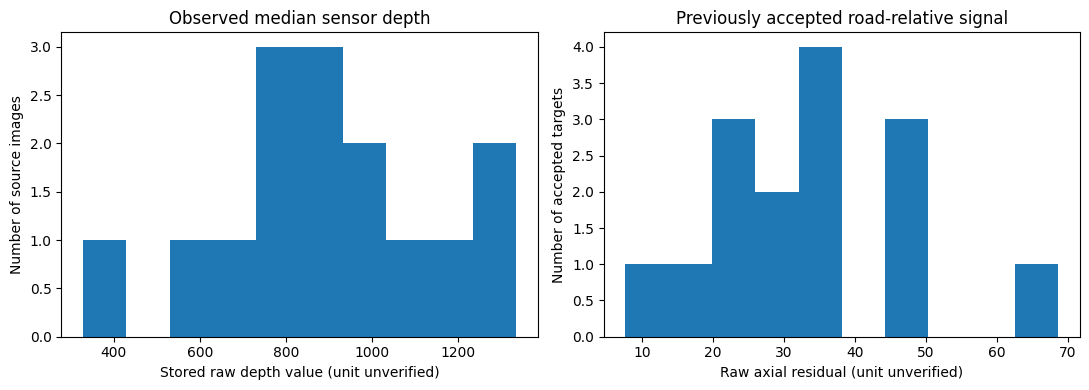


C3-08 SECTION 5 — PothRGBD SCALE EVIDENCE
Original depth arrays inspected: 15
Observed dtypes: {'uint16': 15}
Observed shapes: {'[480, 640]': 15}
Median raw sensor depth: 920.0
Median accepted road residual: 33.393394470214844
Original recording depth scale verified: NO
Metric road-normal training authorized: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-08_section05_POTHRGBD_SCALE_EVIDENCE_20261020T180134_614755Z


In [ ]:

# ============================================================
# C3-08 SECTION 5 — PothRGBD DEPTH-SCALE EVIDENCE TEST
#
# Reuses accepted C3-02 reference-label manifests.
# Inspects a small number of original depth arrays.
# No physical conversion, retuning or training.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
import hashlib
import json
import csv
import numpy as np
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

RAW = Path(
    "/content/drive/MyDrive/"
    "manushi_research_data/pothrgbd/PData-main"
)

S4 = BASE / "02_dataset_audits" / (
    "C3-08_section04_PHYSICAL_REFERENCE_GATE_"
    "20261020T175121_364084Z"
)

PILOT = BASE / "04_geometry_targets" / (
    "C3-02_section14_PothRGBD_PILOT_"
    "20261020T081321_368363Z"
)

EXPANSION = BASE / "04_geometry_targets" / (
    "C3-02_section16_AFFINE_EXPANSION_"
    "20261020T082927_408953Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for folder in (RAW, S4, PILOT, EXPANSION):
    assert folder.is_dir(), f"Missing: {folder}"


# ------------------------------------------------------------
# 1. VERIFY ORIGINAL RESEARCH EVIDENCE
# ------------------------------------------------------------

def sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for part in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(part)

    return h.hexdigest()


def verify(folder, name):

    expected = {}

    with (
        folder / "checksums.sha256"
    ).open() as f:

        for line in f:

            if not line.strip():
                continue

            digest, relative = line.split(None, 1)
            relative = relative.strip()

            rel = Path(relative)
            assert not rel.is_absolute()
            assert ".." not in rel.parts

            expected[relative] = digest

    assert name in expected

    assert sha256(
        folder / name
    ) == expected[name], name

    return expected[name]


h4 = verify(
    S4, "physical_reference_gate.json"
)

hp = verify(
    PILOT, "pilot_target_manifest.csv"
)

he = verify(
    EXPANSION, "expansion_manifest.csv"
)

gate = json.loads(
    (S4 / "physical_reference_gate.json").read_text()
)

assert gate["approved_for_metric_training"] is False

print("Existing metric reference gate: VERIFIED")


# ------------------------------------------------------------
# 2. LOAD THE ORIGINAL ACCEPTANCE RECORDS
# ------------------------------------------------------------

def read_manifest(path):

    with path.open(
        "r", newline="", encoding="utf-8"
    ) as f:

        return list(csv.DictReader(f))


pilot_rows = read_manifest(
    PILOT / "pilot_target_manifest.csv"
)

expansion_rows = read_manifest(
    EXPANSION / "expansion_manifest.csv"
)

accepted = []

for source_name, rows in (
    ("pilot", pilot_rows),
    ("expansion", expansion_rows)
):

    for r in rows:

        if r["status"] != "DIAGNOSTIC_PASS":
            continue

        sample_id = r["sample_id"]

        assert sample_id

        accepted.append({
            "sample_id": sample_id,
            "source": source_name,
            "burst": r["burst"],
            "capture_day": r["capture_day"],

            "depth_sha256": r["depth_sha256"],

            "target_signal_raw": float(
                r.get(
                    "signed_median_raw",
                    r.get("median_signed_raw")
                )
            ),

            "quality_signal_to_road_p95": float(
                r["signal_to_road_p95"]
            )
        })


assert len(accepted) == 33, (
    "Unexpected accepted count. "
    "Inspect source manifests before continuing."
)

assert len({
    r["sample_id"]
    for r in accepted
}) == 33

print(
    "Previously quality-accepted PothRGBD targets:",
    len(accepted)
)


# ------------------------------------------------------------
# 3. PRESELECT A SMALL BURST-DIVERSE SAMPLE
# ------------------------------------------------------------

by_burst = defaultdict(list)

for row in accepted:

    by_burst[row["burst"]].append(row)

selected = []

# At most three accepted examples per burst.
# Selection is made before reading depth arrays.

for burst in sorted(by_burst):

    records = sorted(
        by_burst[burst],
        key=lambda r: r["sample_id"]
    )

    selected.extend(
        records[:3]
    )

assert 1 <= len(selected) <= 15

print(
    "Depth arrays selected for inspection:",
    len(selected)
)

print(
    "Burst distribution:",
    dict(Counter(
        r["burst"]
        for r in selected
    ))
)


# ------------------------------------------------------------
# 4. CREATE VERSIONED OUTPUT BEFORE INSPECTION
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "02_dataset_audits" / (
    "C3-08_section05_POTHRGBD_SCALE_EVIDENCE_"
    + stamp
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

protocol = {
    "stage": "C3-08_SECTION05",
    "selected_sample_ids": [
        r["sample_id"]
        for r in selected
    ],
    "max_samples_per_burst": 3,

    "source_checksums": {
        "physical_reference_gate": h4,
        "pilot_manifest": hp,
        "expansion_manifest": he
    },

    "physical_conversion_authorized": False,
    "metric_training_authorized": False,

    "reference_source": (
        "Original Intel RealSense D415 PothRGBD "
        "sensor arrays, with existing affine "
        "road-relative diagnostic QA"
    ),

    "unit_hypothesis": (
        "Raw depth may represent millimetres; "
        "original recording depth_scale "
        "not yet verified"
    )
}

(
    OUT / "locked_protocol.json"
).write_text(
    json.dumps(protocol, indent=2)
)


# ------------------------------------------------------------
# 5. READ ONLY SELECTED ORIGINAL DEPTH ARRAYS
# ------------------------------------------------------------

measurements = []

for index, record in enumerate(
    selected, 1
):

    sample_id = record["sample_id"]

    depth_file = (
        RAW / "depths"
        / f"{sample_id}_depth.npy"
    )

    row = dict(record)

    row["status"] = "ERROR"

    try:

        assert depth_file.is_file(), (
            f"Missing original depth: {depth_file}"
        )

        actual_hash = sha256(depth_file)

        assert actual_hash == (
            record["depth_sha256"]
        ), "Source depth file changed"

        arr = np.load(
            depth_file,
            mmap_mode="r",
            allow_pickle=False
        )

        assert arr.ndim == 2, (
            "Expected original 2D depth array"
        )

        assert arr.size < 2_000_000, (
            "Unexpectedly large depth array"
        )

        depth = np.asarray(arr)

        valid = depth[
            np.isfinite(depth) & (depth > 0)
        ]

        assert len(valid) > 100

        p1, p10, p50, p90, p99 = (
            np.percentile(
                valid,
                [1, 10, 50, 90, 99]
            )
        )

        row.update({
            "status": "INSPECTED",

            "depth_filename": depth_file.name,
            "depth_dtype": str(depth.dtype),
            "depth_shape": list(depth.shape),

            "valid_depth_fraction": float(
                len(valid) / depth.size
            ),

            "raw_depth_p01": float(p1),
            "raw_depth_p10": float(p10),
            "raw_depth_p50": float(p50),
            "raw_depth_p90": float(p90),
            "raw_depth_p99": float(p99),

            "raw_depth_min": float(
                valid.min()
            ),

            "raw_depth_max": float(
                valid.max()
            ),

            "source_sha256_verified": True,

            "physical_depth_units": "UNVERIFIED",
            "verified_depth_scale_m_per_unit": None
        })

    except Exception as exc:

        row["error"] = (
            f"{type(exc).__name__}: {exc}"
        )

    measurements.append(row)

    print(
        f"{index:02d}/{len(selected):02d} | "
        f"{sample_id} | "
        f"{row['status']} | "
        f"median raw depth: "
        f"{row.get('raw_depth_p50', 'N/A')}",
        flush=True
    )


# ------------------------------------------------------------
# 6. VERIFY COMPLETE INSPECTION
# ------------------------------------------------------------

errors = [
    r for r in measurements
    if r["status"] != "INSPECTED"
]

if errors:

    (
        OUT / "inspection_errors.json"
    ).write_text(
        json.dumps(errors, indent=2)
    )

    raise RuntimeError(
        f"{len(errors)} source inspections failed. "
        f"See {OUT / 'inspection_errors.json'}"
    )


# ------------------------------------------------------------
# 7. SUMMARIZE RAW SENSOR DATA
# ------------------------------------------------------------

all_medians = np.array([
    r["raw_depth_p50"]
    for r in measurements
])

all_signals = np.array([
    r["target_signal_raw"]
    for r in measurements
])

dtypes = dict(
    Counter(
        r["depth_dtype"]
        for r in measurements
    )
)

shapes = dict(
    Counter(
        str(r["depth_shape"])
        for r in measurements
    )
)

summary = {
    "accepted_source_targets": 33,
    "depth_arrays_inspected": len(measurements),

    "source_file_hashes_verified": True,

    "depth_dtypes": dtypes,
    "depth_shapes": shapes,

    "median_raw_sensor_depth_across_samples":
        float(np.median(all_medians)),

    "median_accepted_road_residual_raw":
        float(np.median(all_signals)),

    "original_camera": "Intel RealSense D415",

    "external_papers_suggest_mm": True,

    "original_recording_depth_scale_verified":
        False,

    "original_color_depth_registration_verified":
        False,

    "camera_intrinsics_verified": False,

    "road_normal_metric_targets_verified": False,

    "metric_training_authorized": False
}


# ------------------------------------------------------------
# 8. SAVE BOUNDED RESEARCH DATA
# ------------------------------------------------------------

with (
    OUT / "selected_depth_sensor_statistics.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(measurements[0])
    )

    writer.writeheader()

    for row in measurements:

        writer.writerow({
            k: (
                json.dumps(v)
                if isinstance(v, (list, dict))
                else v
            )
            for k, v in row.items()
        })


sources = {
    "original_pothrgbd_paper": (
        "https://arxiv.org/abs/2505.04207"
    ),

    "independent_2026_pothrgbd_depth_description": (
        "https://arxiv.org/abs/2608.27633"
    ),

    "realsense_d415_depth_scale_discussion": (
        "https://support.realsenseai.com/hc/en-us/"
        "community/posts/360042018333-"
        "D415-Intel-RealSense-Viewer-v-2-33-1-Depth-Unit"
    ),

    "realsense_raw_depth_scale_definition": (
        "https://github.com/realsenseai/"
        "realsense-ros/issues/2464"
    )
}

(
    OUT / "source_evidence.json"
).write_text(
    json.dumps({
        "summary": summary,
        "external_sources": sources,
        "records": measurements,

        "interpretation": (
            "Raw numeric values are observed. "
            "Millimetre conversion remains a "
            "candidate hypothesis, not a "
            "verified original capture setting."
        )
    }, indent=2)
)


# ------------------------------------------------------------
# 9. VISUALIZE RAW DEPTH AND RESIDUAL SCALES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4)
)

axes[0].hist(
    all_medians,
    bins=min(10, len(all_medians))
)

axes[0].set_title(
    "Observed median sensor depth"
)

axes[0].set_xlabel(
    "Stored raw depth value (unit unverified)"
)

axes[0].set_ylabel(
    "Number of source images"
)


axes[1].hist(
    all_signals,
    bins=min(10, len(all_signals))
)

axes[1].set_title(
    "Previously accepted road-relative signal"
)

axes[1].set_xlabel(
    "Raw axial residual (unit unverified)"
)

axes[1].set_ylabel(
    "Number of accepted targets"
)

fig.tight_layout()

fig.savefig(
    OUT / "raw_scale_diagnostic.png",
    dpi=145
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 10. SAVE CHECKSUMS AND FINAL SUMMARY
# ------------------------------------------------------------

checksums = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        checksums.append(
            f"{sha256(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(checksums) + "\n"
)


print("\n" + "=" * 65)
print("C3-08 SECTION 5 — PothRGBD SCALE EVIDENCE")
print("=" * 65)

print(
    "Original depth arrays inspected:",
    summary["depth_arrays_inspected"]
)

print(
    "Observed dtypes:",
    summary["depth_dtypes"]
)

print(
    "Observed shapes:",
    summary["depth_shapes"]
)

print(
    "Median raw sensor depth:",
    summary[
        "median_raw_sensor_depth_across_samples"
    ]
)

print(
    "Median accepted road residual:",
    summary[
        "median_accepted_road_residual_raw"
    ]
)

print("Original recording depth scale verified: NO")
print("Metric road-normal training authorized: NO")

print("\nSaved:", OUT)
print("=" * 65)


Source evidence: VERIFIED
Selected one accepted image per burst:
['20250227_135438', '20250227_163135', '20250305_031258', '20250305_073146', '20250305_110414']
Synthetic plane / area / volume smoke: PASS
1/5 | 20250227_135438 | D95(raw,f600)=56.840 | road-fit P95(raw)=9.077
2/5 | 20250227_163135 | D95(raw,f600)=62.060 | road-fit P95(raw)=14.958
3/5 | 20250305_031258 | D95(raw,f600)=46.417 | road-fit P95(raw)=13.031
4/5 | 20250305_073146 | D95(raw,f600)=41.486 | road-fit P95(raw)=9.052
5/5 | 20250305_110414 | D95(raw,f600)=96.877 | road-fit P95(raw)=30.478


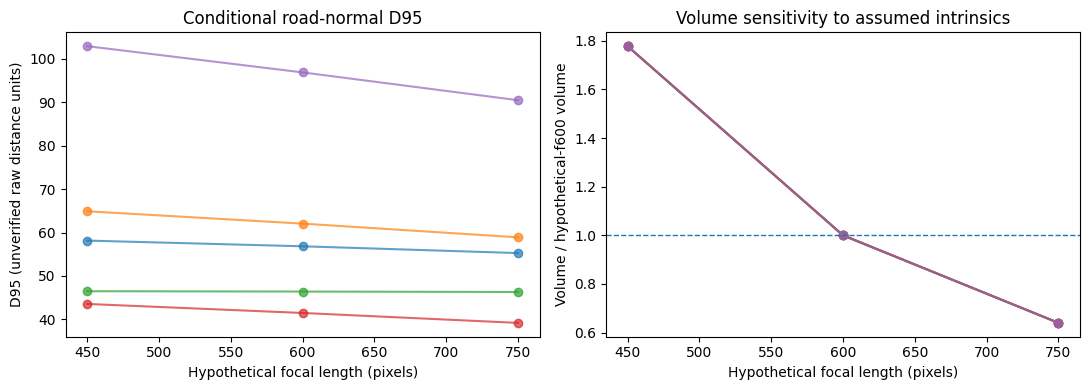


C3-08 SECTION 6 — ROAD-NORMAL GEOMETRY PILOT
Five real source images processed: 5
Synthetic geometry correctness: PASS
Reusable geometry module: SAVED
Conditional geometry maps: SAVED
D95_raw focal-sensitivity max/min median ratio: 1.1018
projected_area_raw2 focal-sensitivity max/min median ratio: 2.5211
volume_raw3 focal-sensitivity max/min median ratio: 2.7778
Verified camera intrinsics: NO
Verified physical depth units: NO
Physical severity authorized: NO
Metric ML training authorized: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-08_section06_ROAD_NORMAL_PILOT_20261020T181227_526683Z


In [ ]:

# ============================================================
# C3-08 SECTION 6 — ROAD-NORMAL 3D GEOMETRY PILOT
#
# Five accepted PothRGBD examples.
# Hypothetical intrinsics sensitivity only.
# NO certified mm, mm2, mm3 or severity.
# NO new trained model.
# CPU / RAM-safe 640x480 arrays.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import importlib.util
import hashlib
import json
import csv
import numpy as np
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

RAW = Path(
    "/content/drive/MyDrive/"
    "manushi_research_data/pothrgbd/PData-main"
)

S5 = BASE / "02_dataset_audits" / (
    "C3-08_section05_POTHRGBD_SCALE_EVIDENCE_"
    "20261020T180134_614755Z"
)

PILOT = BASE / "04_geometry_targets" / (
    "C3-02_section14_PothRGBD_PILOT_"
    "20261020T081321_368363Z"
)

EXPANSION = BASE / "04_geometry_targets" / (
    "C3-02_section16_AFFINE_EXPANSION_"
    "20261020T082927_408953Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for p in (RAW, S5, PILOT, EXPANSION):
    assert p.is_dir(), f"Missing: {p}"


# ------------------------------------------------------------
# 1. VERIFY PREVIOUS EVIDENCE
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for part in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(part)
    return h.hexdigest()


def verify(folder, filename):
    entries = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():
            digest, name = line.split(None, 1)
            entries[name.strip()] = digest

    assert filename in entries
    assert sha(folder / filename) == entries[filename]
    return entries[filename]


source_sha = verify(
    S5, "source_evidence.json"
)

source = json.loads(
    (S5 / "source_evidence.json").read_text()
)

assert (
    source["summary"]["depth_arrays_inspected"]
    == 15
)

assert (
    source["summary"]["metric_training_authorized"]
    is False
)

records = source["records"]

assert len(records) == 15

# Selection fixed before geometry processing.
selected = []

for burst in sorted(set(
    r["burst"] for r in records
)):
    candidates = sorted(
        (
            r for r in records
            if r["burst"] == burst
            and r["status"] == "INSPECTED"
        ),
        key=lambda r: r["sample_id"]
    )

    assert candidates
    selected.append(candidates[0])

assert len(selected) == 5

print("Source evidence: VERIFIED")
print("Selected one accepted image per burst:")
print([r["sample_id"] for r in selected])


# ------------------------------------------------------------
# 2. CREATE VERSIONED ENGINEERING EXPERIMENT
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "04_geometry_targets" / (
    "C3-08_section06_ROAD_NORMAL_PILOT_"
    + stamp
)

OUT.mkdir(parents=True, exist_ok=False)

MAPS = OUT / "conditional_geometry_maps"
MAPS.mkdir()

FOCAL_SCENARIOS = [450., 600., 750.]

# These are hypothetical pixel focal lengths.
# They are NOT claimed D415 calibration values.


# ------------------------------------------------------------
# 3. SAVE REPRODUCIBLE GEOMETRY MODULE
# ------------------------------------------------------------

MODULE = r'''
import numpy as np
from scipy.ndimage import distance_transform_edt

def fit_plane(depth, mask, seed=20261020):

    d = np.asarray(depth)
    m = np.asarray(mask, bool)

    assert d.ndim == 2
    assert m.shape == d.shape and m.any()

    h, w = d.shape

    distance = distance_transform_edt(~m)

    support = (
        (distance >= 8)
        & (distance <= 55)
        & np.isfinite(d)
        & (d > 0)
    )

    yy, xx = np.nonzero(support)

    if len(yy) < 2500:
        raise ValueError("Insufficient intact-road support")

    rng = np.random.default_rng(seed)

    if len(yy) > 15000:
        ids = rng.choice(
            len(yy), 15000, replace=False
        )
        yy, xx = yy[ids], xx[ids]

    A = np.column_stack((
        (xx - (w-1)/2) / w,
        (yy - (h-1)/2) / h,
        np.ones(len(yy))
    ))

    target = 1000.0 / np.asarray(
        d[yy, xx], np.float64
    )

    beta = np.linalg.lstsq(
        A, target, rcond=None
    )[0]

    # Robust iteratively reweighted least squares.
    for _ in range(10):

        residual = target - A @ beta

        center = np.median(residual)

        robust_scale = (
            1.4826 * np.median(
                np.abs(residual-center)
            ) + 1e-8
        )

        weight = np.minimum(
            1.0,
            1.345 * robust_scale
            / (np.abs(residual-center) + 1e-12)
        )

        root = np.sqrt(weight)

        beta = np.linalg.lstsq(
            A * root[:, None],
            target * root,
            rcond=None
        )[0]

    prediction = A @ beta

    if not np.all(
        np.isfinite(prediction) & (prediction > 0)
    ):
        raise ValueError("Invalid inverse-depth road")

    # In-sample healthy-road fit residual only.
    # NOT independent depth-validation error.
    residual_raw = np.abs(
        1000.0 / prediction - d[yy, xx]
    )

    return (
        beta,
        int(support.sum()),
        float(np.percentile(residual_raw, 95))
    )


def geometry(depth, mask, valid, beta, focal_px):

    z = np.asarray(depth, np.float64)
    m = np.asarray(mask, bool)
    v = np.asarray(valid, bool)

    assert m.shape == v.shape == z.shape

    h, w = z.shape

    good = m & v & np.isfinite(z) & (z > 0)

    if good.sum() < 1000:
        raise ValueError("Insufficient valid defect pixels")

    yy, xx = np.nonzero(good)

    a, b, c = np.asarray(beta, np.float64)

    xn = (xx - (w-1)/2) / w
    yn = (yy - (h-1)/2) / h

    inverse = a*xn + b*yn + c

    if not np.all(
        np.isfinite(inverse) & (inverse > 0)
    ):
        raise ValueError("Invalid reference depth")

    focal = float(focal_px)
    assert focal > 0

    # From the fitted inverse-depth road plane:
    # beta3D . P = 1
    #
    # Coordinates and all results retain
    # UNVERIFIED raw sensor distance units.

    norm_factor = np.linalg.norm([
        a*focal/w,
        b*focal/h,
        c
    ])

    z_road = 1000.0 / inverse

    axial = z[yy, xx] - z_road

    signed_normal = (
        axial * inverse / norm_factor
    )

    # Projected area of each image pixel
    # on the fitted intact-road plane.
    projected_area = (
        z_road**3
        * (norm_factor / 1000.0)
        / focal**2
    )

    if not (
        np.isfinite(signed_normal).all()
        and np.isfinite(projected_area).all()
        and (projected_area > 0).all()
    ):
        raise ValueError("Invalid 3D geometry")

    positive = np.maximum(signed_normal, 0)

    result_map = np.full(
        z.shape, np.nan, dtype=np.float32
    )

    result_map[yy, xx] = (
        signed_normal.astype(np.float32)
    )

    axial_pos = np.maximum(axial, 0)

    return {
        "n_valid": int(good.sum()),

        "D95_raw": float(
            np.percentile(positive, 95)
        ),

        "Dmax_raw": float(
            positive.max()
        ),

        "Dmean_raw": float(
            positive.mean()
        ),

        "projected_area_raw2": float(
            projected_area.sum()
        ),

        "volume_raw3": float(
            np.sum(positive * projected_area)
        ),

        "positive_fraction": float(
            np.mean(signed_normal > 0)
        ),

        "normal_to_axial_D95_ratio": float(
            np.percentile(positive, 95)
            / max(
                np.percentile(axial_pos, 95),
                1e-8
            )
        ),

        "signed_normal_map_raw": result_map,
        "valid_pixels": good,
        "axial_inside": axial
    }
'''

module_path = OUT / "roadnormal_engineering.py"

module_path.write_text(MODULE)

spec = importlib.util.spec_from_file_location(
    "c3_08_roadnormal_engineering",
    module_path
)

engine = importlib.util.module_from_spec(spec)
spec.loader.exec_module(engine)


# ------------------------------------------------------------
# 4. MATHEMATICAL SYNTHETIC SMOKE TEST
# ------------------------------------------------------------

# Flat reference at raw depth 1000.
# Artificial central depression of 40 raw units.
# This verifies the implementation, not real accuracy.

H, W = 480, 640

Y, X = np.indices((H, W))

synthetic_mask = (
    (X-320)**2 + (Y-240)**2 < 58**2
)

synthetic_depth = np.full(
    (H, W), 1000, dtype=np.float32
)

synthetic_depth[synthetic_mask] = 1040

beta_test, _, _ = engine.fit_plane(
    synthetic_depth,
    synthetic_mask
)

smoke = engine.geometry(
    synthetic_depth,
    synthetic_mask,
    np.ones_like(synthetic_mask),
    beta_test,
    600.
)

assert abs(
    smoke["D95_raw"] - 40
) < 1e-3

expected_area = (
    synthetic_mask.sum()
    * 1000.0**2 / 600.0**2
)

assert np.isclose(
    smoke["projected_area_raw2"],
    expected_area,
    rtol=1e-6
)

assert np.isclose(
    smoke["volume_raw3"],
    expected_area * 40,
    rtol=1e-6
)

print("Synthetic plane / area / volume smoke: PASS")


# ------------------------------------------------------------
# 5. PROCESS FIVE ORIGINAL DATASET REFERENCES
# ------------------------------------------------------------

results = []
failures = []

for index, rec in enumerate(selected, 1):

    sid = rec["sample_id"]

    source_folder = (
        PILOT
        if rec["source"] == "pilot"
        else EXPANSION
    )

    assert rec["source"] in (
        "pilot", "expansion"
    )

    depth_path = (
        RAW / "depths" / f"{sid}_depth.npy"
    )

    npz_path = (
        source_folder
        / "diagnostic_pass_npz"
        / f"{sid}_axial_raw.npz"
    )

    try:

        assert depth_path.is_file()
        assert npz_path.is_file()

        assert (
            sha(depth_path)
            == rec["depth_sha256"]
        ), "Depth-file SHA mismatch"

        depth = np.load(
            depth_path,
            allow_pickle=False
        )

        with np.load(
            npz_path,
            allow_pickle=False
        ) as prior:

            required = {
                "signed_axial_raw",
                "damage_mask",
                "valid_target_mask"
            }

            assert required.issubset(
                set(prior.files)
            )

            old_axial = prior[
                "signed_axial_raw"
            ].copy()

            mask = prior[
                "damage_mask"
            ].astype(bool)

            valid = prior[
                "valid_target_mask"
            ].astype(bool)

        assert depth.shape == mask.shape
        assert depth.shape == valid.shape
        assert depth.shape == old_axial.shape
        assert depth.shape == (480, 640)

        beta, support_n, road_p95 = (
            engine.fit_plane(
                depth,
                mask,
                seed=20261020
            )
        )

        row = {
            "sample_id": sid,
            "burst": rec["burst"],

            "original_depth_sha256":
                rec["depth_sha256"],

            "prior_npz_sha256":
                sha(npz_path),

            "healthy_support_pixels":
                support_n,

            "road_fit_in_sample_p95_raw":
                road_p95,

            "plane_coefficients":
                [float(x) for x in beta],

            "scenarios": {}
        }

        for f in FOCAL_SCENARIOS:

            result = engine.geometry(
                depth, mask, valid,
                beta, f
            )

            key = f"hypothetical_f{int(f)}"

            row["scenarios"][key] = {
                k: v for k, v in result.items()
                if k not in (
                    "signed_normal_map_raw",
                    "valid_pixels",
                    "axial_inside"
                )
            }

            if f == 600.:

                good = result["valid_pixels"]

                old = old_axial[good]
                new = result["axial_inside"]

                comparable = (
                    np.isfinite(old)
                    & np.isfinite(new)
                )

                assert comparable.sum() > 1000

                # Agreement with our earlier axial
                # estimator is NOT physical validation.
                row[
                    "refit_vs_previous_axial_MAE_raw"
                ] = float(np.mean(
                    np.abs(
                        old[comparable]
                        - new[comparable]
                    )
                ))

                row[
                    "refit_positive_fraction"
                ] = result["positive_fraction"]

                np.savez_compressed(
                    MAPS / (
                        f"{sid}_hypothetical_f600.npz"
                    ),
                    signed_normal_raw=(
                        result[
                            "signed_normal_map_raw"
                        ]
                    ),
                    valid_mask=good.astype(
                        np.uint8
                    ),
                    plane_coefficients=beta,
                    assumed_focal_px=np.array(
                        600., dtype=np.float64
                    ),
                    original_depth_sha256=np.array(
                        rec["depth_sha256"]
                    ),
                    physical_units_verified=np.array(
                        False
                    )
                )

        results.append(row)

        print(
            f"{index}/5 | {sid} | "
            f"D95(raw,f600)="
            f"{row['scenarios']['hypothetical_f600']['D95_raw']:.3f} | "
            f"road-fit P95(raw)={road_p95:.3f}",
            flush=True
        )

    except Exception as exc:

        failures.append({
            "sample_id": sid,
            "error": (
                type(exc).__name__
                + ": " + str(exc)
            )
        })

if failures:

    (
        OUT / "failures.json"
    ).write_text(
        json.dumps(failures, indent=2)
    )

    raise RuntimeError(
        f"{len(failures)} samples failed. "
        f"Inspect {OUT / 'failures.json'}"
    )


# ------------------------------------------------------------
# 6. SUMMARIZE INTRINSICS SENSITIVITY
# ------------------------------------------------------------

assert len(results) == 5

metrics = [
    "D95_raw",
    "projected_area_raw2",
    "volume_raw3"
]

sensitivity = {}

for metric in metrics:

    values = {
        str(int(f)): np.array([
            r["scenarios"][
                f"hypothetical_f{int(f)}"
            ][metric]
            for r in results
        ])
        for f in FOCAL_SCENARIOS
    }

    sensitivity[metric] = {
        "medians": {
            k: float(np.median(v))
            for k, v in values.items()
        },

        "median_max_min_ratio": float(
            np.median([
                max(values[k][i] for k in values)
                / max(
                    min(values[k][i] for k in values),
                    1e-12
                )
                for i in range(5)
            ])
        )
    }


# ------------------------------------------------------------
# 7. PLOT THE SENSITIVITY
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4)
)

for r in results:

    d95 = [
        r["scenarios"][
            f"hypothetical_f{int(f)}"
        ]["D95_raw"]
        for f in FOCAL_SCENARIOS
    ]

    axes[0].plot(
        FOCAL_SCENARIOS,
        d95,
        marker="o",
        alpha=0.7
    )

axes[0].set_title(
    "Conditional road-normal D95"
)

axes[0].set_xlabel(
    "Hypothetical focal length (pixels)"
)

axes[0].set_ylabel(
    "D95 (unverified raw distance units)"
)


relative_volumes = []

for r in results:

    v600 = r["scenarios"][
        "hypothetical_f600"
    ]["volume_raw3"]

    relative_volumes.append([
        r["scenarios"][
            f"hypothetical_f{int(f)}"
        ]["volume_raw3"] / max(v600, 1e-12)
        for f in FOCAL_SCENARIOS
    ])

relative_volumes = np.asarray(
    relative_volumes
)

for i in range(len(results)):

    axes[1].plot(
        FOCAL_SCENARIOS,
        relative_volumes[i],
        marker="o",
        alpha=0.7
    )

axes[1].axhline(
    1.0,
    linestyle="--",
    linewidth=1
)

axes[1].set_title(
    "Volume sensitivity to assumed intrinsics"
)

axes[1].set_xlabel(
    "Hypothetical focal length (pixels)"
)

axes[1].set_ylabel(
    "Volume / hypothetical-f600 volume"
)

fig.tight_layout()

fig.savefig(
    OUT / "intrinsics_sensitivity.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 8. SAVE REPRODUCIBLE EVIDENCE
# ------------------------------------------------------------

report = {
    "stage": "C3-08_SECTION06",
    "research_purpose": (
        "Road-normal geometric reconstruction "
        "feasibility and intrinsics sensitivity"
    ),

    "source_section05_sha256": source_sha,

    "sample_count": 5,

    "selection_rule": (
        "First previously inspected accepted "
        "sample per provisional burst"
    ),

    "hypothetical_fx_fy_px":
        FOCAL_SCENARIOS,

    "hypothetical_cx_cy": (
        "Image centre, not camera calibration"
    ),

    "results": results,
    "sensitivity": sensitivity,

    "synthetic_geometry_smoke": "PASS",

    "scale_verified": False,
    "intrinsics_verified": False,
    "road_normal_orientation_physically_verified":
        False,

    "physical_measurements_authorized": False,
    "metric_model_training_authorized": False,

    "scientific_limitations": [
        "The assumed focal lengths are scenarios, not calibration.",
        "Depth units are not independently certified.",
        "Pixel alignment and distortion are not independently calibrated.",
        "Road surfaces are approximated locally as planes.",
        "Earlier axial labels are not independent physical ground truth.",
        "Five samples do not establish scene generalization."
    ]
}

(
    OUT / "roadnormal_geometry_report.json"
).write_text(
    json.dumps(report, indent=2)
)

contract = {
    "module": "roadnormal_engineering.py",
    "functions": {
        "fit_plane": (
            "depth 2D raw, mask 2D bool "
            "-> beta, n_support, training-fit road p95"
        ),
        "geometry": (
            "depth, mask, valid, beta, assumed_focal_px "
            "-> raw depth/area/volume diagnostics"
        )
    },

    "units": {
        "depth": "UNVERIFIED_RAW",
        "area": "UNVERIFIED_RAW_SQUARED",
        "volume": "UNVERIFIED_RAW_CUBED"
    },

    "production_metric_use": False,
    "training_metric_labels_approved": False
}

(
    OUT / "engineering_contract.json"
).write_text(
    json.dumps(contract, indent=2)
)


# ------------------------------------------------------------
# 9. CHECKSUM ALL OUTPUTS
# ------------------------------------------------------------

lines = []

for path in sorted(OUT.rglob("*")):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):

        lines.append(
            f"{sha(path)}  "
            f"{path.relative_to(OUT).as_posix()}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 66)
print("C3-08 SECTION 6 — ROAD-NORMAL GEOMETRY PILOT")
print("=" * 66)

print("Five real source images processed:", len(results))
print("Synthetic geometry correctness: PASS")
print("Reusable geometry module: SAVED")
print("Conditional geometry maps: SAVED")

for metric in metrics:

    print(
        f"{metric} focal-sensitivity max/min "
        f"median ratio:",
        round(
            sensitivity[metric][
                "median_max_min_ratio"
            ], 4
        )
    )

print("Verified camera intrinsics: NO")
print("Verified physical depth units: NO")
print("Physical severity authorized: NO")
print("Metric ML training authorized: NO")

print("\nSaved:", OUT)
print("=" * 66)


In [ ]:

# ============================================================
# C3-08 SECTION 7
# FULL 33-SAMPLE ROAD-NORMAL REFERENCE RELIABILITY AUDIT
#
# - Uses only previously accepted development targets
# - Four-sector leave-one-sector-out road-fit tests
# - Reuses Section 6's verified geometry implementation
# - Conditional f=600 geometry (NOT camera calibration)
# - No independent test data / no ML training
# - No certified physical units or severity
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from scipy.ndimage import distance_transform_edt
import importlib.util
import hashlib, json, csv
import numpy as np

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

RAW = Path(
    "/content/drive/MyDrive/"
    "manushi_research_data/pothrgbd/PData-main"
)

PILOT = BASE / "04_geometry_targets" / (
    "C3-02_section14_PothRGBD_PILOT_"
    "20261020T081321_368363Z"
)

EXPANSION = BASE / "04_geometry_targets" / (
    "C3-02_section16_AFFINE_EXPANSION_"
    "20261020T082927_408953Z"
)

S6 = BASE / "04_geometry_targets" / (
    "C3-08_section06_ROAD_NORMAL_PILOT_"
    "20261020T181227_526683Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for folder in (RAW, PILOT, EXPANSION, S6):
    assert folder.is_dir(), f"Missing: {folder}"


# ------------------------------------------------------------
# 1. SOURCE INTEGRITY
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


def verify(folder, filename):
    entries = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():
        if line.strip():
            digest, name = line.split(None, 1)
            entries[name.strip()] = digest

    assert filename in entries
    assert sha(folder / filename) == entries[filename]
    return entries[filename]


hp = verify(
    PILOT, "pilot_target_manifest.csv"
)
he = verify(
    EXPANSION, "expansion_manifest.csv"
)
hs = verify(
    S6, "roadnormal_engineering.py"
)
verify(S6, "roadnormal_geometry_report.json")

previous = json.loads(
    (S6 / "roadnormal_geometry_report.json").read_text()
)

assert previous["sample_count"] == 5
assert previous["synthetic_geometry_smoke"] == "PASS"
assert previous["intrinsics_verified"] is False

spec = importlib.util.spec_from_file_location(
    "c308_engine_s7",
    S6 / "roadnormal_engineering.py"
)

engine = importlib.util.module_from_spec(spec)
spec.loader.exec_module(engine)

print("Prior geometry code and sources: VERIFIED")


# ------------------------------------------------------------
# 2. LOAD THE 33 PRE-ACCEPTED SAMPLE IDENTITIES
# ------------------------------------------------------------

def read_csv(path):
    with open(path, newline="") as f:
        return list(csv.DictReader(f))


accepted = []

for source_name, folder, filename in (
    ("pilot", PILOT, "pilot_target_manifest.csv"),
    ("expansion", EXPANSION, "expansion_manifest.csv")
):

    for row in read_csv(folder / filename):
        if row["status"] == "DIAGNOSTIC_PASS":
            accepted.append({
                "id": row["sample_id"],
                "source": source_name,
                "folder": folder,
                "burst": row["burst"],
                "depth_sha": row["depth_sha256"]
            })

assert len(accepted) == 33
assert len(set(r["id"] for r in accepted)) == 33

accepted.sort(key=lambda r: r["id"])

print("Original accepted samples:", len(accepted))
print(
    "Provisional burst counts:",
    dict(Counter(r["burst"] for r in accepted))
)


# ------------------------------------------------------------
# 3. LOCK THE ANALYSIS PROTOCOL
# ------------------------------------------------------------

FOCAL = 600.0  # Hypothetical, NOT verified intrinsics.
SEED = 20261020

# Original diagnostic threshold, used only for
# an additional engineering reliability flag.
MAX_HOLDOUT_TO_D95 = 0.5

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "04_geometry_targets" / (
    "C3-08_section07_FULL33_ROADNORMAL_AUDIT_"
    + stamp
)

OUT.mkdir(parents=True, exist_ok=False)

MAPS = OUT / "conditional_maps"
MAPS.mkdir()

protocol = {
    "stage": "C3-08_SECTION07",
    "sample_ids": [r["id"] for r in accepted],
    "hypothetical_fx_fy": FOCAL,
    "principal_point": "image_centre_assumed",
    "support_ring_px": [8, 55],
    "heldout_sectors": 4,
    "min_heldout_support_pixels": 200,
    "max_training_support_samples": 15000,
    "irls_iterations": 10,
    "exploratory_holdout_ratio_limit":
        MAX_HOLDOUT_TO_D95,
    "seed": SEED,
    "source_checksums": {
        "pilot": hp,
        "expansion": he,
        "geometry_module": hs
    },
    "metric_units_verified": False,
    "physical_training_authorized": False,
    "independent_scene_validation": False
}

(
    OUT / "locked_protocol.json"
).write_text(json.dumps(protocol, indent=2))


# ------------------------------------------------------------
# 4. ROBUST PLANE FIT — TRAINING SUPPORT ONLY
# ------------------------------------------------------------

def robust_fit(A, target, seed):

    rng = np.random.default_rng(seed)

    if len(target) > 15000:
        indices = rng.choice(
            len(target), 15000, replace=False
        )
        A = A[indices]
        target = target[indices]

    beta = np.linalg.lstsq(
        A, target, rcond=None
    )[0]

    for _ in range(10):

        residual = target - A @ beta
        centre = np.median(residual)

        scale = (
            1.4826
            * np.median(np.abs(residual-centre))
            + 1e-8
        )

        weights = np.minimum(
            1.0,
            1.345 * scale
            / (np.abs(residual-centre) + 1e-12)
        )

        root = np.sqrt(weights)

        beta = np.linalg.lstsq(
            A * root[:, None],
            target * root,
            rcond=None
        )[0]

    return beta


def spatial_road_holdout(depth, mask, sample_id):

    d = np.asarray(depth, np.float64)
    m = np.asarray(mask, bool)

    h, w = d.shape

    distance = distance_transform_edt(~m)

    ring = (
        (distance >= 8)
        & (distance <= 55)
        & np.isfinite(d)
        & (d > 0)
    )

    yy, xx = np.nonzero(ring)

    if len(xx) < 2500:
        raise ValueError("Insufficient road support")

    my, mx = np.nonzero(m)

    cx = float(np.mean(mx))
    cy = float(np.mean(my))

    angle = np.arctan2(
        yy-cy, xx-cx
    )

    sector = np.floor(
        (angle + np.pi)
        / (np.pi/2)
    ).astype(int) % 4

    A = np.column_stack((
        (xx-(w-1)/2)/w,
        (yy-(h-1)/2)/h,
        np.ones(len(xx))
    ))

    y = 1000.0 / d[yy, xx]

    seed_base = (
        SEED
        + int(
            hashlib.sha256(
                sample_id.encode()
            ).hexdigest()[:8], 16
        )
    )

    holdout_p95 = []
    holdout_median = []
    sector_counts = []

    for fold in range(4):

        testing = sector == fold
        training = ~testing

        sector_counts.append(int(testing.sum()))

        if testing.sum() < 200:
            raise ValueError(
                f"Too few held-out pixels: {fold}"
            )

        if training.sum() < 2500:
            raise ValueError(
                f"Too few training pixels: {fold}"
            )

        beta = robust_fit(
            A[training],
            y[training],
            seed_base+fold
        )

        predicted_inverse = A[testing] @ beta

        if not np.all(
            np.isfinite(predicted_inverse)
            & (predicted_inverse > 0)
        ):
            raise ValueError(
                "Invalid held-out predicted road"
            )

        predicted_depth = (
            1000.0 / predicted_inverse
        )

        error = np.abs(
            predicted_depth - d[yy[testing], xx[testing]]
        )

        holdout_p95.append(
            float(np.percentile(error, 95))
        )

        holdout_median.append(
            float(np.median(error))
        )

    return {
        "holdout_p95_raw": holdout_p95,
        "holdout_median_raw": holdout_median,
        "worst_holdout_p95_raw": max(holdout_p95),
        "road_sector_pixel_counts": sector_counts
    }


# ------------------------------------------------------------
# 5. PROCESS ALL 33 ORIGINAL REFERENCES
# ------------------------------------------------------------

results = []
failures = []

for index, record in enumerate(accepted, 1):

    sid = record["id"]

    depth_path = (
        RAW / "depths" / f"{sid}_depth.npy"
    )

    target_path = (
        record["folder"]
        / "diagnostic_pass_npz"
        / f"{sid}_axial_raw.npz"
    )

    try:

        assert depth_path.is_file()
        assert target_path.is_file()

        assert (
            sha(depth_path) == record["depth_sha"]
        ), "Depth source checksum mismatch"

        depth = np.load(
            depth_path, allow_pickle=False
        )

        with np.load(
            target_path, allow_pickle=False
        ) as data:

            required = {
                "damage_mask",
                "valid_target_mask",
                "signed_axial_raw"
            }

            assert required.issubset(data.files)

            mask = data["damage_mask"].astype(bool)
            valid = data[
                "valid_target_mask"
            ].astype(bool)

            previous_axial = data[
                "signed_axial_raw"
            ].copy()

        assert depth.shape == (480, 640)
        assert mask.shape == valid.shape == depth.shape
        assert previous_axial.shape == depth.shape

        heldout = spatial_road_holdout(
            depth, mask, sid
        )

        beta, support_n, insample_p95 = (
            engine.fit_plane(
                depth, mask,
                seed=SEED
            )
        )

        geometry = engine.geometry(
            depth, mask, valid,
            beta, FOCAL
        )

        good = geometry["valid_pixels"]

        old = previous_axial[good]
        new = geometry["axial_inside"]

        comparable = (
            np.isfinite(old) & np.isfinite(new)
        )

        assert comparable.sum() > 1000

        comparison_mae = float(np.mean(
            np.abs(
                old[comparable] - new[comparable]
            )
        ))

        d95 = geometry["D95_raw"]

        ratio = (
            heldout["worst_holdout_p95_raw"]
            / max(d95, 1e-8)
        )

        flag = (
            "ROAD_REFERENCE_REVIEW"
            if ratio > MAX_HOLDOUT_TO_D95
            else "ENGINEERING_DIAGNOSTIC_PASS"
        )

        row = {
            "sample_id": sid,
            "burst": record["burst"],
            "source": record["source"],

            "n_valid": geometry["n_valid"],
            "road_support_pixels": support_n,

            "D95_raw": d95,
            "Dmax_raw": geometry["Dmax_raw"],
            "Dmean_raw": geometry["Dmean_raw"],

            "area_raw2": geometry[
                "projected_area_raw2"
            ],

            "volume_raw3": geometry["volume_raw3"],

            "positive_fraction": geometry[
                "positive_fraction"
            ],

            "in_sample_road_p95_raw": insample_p95,

            "worst_holdout_p95_raw":
                heldout["worst_holdout_p95_raw"],

            "holdout_to_D95":
                float(ratio),

            "axial_refit_difference_MAE_raw":
                comparison_mae,

            "reference_reliability_flag":
                flag,

            "camera_calibration_verified": False,
            "raw_units_verified": False,
            "physical_severity_approved": False
        }

        results.append(row)

        np.savez_compressed(
            MAPS / f"{sid}_conditional.npz",
            roadnormal_raw=geometry[
                "signed_normal_map_raw"
            ],
            valid_mask=good.astype(np.uint8),
            beta=np.asarray(beta, np.float64),
            hypothetical_fx_fy=np.array(FOCAL),
            original_depth_sha256=np.array(
                record["depth_sha"]
            ),
            reference_reliability_flag=np.array(flag),
            physical_units_verified=np.array(False)
        )

        print(
            f"{index:02d}/33 | {sid} | "
            f"D95={d95:.2f} raw | "
            f"heldout/D95={ratio:.3f} | {flag}",
            flush=True
        )

    except Exception as exc:

        failures.append({
            "sample_id": sid,
            "error": (
                type(exc).__name__ + ": "
                + str(exc)
            )
        })

        print(
            f"{index:02d}/33 | {sid} | FAILED: {exc}",
            flush=True
        )


# ------------------------------------------------------------
# 6. SAVE RESULTS, INCLUDING ANY FAILURES
# ------------------------------------------------------------

(
    OUT / "failures.json"
).write_text(
    json.dumps(failures, indent=2)
)

if results:

    with (
        OUT / "all33_reference_reliability.csv"
    ).open("w", newline="") as file:

        writer = csv.DictWriter(
            file,
            fieldnames=list(results[0])
        )

        writer.writeheader()
        writer.writerows(results)


counts = Counter(
    r["reference_reliability_flag"]
    for r in results
)

summary = {
    "stage": "C3-08_SECTION07",
    "original_accepted_samples": 33,
    "processed": len(results),
    "failures": len(failures),
    "reliability_flags": dict(counts),

    "median_D95_raw": (
        float(np.median([
            r["D95_raw"]
            for r in results
        ])) if results else None
    ),

    "median_holdout_to_D95": (
        float(np.median([
            r["holdout_to_D95"]
            for r in results
        ])) if results else None
    ),

    "real_world_intrinsics_verified": False,
    "physical_depth_scale_verified": False,
    "independent_scene_validation": False,
    "metric_CRDL_training_authorized": False,
    "physical_severity_authorized": False,

    "interpretation": (
        "Reference-plane stability and conditional "
        "geometry feasibility only. These labels "
        "are not certified physical measurements."
    )
}

(
    OUT / "full33_roadnormal_report.json"
).write_text(
    json.dumps({
        "summary": summary,
        "records": results,
        "errors": failures,
        "protocol": protocol
    }, indent=2)
)


# ------------------------------------------------------------
# 7. RELOAD / INTEGRITY SMOKE TEST
# ------------------------------------------------------------

for row in results:

    path = (
        MAPS
        / f"{row['sample_id']}_conditional.npz"
    )

    with np.load(
        path, allow_pickle=False
    ) as bundle:

        assert bundle["roadnormal_raw"].shape == (
            480, 640
        )

        assert bundle["valid_mask"].shape == (
            480, 640
        )

        assert not bool(
            bundle["physical_units_verified"]
        )

        assert float(
            bundle["hypothetical_fx_fy"]
        ) == FOCAL

print(
    "\nConditional-map reload checks:",
    "PASS" if len(results) else "NO MAPS"
)


# ------------------------------------------------------------
# 8. CHECKSUMS
# ------------------------------------------------------------

checksums = []

for path in sorted(OUT.rglob("*")):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):

        checksums.append(
            f"{sha(path)}  "
            f"{path.relative_to(OUT).as_posix()}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(checksums) + "\n"
)


# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 66)
print("C3-08 SECTION 7 — FULL33 ROAD-NORMAL AUDIT")
print("=" * 66)

print("Previously accepted samples:", 33)
print("Successfully processed:", len(results))
print("Processing failures:", len(failures))

print("Reference reliability categories:")
print(dict(counts))

print(
    "Median conditional D95:",
    summary["median_D95_raw"],
    "raw units"
)

print(
    "Median heldout-to-D95 ratio:",
    summary["median_holdout_to_D95"]
)

print("Real camera intrinsics verified: NO")
print("Metric CRDL training authorized: NO")
print("Physical severity authorized: NO")

print("\nSaved:", OUT)
print("=" * 66)

if failures:
    print(
        "\nATTENTION: Review failures.json "
        "before proceeding to the next section."
    )


Prior geometry code and sources: VERIFIED
Original accepted samples: 33
Provisional burst counts: {'POTHRGBD_BURST_0001': 4, 'POTHRGBD_BURST_0002': 12, 'POTHRGBD_BURST_0003': 7, 'POTHRGBD_BURST_0004': 4, 'POTHRGBD_BURST_0005': 6}
01/33 | 20250227_135438 | D95=56.84 raw | heldout/D95=0.216 | ENGINEERING_DIAGNOSTIC_PASS
02/33 | 20250227_135652 | D95=61.70 raw | heldout/D95=0.240 | ENGINEERING_DIAGNOSTIC_PASS
03/33 | 20250227_141418 | D95=27.61 raw | heldout/D95=0.339 | ENGINEERING_DIAGNOSTIC_PASS
04/33 | 20250227_141738 | D95=35.74 raw | heldout/D95=0.268 | ENGINEERING_DIAGNOSTIC_PASS
05/33 | 20250227_163135 | D95=62.06 raw | heldout/D95=0.324 | ENGINEERING_DIAGNOSTIC_PASS
06/33 | 20250227_175242 | D95=33.38 raw | heldout/D95=0.232 | ENGINEERING_DIAGNOSTIC_PASS
07/33 | 20250227_180722 | D95=69.91 raw | heldout/D95=0.313 | ENGINEERING_DIAGNOSTIC_PASS
08/33 | 20250227_182831 | D95=32.25 raw | heldout/D95=0.250 | ENGINEERING_DIAGNOSTIC_PASS
09/33 | 20250227_183642 | D95=71.51 raw | heldout/

Original RGB and geometry manifests: VERIFIED
Verified RGB/target pairs: 5/33
Verified RGB/target pairs: 10/33
Verified RGB/target pairs: 15/33
Verified RGB/target pairs: 20/33
Verified RGB/target pairs: 25/33
Verified RGB/target pairs: 30/33
Verified RGB/target pairs: 33/33


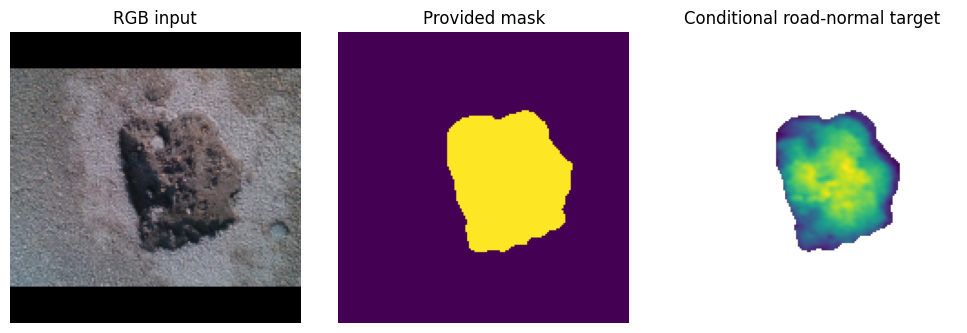


C3-08 SECTION 8 — ROAD-NORMAL ML HANDOFF
Verified paired RGB/geometry samples: 33
Provisional burst development folds: 5
Validation sizes: [4, 12, 7, 4, 6]
Tensor shapes: (33, 5, 160, 160) (33, 1, 160, 160) (33, 1, 160, 160)
Source alignment and reload: PASS
Mask-only ablation contract: PASS
Actual physical calibration: UNVERIFIED
Model trained in this section: NO
Metric severity: NOT AUTHORIZED

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-08_section08_GROUPED_ROADNORMAL_ML_HANDOFF_20261020T184716_733041Z


In [ ]:

# ============================================================
# C3-08 SECTION 8 — GROUP-PROXY ROAD-NORMAL ML HANDOFF
#
# 33 paired RGB + mask + conditional road-normal targets
# Five leave-one-provisional-burst-out development folds
# No certified physical units, no model training yet
# CPU / RAM-safe, reproducible and source-verified
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from PIL import Image
import csv, json, hashlib, sys

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

RAW = Path(
    "/content/drive/MyDrive/"
    "manushi_research_data/pothrgbd/PData-main"
)

S14 = BASE / "04_geometry_targets" / (
    "C3-02_section14_PothRGBD_PILOT_"
    "20261020T081321_368363Z"
)

S16 = BASE / "04_geometry_targets" / (
    "C3-02_section16_AFFINE_EXPANSION_"
    "20261020T082927_408953Z"
)

S7 = BASE / "04_geometry_targets" / (
    "C3-08_section07_FULL33_ROADNORMAL_AUDIT_"
    "20261020T182922_896448Z"
)

OLD = (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)

OLD_RUN = BASE / "05_training_runs" / OLD
OLD_CKPT = BASE / "06_model_checkpoints" / OLD

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for directory in [
    RAW / "images",
    S14, S16, S7, OLD_RUN, OLD_CKPT
]:
    assert directory.is_dir(), f"Missing: {directory}"


# ------------------------------------------------------------
# 1. SOURCE CHECKSUM VERIFICATION
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with Path(path).open("rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


def checks(folder):

    found = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if not line.strip():
            continue

        digest, name = line.split(None, 1)
        name = name.strip()

        rel = Path(name)

        assert not rel.is_absolute()
        assert ".." not in rel.parts
        assert name not in found

        found[name] = digest

    return found


source_checks = {
    p: checks(p)
    for p in [
        S14, S16, S7, OLD_RUN, OLD_CKPT
    ]
}


def verify(folder, rel):

    assert rel in source_checks[folder], (
        f"Missing checksum: {rel}"
    )

    assert sha(folder / rel) == (
        source_checks[folder][rel]
    ), f"SHA mismatch: {rel}"

    return source_checks[folder][rel]


for folder, name in [
    (S7, "full33_roadnormal_report.json"),
    (S7, "locked_protocol.json"),
    (S14, "pilot_target_manifest.csv"),
    (S16, "expansion_manifest.csv"),
    (OLD_RUN, "train_only_manifest.csv"),
    (OLD_CKPT, "crdl_dev_model.py")
]:
    verify(folder, name)


# ------------------------------------------------------------
# 2. LOAD AND MATCH ALL 33 ORIGINAL IMAGE IDENTITIES
# ------------------------------------------------------------

report = json.loads(
    (
        S7 / "full33_roadnormal_report.json"
    ).read_text()
)

assert report["summary"]["processed"] == 33
assert report["summary"]["failures"] == 0

assert (
    report["summary"][
        "metric_CRDL_training_authorized"
    ] is False
)

with (
    OLD_RUN / "train_only_manifest.csv"
).open(newline="") as f:

    source_manifest = list(csv.DictReader(f))

assert len(source_manifest) == 33

rows = sorted(
    source_manifest,
    key=lambda r: r["sample_id"]
)

assert len({
    r["sample_id"] for r in rows
}) == 33

depth_hashes = {}

for folder, name in [
    (S14, "pilot_target_manifest.csv"),
    (S16, "expansion_manifest.csv")
]:

    with (folder / name).open(newline="") as f:

        for item in csv.DictReader(f):

            if item["status"] == "DIAGNOSTIC_PASS":

                sid = item["sample_id"]

                assert sid not in depth_hashes

                depth_hashes[sid] = (
                    item["depth_sha256"]
                )

assert set(depth_hashes) == {
    r["sample_id"] for r in rows
}

source_records = {
    r["sample_id"]: r
    for r in report["records"]
}

assert {
    r["sample_id"] for r in rows
} == set(source_records)

print("Original RGB and geometry manifests: VERIFIED")


# ------------------------------------------------------------
# 3. REUSE THE ORIGINAL INPUT PREPROCESSING
# ------------------------------------------------------------

# Reuse only the encoder function.
# Do NOT load pretrained model weights:
# those were previously trained on all 33 images.

if str(OLD_CKPT) not in sys.path:
    sys.path.insert(0, str(OLD_CKPT))

from crdl_dev_model import encode_input


# ------------------------------------------------------------
# 4. FREEZE FIVE GROUP-PROXY DEVELOPMENT FOLDS
# ------------------------------------------------------------

bursts = sorted({
    r["burst"] for r in rows
})

assert len(bursts) == 5

folds = []

for fold_id, burst in enumerate(bursts):

    validation_indices = [
        i for i, r in enumerate(rows)
        if r["burst"] == burst
    ]

    training_indices = [
        i for i, r in enumerate(rows)
        if r["burst"] != burst
    ]

    assert len(validation_indices) >= 3
    assert len(training_indices) >= 20

    assert set(training_indices).isdisjoint(
        validation_indices
    )

    folds.append({
        "fold_id": fold_id,
        "validation_burst": burst,
        "train_indices": training_indices,
        "validation_indices": validation_indices,
        "train_count": len(training_indices),
        "validation_count": len(validation_indices)
    })

assert sorted(
    i
    for fold in folds
    for i in fold["validation_indices"]
) == list(range(33))


# ------------------------------------------------------------
# 5. SAVE LOCKED EXPERIMENT PROTOCOL
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "04_geometry_targets" / (
    "C3-08_section08_GROUPED_ROADNORMAL_ML_HANDOFF_"
    + stamp
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

protocol = {
    "stage": "C3-08_SECTION08",

    "source_count": 33,

    "input_shape_chw": [5, 160, 160],

    "inputs": (
        "RGB normalized to [0,1], ground-truth "
        "mask, confidence fixed at 1.0"
    ),

    "target": (
        "Nonnegative conditional road-normal "
        "depression in UNVERIFIED RAW units"
    ),

    "reference_geometry": (
        "Hypothetical fx=fy=600 pixels; "
        "principal point at image centre"
    ),

    "units_verified": False,
    "metric_training_authorized": False,

    "training_performed": False,
    "model_checkpoint_created": False,

    "folds": (
        "Leave-one-PROVISIONAL-burst-out; "
        "NOT verified independent physical scenes"
    ),

    "fold_normalization": (
        "Fit target scale using TRAIN samples "
        "of each fold only"
    ),

    "old_model_checkpoint_weights_reused": False,
    "protected_399_benchmark_opened": False,

    "source_checksums": {
        "section07_report": verify(
            S7, "full33_roadnormal_report.json"
        ),

        "original_RGB_manifest": verify(
            OLD_RUN, "train_only_manifest.csv"
        ),

        "original_RGB_encoder": verify(
            OLD_CKPT, "crdl_dev_model.py"
        )
    },

    "sample_order": [
        r["sample_id"] for r in rows
    ]
}

(
    OUT / "locked_protocol.json"
).write_text(
    json.dumps(protocol, indent=2)
)

(
    OUT / "provisional_burst_development_folds.json"
).write_text(
    json.dumps(folds, indent=2)
)


# ------------------------------------------------------------
# 6. CREATE IMAGE-ALIGNED TRAINING TENSORS
# ------------------------------------------------------------

X, Y, W = [], [], []
qa = []

for index, r in enumerate(rows, 1):

    sid = r["sample_id"]

    folder = {
        S14.name: S14,
        S16.name: S16
    }.get(r["source_stage"])

    assert folder is not None

    rel = r["npz_relative"]

    assert rel.startswith(
        "diagnostic_pass_npz/"
    )

    assert verify(folder, rel) == (
        r["npz_sha256"]
    )

    image_path = (
        RAW / "images" / r["rgb_filename"]
    )

    assert sha(image_path) == (
        r["rgb_sha256"]
    )

    geom_rel = (
        f"conditional_maps/{sid}_conditional.npz"
    )

    verify(S7, geom_rel)

    with np.load(
        folder / rel,
        allow_pickle=False
    ) as bundle:

        mask = bundle[
            "damage_mask"
        ].astype(bool)

        original_valid = bundle[
            "valid_target_mask"
        ].astype(bool)

    with np.load(
        S7 / geom_rel,
        allow_pickle=False
    ) as bundle:

        normal = bundle[
            "roadnormal_raw"
        ].astype(np.float32)

        valid = bundle[
            "valid_mask"
        ].astype(bool)

        focal = float(
            bundle["hypothetical_fx_fy"]
        )

        verified = bool(
            bundle["physical_units_verified"]
        )

        depth_sha = str(
            bundle["original_depth_sha256"]
        )

    assert not verified
    assert focal == 600.0

    assert np.all(valid <= original_valid)
    assert np.all(valid <= mask)

    assert depth_sha == depth_hashes[sid], (
        "Geometry/depth source mismatch"
    )

    assert valid.sum() == (
        source_records[sid]["n_valid"]
    )

    assert np.isfinite(normal[valid]).all()

    assert not np.isfinite(
        normal[~valid]
    ).any()

    # Reproduce original full-resolution D95.
    positive = np.maximum(
        normal[valid], 0.0
    )

    d95 = float(
        np.percentile(positive, 95)
    )

    assert np.isclose(
        d95,
        source_records[sid]["D95_raw"],
        rtol=1e-4,
        atol=1e-3
    )

    with Image.open(image_path) as image:

        rgb = np.asarray(
            image.convert("RGB"),
            dtype=np.uint8
        ).copy()

    assert rgb.shape == (480, 640, 3)

    assert mask.shape == (
        480, 640
    )

    # Identical RGB/mask preprocessing to C3-03.
    x, alignment = encode_input(
        rgb,
        mask,
        confidence=1.0,
        size=160
    )

    nh, nw = alignment["resized_hw"]
    top = alignment["pad_top"]
    left = alignment["pad_left"]

    # Weighted target resizing prevents NaN and
    # invalid-background contamination.
    coverage = F.interpolate(
        torch.from_numpy(
            valid.astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(
            np.where(
                valid,
                np.maximum(normal, 0.0),
                0.0
            ).astype("float32")
        )[None, None],
        size=(nh, nw),
        mode="area"
    )

    crop_mask = x[
        3,
        top:top+nh,
        left:left+nw
    ][None, None]

    weights = (
        (coverage >= 0.90).float()
        * (crop_mask > 0.5).float()
    )

    # Keep RAW target units. Any normalization
    # will be fitted within the training fold.
    target = torch.where(
        coverage > 0,
        numerator / coverage.clamp_min(1e-8),
        torch.zeros_like(numerator)
    )

    padding = (
        left, 160-nw-left,
        top, 160-nh-top
    )

    target = F.pad(
        target, padding
    ).squeeze(0)

    weights = F.pad(
        weights, padding
    ).squeeze(0)

    assert x.shape == (5, 160, 160)

    assert target.shape == (
        1, 160, 160
    )

    assert weights.shape == target.shape

    assert torch.isfinite(target).all()
    assert (target >= 0).all()
    assert weights.sum() > 5

    X.append(
        x.numpy().astype(
            "float32", copy=True
        )
    )

    Y.append(
        target.numpy().astype(
            "float32", copy=True
        )
    )

    W.append(
        weights.numpy().astype(
            "float32", copy=True
        )
    )

    qa.append({
        "sample_id": sid,
        "burst": r["burst"],

        "source_D95_raw": d95,

        "downsample_target_valid_pixels":
            int(weights.sum().item()),

        "original_valid_pixels":
            int(valid.sum()),

        "rgb_sha256": r["rgb_sha256"],

        "source_target_sha256":
            source_checks[S7][geom_rel],

        "physical_units_verified": False
    })

    if index % 5 == 0 or index == 33:
        print(
            f"Verified RGB/target pairs: {index}/33",
            flush=True
        )


# ------------------------------------------------------------
# 7. SAVE THE ML-READY DEVELOPMENT DATASET
# ------------------------------------------------------------

X = np.stack(X)
Y = np.stack(Y)
W = np.stack(W)

assert X.shape == (
    33, 5, 160, 160
)

assert Y.shape == W.shape == (
    33, 1, 160, 160
)

assert np.isfinite(X).all()
assert np.isfinite(Y).all()

assert np.all(
    (W == 0) | (W == 1)
)

assert np.count_nonzero(W) > 500

pack = (
    OUT / "roadnormal_development_33_raw.npz"
)

np.savez_compressed(
    pack,
    X=X,
    Y_raw=Y,
    W=W,

    sample_ids=np.array([
        r["sample_id"] for r in rows
    ]),

    bursts=np.array([
        r["burst"] for r in rows
    ]),

    physical_units_verified=np.array(False),

    hypothetical_focal_px=np.array(600.0)
)


# ------------------------------------------------------------
# 8. MODEL INPUT CONTRACT AND RELOAD TEST
# ------------------------------------------------------------

with np.load(
    pack, allow_pickle=False
) as bundle:

    assert bundle["X"].shape == X.shape
    assert bundle["Y_raw"].shape == Y.shape

    assert np.allclose(
        bundle["X"][0], X[0]
    )

    assert np.allclose(
        bundle["Y_raw"][-1], Y[-1]
    )

    assert not bool(
        bundle["physical_units_verified"]
    )

# Planned mask-only ablation:
# Zero RGB channels, preserve identical masks,
# confidence, regression targets and CV folds.

mask_only_X = X.copy()

mask_only_X[:, :3] = 0

assert np.count_nonzero(
    mask_only_X[:, :3]
) == 0

assert np.array_equal(
    mask_only_X[:, 3:],
    X[:, 3:]
)

with (
    OUT / "source_alignment_manifest.csv"
).open("w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(qa[0])
    )

    writer.writeheader()
    writer.writerows(qa)


# ------------------------------------------------------------
# 9. SAVE VISUAL IMAGE/TARGET ALIGNMENT CHECK
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(10, 3.3)
)

axes[0].imshow(
    X[0, :3].transpose(1, 2, 0)
)

axes[0].set_title("RGB input")

axes[1].imshow(X[0, 3])

axes[1].set_title("Provided mask")

axes[2].imshow(
    np.where(
        W[0, 0] > 0,
        Y[0, 0],
        np.nan
    )
)

axes[2].set_title(
    "Conditional road-normal target"
)

for ax in axes:
    ax.axis("off")

fig.tight_layout()

fig.savefig(
    OUT / "aligned_training_example.png",
    dpi=125
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 10. SUMMARY AND REPRODUCIBILITY CHECKSUMS
# ------------------------------------------------------------

handoff = {
    "stage": "C3-08_SECTION08",

    "samples": 33,

    "bursts": dict(Counter(
        r["burst"] for r in rows
    )),

    "fold_sizes": [
        {
            "validation_burst":
                f["validation_burst"],

            "train": f["train_count"],

            "validation":
                f["validation_count"]
        }
        for f in folds
    ],

    "tensor_shapes": {
        "X": list(X.shape),
        "Y_raw": list(Y.shape),
        "W": list(W.shape)
    },

    "fullres_median_D95_raw": float(
        np.median([
            r["source_D95_raw"] for r in qa
        ])
    ),

    "per_fold_normalization_required": True,
    "not_scene_independent": True,
    "metric_units_verified": False,

    "label_quality": (
        "Previously accepted conditional "
        "targets without independent "
        "physical reference"
    ),

    "model_training_performed": False
}

(
    OUT / "handoff_report.json"
).write_text(
    json.dumps(handoff, indent=2)
)

with (
    OUT / "checksums.sha256"
).open("w") as file:

    for p in sorted(OUT.iterdir()):

        if (
            p.is_file()
            and p.name != "checksums.sha256"
        ):

            file.write(
                f"{sha(p)}  {p.name}\n"
            )

print("\n" + "=" * 65)

print(
    "C3-08 SECTION 8 — ROAD-NORMAL ML HANDOFF"
)

print("=" * 65)

print(
    "Verified paired RGB/geometry samples:",
    len(rows)
)

print(
    "Provisional burst development folds:",
    len(folds)
)

print(
    "Validation sizes:",
    [f["validation_count"] for f in folds]
)

print(
    "Tensor shapes:",
    X.shape, Y.shape, W.shape
)

print("Source alignment and reload: PASS")
print("Mask-only ablation contract: PASS")

print("Actual physical calibration: UNVERIFIED")
print("Model trained in this section: NO")
print("Metric severity: NOT AUTHORIZED")

print("\nSaved:", OUT)

print("=" * 65)


Original Section 8 files: VERIFIED
Device: cpu
Training images: 33
Development folds: 5

Fold 1/5 | Validation burst: POTHRGBD_BURST_0001
  rgb_mask / 0 | 10 epochs | 21.3s | training scale=63.275
  mask_only / 0 | 10 epochs | 24.3s | training scale=63.275

Fold 2/5 | Validation burst: POTHRGBD_BURST_0002
  rgb_mask / 1 | 10 epochs | 15.8s | training scale=57.525
  mask_only / 1 | 10 epochs | 17.1s | training scale=57.525

Fold 3/5 | Validation burst: POTHRGBD_BURST_0003
  rgb_mask / 2 | 10 epochs | 19.1s | training scale=64.093
  mask_only / 2 | 10 epochs | 20.3s | training scale=64.093

Fold 4/5 | Validation burst: POTHRGBD_BURST_0004
  rgb_mask / 3 | 10 epochs | 22.4s | training scale=64.088
  mask_only / 3 | 10 epochs | 22.2s | training scale=64.088

Fold 5/5 | Validation burst: POTHRGBD_BURST_0005
  rgb_mask / 4 | 10 epochs | 22.1s | training scale=60.150
  mask_only / 4 | 10 epochs | 19.7s | training scale=60.150

Out-of-fold development evaluation:
Training-only mean baseline: 1

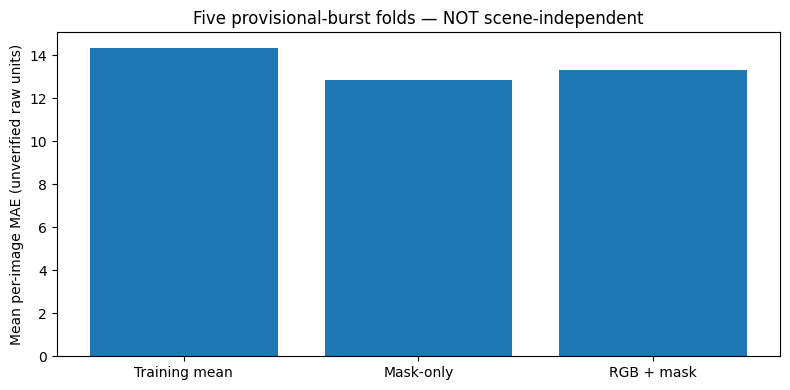


C3-08 SECTION 9 — SUPERVISED RGB/MASK ABLATION
File upload required: NO
Source verification: PASS
Paired out-of-fold predictions: 33/33
Training-only mean baseline MAE: 14.3572
Mask-only out-of-fold MAE: 12.8664
RGB+mask out-of-fold MAE: 13.3362
RGB wins: 15 /33
Final development checkpoints: 2
Checkpoint reload/inference: PASS
Independent scene validation: NO
Verified physical units: NO
Physical severity authorized: NO

Training results: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-08_section09_ROADNORMAL_RGB_ABLATION_20261021T010156_111282Z
Model checkpoints: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-08_section09_ROADNORMAL_RGB_ABLATION_20261021T010156_111282Z


In [ ]:

# ============================================================
# C3-08 SECTION 9
# TRAIN RGB + MASK VS MASK-ONLY ROAD-NORMAL MODELS
# NO FILE PICKER / NO FILE UPLOAD / FIXED GOOGLE DRIVE PATHS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import os, sys, csv, json, hashlib, shutil, random, time
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. AUTOMATICALLY LOCATE EXISTING RESEARCH FILES
# ------------------------------------------------------------

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

DATA_DIR = BASE / "04_geometry_targets" / (
    "C3-08_section08_GROUPED_ROADNORMAL_ML_HANDOFF_"
    "20261020T184716_733041Z"
)

ARCH_DIR = BASE / "06_model_checkpoints" / (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)

assert DATA_DIR.is_dir(), DATA_DIR
assert ARCH_DIR.is_dir(), ARCH_DIR


def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)

    return h.hexdigest()


def verify(folder, filename):
    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():
            digest, name = line.split(None, 1)
            name = name.strip()
            assert name not in expected
            expected[name] = digest

    assert filename in expected
    assert sha(folder / filename) == expected[filename]

    return expected[filename]


data_hash = verify(
    DATA_DIR, "roadnormal_development_33_raw.npz"
)

fold_hash = verify(
    DATA_DIR, "provisional_burst_development_folds.json"
)

protocol_hash = verify(
    DATA_DIR, "locked_protocol.json"
)

model_hash = verify(
    ARCH_DIR, "crdl_dev_model.py"
)

protocol = json.loads(
    (DATA_DIR / "locked_protocol.json").read_text()
)

folds = json.loads(
    (
        DATA_DIR
        / "provisional_burst_development_folds.json"
    ).read_text()
)

assert protocol["source_count"] == 33
assert protocol["metric_training_authorized"] is False
assert len(folds) == 5

with np.load(
    DATA_DIR / "roadnormal_development_33_raw.npz",
    allow_pickle=False
) as file:

    X160 = file["X"].astype("float32")
    Y160 = file["Y_raw"].astype("float32")
    W160 = file["W"].astype("float32")

    ids = file["sample_ids"].astype(str).tolist()
    groups = file["bursts"].astype(str).tolist()

    assert not bool(file["physical_units_verified"])

assert X160.shape == (33, 5, 160, 160)
assert Y160.shape == W160.shape == (33, 1, 160, 160)
assert ids == protocol["sample_order"]

print("Original Section 8 files: VERIFIED")


# ------------------------------------------------------------
# 2. PREPARE MATCHED TRAINING TENSORS
# ------------------------------------------------------------

SIZE = 96
BATCH = 4
EPOCHS = 10
LR = 0.002
SEED = 20261020

with torch.no_grad():

    X = F.interpolate(
        torch.from_numpy(X160),
        size=(SIZE, SIZE),
        mode="area"
    ).numpy()

    coverage = F.interpolate(
        torch.from_numpy(W160),
        size=(SIZE, SIZE),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(Y160 * W160),
        size=(SIZE, SIZE),
        mode="area"
    )

    mask96 = F.interpolate(
        torch.from_numpy(X160[:, 3:4]),
        size=(SIZE, SIZE),
        mode="nearest"
    )

    valid = (
        (coverage >= 0.90)
        & (mask96 > 0.5)
    ).float()

    Y = (
        numerator / coverage.clamp_min(1e-8)
        * valid
    ).numpy().astype("float32")

    W = valid.numpy().astype("float32")

assert X.shape == (33, 5, SIZE, SIZE)
assert Y.shape == W.shape == (33, 1, SIZE, SIZE)
assert np.isfinite(X).all()
assert np.isfinite(Y).all()
assert np.all(W.sum(axis=(1, 2, 3)) > 30)


# ------------------------------------------------------------
# 3. LOAD THE EXISTING ARCHITECTURE, NOT ITS WEIGHTS
# ------------------------------------------------------------

if str(ARCH_DIR) not in sys.path:
    sys.path.insert(0, str(ARCH_DIR))

from crdl_dev_model import CRDLDevUNet, encode_input

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if device.type == "cpu":
    torch.set_num_threads(
        min(2, os.cpu_count() or 1)
    )

if device.type == "cuda":
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Device:", device)
print("Training images:", len(ids))
print("Development folds:", len(folds))


# ------------------------------------------------------------
# 4. CREATE VERSIONED OUTPUT FOLDERS
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

name = (
    "C3-08_section09_ROADNORMAL_RGB_ABLATION_"
    + stamp
)

RUN = BASE / "05_training_runs" / name
CKPT = BASE / "06_model_checkpoints" / name

RUN.mkdir(parents=True, exist_ok=False)
CKPT.mkdir(parents=True, exist_ok=False)

shutil.copy2(
    ARCH_DIR / "crdl_dev_model.py",
    CKPT / "crdl_dev_model.py"
)

assert sha(CKPT / "crdl_dev_model.py") == model_hash

config = {
    "stage": "C3-08_SECTION09",
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH,
    "learning_rate": LR,
    "input_resolution": SIZE,
    "original_preprocessing_resolution": 160,
    "architecture": "CRDLDevUNet",
    "model_arms": ["rgb_mask", "mask_only"],
    "target": "CONDITIONAL_ROADNORMAL_UNVERIFIED_RAW",
    "target_normalization": (
        "95th percentile of valid pixels "
        "in training fold only"
    ),
    "validation": (
        "Five provisional capture-burst folds; "
        "NOT verified scene-independent"
    ),
    "hypothetical_focal_px": 600.0,
    "physical_units_verified": False,
    "severity_authorized": False,
    "previous_model_weights_reused": False,
    "source_checksums": {
        "dataset": data_hash,
        "folds": fold_hash,
        "protocol": protocol_hash,
        "architecture": model_hash
    }
}

(RUN / "experiment_config.json").write_text(
    json.dumps(config, indent=2)
)

(CKPT / "preprocessing_config.json").write_text(
    json.dumps(config, indent=2)
)


# ------------------------------------------------------------
# 5. REPRODUCIBLE TRAINING HELPERS
# ------------------------------------------------------------

def seed_all(value):
    random.seed(value)
    np.random.seed(value)
    torch.manual_seed(value)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(value)


def make_inputs(indices, arm):

    tensor = torch.from_numpy(
        np.array(X[indices], copy=True)
    )

    if arm == "mask_only":
        tensor[:, :3] = 0.0

    return tensor


def train_model(indices, arm, fold_tag):

    indices = np.asarray(indices, dtype=int)

    train_pixels = Y[indices][
        W[indices] > 0.5
    ]

    scale = float(
        np.percentile(train_pixels, 95)
    )

    baseline = float(
        np.mean(train_pixels)
    )

    assert np.isfinite(scale) and scale > 1

    fold_key = (
        int(fold_tag)
        if fold_tag != "full33"
        else 77
    )

    # Same initialization seed for both ablation arms.
    seed_all(SEED + 100 * fold_key)

    model = CRDLDevUNet().to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=1e-4
    )

    tx = make_inputs(indices, arm)
    ty = torch.from_numpy(Y[indices])
    tw = torch.from_numpy(W[indices])

    rng = np.random.default_rng(
        SEED + 100 * fold_key + 33
    )

    history = []
    start_time = time.perf_counter()

    for epoch in range(EPOCHS):

        model.train()

        order = rng.permutation(len(indices))
        total_loss = 0.0
        seen = 0

        for start in range(
            0, len(order), BATCH
        ):

            batch_indices = order[
                start:start + BATCH
            ]

            xb = tx[batch_indices].to(device)

            yb = (
                ty[batch_indices].to(device)
                / scale
            )

            wb = tw[batch_indices].to(device)

            optimizer.zero_grad(
                set_to_none=True
            )

            predicted = F.softplus(model(xb))

            loss_map = F.smooth_l1_loss(
                predicted,
                yb,
                beta=0.2,
                reduction="none"
            )

            loss = (
                (loss_map * wb).sum()
                / wb.sum().clamp_min(1)
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()

            total_loss += (
                float(loss.item())
                * len(batch_indices)
            )

            seen += len(batch_indices)

        history.append({
            "epoch": epoch + 1,
            "train_normalized_loss":
                total_loss / seen
        })

    elapsed = time.perf_counter() - start_time

    print(
        f"  {arm} / {fold_tag} | "
        f"{EPOCHS} epochs | "
        f"{elapsed:.1f}s | "
        f"training scale={scale:.3f}",
        flush=True
    )

    return model, scale, baseline, history


@torch.no_grad()
def predict_model(model, indices, arm, scale):

    model.eval()
    predictions = []

    for index in indices:

        inp = make_inputs(
            np.asarray([index]),
            arm
        ).to(device)

        pred = (
            F.softplus(model(inp)) * scale
        )

        predictions.append(
            pred[0, 0].cpu().numpy()
        )

    return np.stack(
        predictions
    ).astype("float32")


def save_checkpoint(
    path, model, scale, arm, indices, fold
):

    checkpoint = {
        "state_dict": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        "scale_raw": scale,
        "arm": arm,
        "train_ids": [ids[i] for i in indices],
        "fold": str(fold),
        "resolution": SIZE,
        "hypothetical_focal_px": 600.0,
        "target_units": "UNVERIFIED_RAW",
        "metric_calibrated": False,
        "severity_authorized": False,
        "source_handoff_sha256": data_hash,
        "architecture_sha256": model_hash
    }

    torch.save(checkpoint, path)

    # Verify that the saved model can be reloaded.
    loaded = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    test_model = CRDLDevUNet()

    test_model.load_state_dict(
        loaded["state_dict"],
        strict=True
    )

    assert loaded["scale_raw"] == scale
    assert loaded["metric_calibrated"] is False


# ------------------------------------------------------------
# 6. TRAIN TWO MODELS IN EACH OF FIVE FOLDS
# ------------------------------------------------------------

ARMS = ["rgb_mask", "mask_only"]

OOF = np.full(
    (2, 33, SIZE, SIZE),
    np.nan,
    dtype="float32"
)

results = []
histories = []

for fold in folds:

    fold_id = int(fold["fold_id"])

    train_indices = np.asarray(
        fold["train_indices"],
        dtype=int
    )

    val_indices = np.asarray(
        fold["validation_indices"],
        dtype=int
    )

    assert len(train_indices) + len(val_indices) == 33

    assert not (
        set(train_indices)
        & set(val_indices)
    )

    assert {
        groups[i] for i in val_indices
    } == {fold["validation_burst"]}

    print(
        f"\nFold {fold_id+1}/5 | "
        f"Validation burst: "
        f"{fold['validation_burst']}",
        flush=True
    )

    for arm_index, arm in enumerate(ARMS):

        model, scale, baseline, history = train_model(
            train_indices, arm, fold_id
        )

        pred = predict_model(
            model, val_indices, arm, scale
        )

        save_checkpoint(
            CKPT / f"fold{fold_id:02d}_{arm}.pt",
            model,
            scale,
            arm,
            train_indices,
            fold_id
        )

        histories.extend([
            {
                "fold": fold_id,
                "arm": arm,
                **item
            }
            for item in history
        ])

        for j, index in enumerate(val_indices):

            OOF[arm_index, index] = pred[j]

            use = W[index, 0] > 0.5

            truth = Y[index, 0][use]
            estimate = pred[j][use]

            assert use.sum() > 30
            assert np.isfinite(estimate).all()

            results.append({
                "fold": fold_id,
                "burst": groups[index],
                "sample_id": ids[index],
                "arm": arm,
                "train_only_scale_raw": scale,

                "mae_raw": float(
                    np.mean(
                        np.abs(estimate - truth)
                    )
                ),

                "rmse_raw": float(
                    np.sqrt(
                        np.mean(
                            (estimate - truth) ** 2
                        )
                    )
                ),

                "D95_absolute_error_raw": float(
                    abs(
                        np.percentile(estimate, 95)
                        - np.percentile(truth, 95)
                    )
                ),

                "train_mean_baseline_MAE_raw": float(
                    np.mean(
                        np.abs(truth - baseline)
                    )
                ),

                "valid_pixels": int(use.sum())
            })

        del model

        if device.type == "cuda":
            torch.cuda.empty_cache()

assert np.isfinite(OOF).all()


# ------------------------------------------------------------
# 7. GROUPED DEVELOPMENT EVALUATION
# ------------------------------------------------------------

summary = {}

for arm in ARMS:

    subset = [
        row for row in results
        if row["arm"] == arm
    ]

    assert len(subset) == 33

    summary[arm] = {
        "out_of_fold_MAE_raw": float(
            np.mean([
                row["mae_raw"] for row in subset
            ])
        ),

        "out_of_fold_RMSE_raw": float(
            np.mean([
                row["rmse_raw"] for row in subset
            ])
        ),

        "out_of_fold_D95_error_raw": float(
            np.mean([
                row["D95_absolute_error_raw"]
                for row in subset
            ])
        ),

        "per_burst": [
            {
                "burst": fold["validation_burst"],
                "n": fold["validation_count"],
                "MAE_raw": float(
                    np.mean([
                        row["mae_raw"]
                        for row in subset
                        if row["fold"] == fold["fold_id"]
                    ])
                )
            }
            for fold in folds
        ]
    }


baseline = float(
    np.mean([
        row["train_mean_baseline_MAE_raw"]
        for row in results
        if row["arm"] == "rgb_mask"
    ])
)

difference = (
    summary["mask_only"]["out_of_fold_MAE_raw"]
    - summary["rgb_mask"]["out_of_fold_MAE_raw"]
)

paired = {
    arm: {
        row["sample_id"]: row
        for row in results
        if row["arm"] == arm
    }
    for arm in ARMS
}

rgb_wins = sum(
    paired["rgb_mask"][sid]["mae_raw"]
    < paired["mask_only"][sid]["mae_raw"]
    for sid in ids
)

print("\nOut-of-fold development evaluation:")
print("Training-only mean baseline:", baseline)

for arm in ARMS:
    print(
        arm,
        summary[arm]["out_of_fold_MAE_raw"]
    )

print("RGB wins:", rgb_wins, "/33")


# ------------------------------------------------------------
# 8. TRAIN TWO FINAL DEVELOPMENT CHECKPOINTS
# ------------------------------------------------------------

for arm in ARMS:

    model, scale, _, history = train_model(
        np.arange(33),
        arm,
        "full33"
    )

    save_checkpoint(
        CKPT / f"full33_{arm}_DEVELOPMENT_ONLY.pt",
        model,
        scale,
        arm,
        np.arange(33),
        "full33"
    )

    histories.extend([
        {
            "fold": "full33",
            "arm": arm,
            **item
        }
        for item in history
    ])

    del model


# ------------------------------------------------------------
# 9. SAVE STANDALONE DEVELOPMENT INFERENCE
# ------------------------------------------------------------

inference_code = r'''
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
from crdl_dev_model import CRDLDevUNet, encode_input

def load_predictor(checkpoint_path):

    meta = torch.load(
        Path(checkpoint_path),
        map_location="cpu",
        weights_only=True
    )

    if (
        meta.get("metric_calibrated") is not False
        or meta.get("severity_authorized") is not False
    ):
        raise ValueError(
            "Expected development-only checkpoint"
        )

    model = CRDLDevUNet()

    model.load_state_dict(
        meta["state_dict"],
        strict=True
    )

    model.eval()
    return model, meta


@torch.no_grad()
def predict_raw(rgb_uint8, mask, checkpoint_path, confidence=1.0):

    mask = np.asarray(mask, dtype=bool)

    model, meta = load_predictor(checkpoint_path)

    x, geometry = encode_input(
        np.asarray(rgb_uint8),
        mask,
        confidence=confidence,
        size=160
    )

    x = F.interpolate(
        x[None],
        size=(int(meta["resolution"]),)*2,
        mode="area"
    )

    if meta["arm"] == "mask_only":
        x[:, :3] = 0

    pred = (
        F.softplus(model(x))
        * float(meta["scale_raw"])
    )

    pred = F.interpolate(
        pred,
        size=(160, 160),
        mode="bilinear",
        align_corners=False
    )[0, 0]

    nh, nw = geometry["resized_hw"]
    top = geometry["pad_top"]
    left = geometry["pad_left"]

    pred = pred[
        top:top+nh,
        left:left+nw
    ][None, None]

    h, w = geometry["original_hw"]

    pred = F.interpolate(
        pred,
        size=(h, w),
        mode="bilinear",
        align_corners=False
    )[0, 0].numpy()

    pred = np.maximum(pred, 0).astype("float32")
    pred[~mask] = 0

    return {
        "depression_map_unverified_raw": pred,
        "physical_units_verified": False,
        "physical_measurement_status":
            "UNSUPPORTED_UNCALIBRATED",
        "severity": None,
        "model_arm": meta["arm"],
        "hypothetical_focal_px":
            meta["hypothetical_focal_px"]
    }
'''

(CKPT / "development_inference.py").write_text(
    inference_code
)

if str(CKPT) not in sys.path:
    sys.path.insert(0, str(CKPT))

from development_inference import (
    load_predictor,
    predict_raw
)

smoke_rgb = np.clip(
    X160[0, :3].transpose(1, 2, 0) * 255,
    0, 255
).astype("uint8")

smoke_mask = X160[0, 3] > 0.5

for arm in ARMS:

    checkpoint_path = (
        CKPT
        / f"full33_{arm}_DEVELOPMENT_ONLY.pt"
    )

    reloaded, meta = load_predictor(
        checkpoint_path
    )

    smoke = predict_raw(
        smoke_rgb,
        smoke_mask,
        checkpoint_path
    )

    output = smoke[
        "depression_map_unverified_raw"
    ]

    assert output.shape == smoke_mask.shape
    assert np.isfinite(output).all()
    assert np.all(output[~smoke_mask] == 0)

    assert smoke[
        "physical_measurement_status"
    ] == "UNSUPPORTED_UNCALIBRATED"

print("Final model inference smoke tests: PASS")


# ------------------------------------------------------------
# 10. SAVE DEVELOPMENT PREDICTIONS AND REPORTS
# ------------------------------------------------------------

with (
    RUN / "oof_predictions.csv"
).open("w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(results[0])
    )

    writer.writeheader()

    writer.writerows(
        sorted(
            results,
            key=lambda r: (
                r["sample_id"], r["arm"]
            )
        )
    )

with (
    RUN / "training_history.csv"
).open("w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(histories[0])
    )

    writer.writeheader()
    writer.writerows(histories)


np.savez_compressed(
    RUN / "oof_predictions_96_DEVELOPMENT_ONLY.npz",
    rgb_mask=OOF[0],
    mask_only=OOF[1],
    target_raw=Y[:, 0],
    valid_mask=W[:, 0],
    sample_ids=np.array(ids),
    bursts=np.array(groups),
    physical_units_verified=np.array(False)
)

report = {
    "stage": "C3-08_SECTION09",
    "summary": summary,

    "train_mean_baseline_MAE_raw": baseline,

    "mask_minus_rgb_MAE_raw": difference,

    "rgb_better_images": rgb_wins,
    "n_samples": 33,
    "fold_count": 5,

    "verified_independent_scenes": False,
    "ground_truth_masks_used": True,

    "target_units": "UNVERIFIED_RAW",
    "metric_depth_authorized": False,
    "severity_authorized": False,

    "checkpoint_reload_smoke": "PASS",

    "interpretation": (
        "Grouped development experiment only. "
        "Not independently verified physical depth."
    )
}

(RUN / "ablation_report.json").write_text(
    json.dumps(report, indent=2)
)


# ------------------------------------------------------------
# 11. VISUALIZE BOTH MODEL RESULTS
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    [
        "Training mean",
        "Mask-only",
        "RGB + mask"
    ],
    [
        baseline,
        summary["mask_only"]["out_of_fold_MAE_raw"],
        summary["rgb_mask"]["out_of_fold_MAE_raw"]
    ]
)

ax.set_ylabel(
    "Mean per-image MAE (unverified raw units)"
)

ax.set_title(
    "Five provisional-burst folds — NOT scene-independent"
)

fig.tight_layout()

fig.savefig(
    RUN / "grouped_rgb_ablation.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 12. SAVE ARTIFACT CHECKSUMS
# ------------------------------------------------------------

def checksum_tree(root):

    with (
        root / "checksums.sha256"
    ).open("w") as file:

        for path in sorted(root.rglob("*")):

            if (
                path.is_file()
                and path.name != "checksums.sha256"
            ):

                file.write(
                    f"{sha(path)}  "
                    f"{path.relative_to(root).as_posix()}\n"
                )


checksum_tree(RUN)
checksum_tree(CKPT)


# ------------------------------------------------------------
# 13. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("C3-08 SECTION 9 — SUPERVISED RGB/MASK ABLATION")
print("=" * 70)

print("File upload required: NO")
print("Source verification: PASS")

print("Paired out-of-fold predictions: 33/33")

print(
    "Training-only mean baseline MAE:",
    round(baseline, 4)
)

print(
    "Mask-only out-of-fold MAE:",
    round(
        summary["mask_only"]["out_of_fold_MAE_raw"], 4
    )
)

print(
    "RGB+mask out-of-fold MAE:",
    round(
        summary["rgb_mask"]["out_of_fold_MAE_raw"], 4
    )
)

print("RGB wins:", rgb_wins, "/33")
print("Final development checkpoints: 2")
print("Checkpoint reload/inference: PASS")

print("Independent scene validation: NO")
print("Verified physical units: NO")
print("Physical severity authorized: NO")

print("\nTraining results:", RUN)
print("Model checkpoints:", CKPT)

print("=" * 70)


Section 8 and 9 source integrity: PASS
Fold 1/5 | rgb_mask: COMPLETE
Fold 1/5 | mask_only: COMPLETE
Fold 2/5 | rgb_mask: COMPLETE
Fold 2/5 | mask_only: COMPLETE
Fold 3/5 | rgb_mask: COMPLETE
Fold 3/5 | mask_only: COMPLETE
Fold 4/5 | rgb_mask: COMPLETE
Fold 4/5 | mask_only: COMPLETE
Fold 5/5 | rgb_mask: COMPLETE
Fold 5/5 | mask_only: COMPLETE

Original OOF checkpoint reproduction: PASS


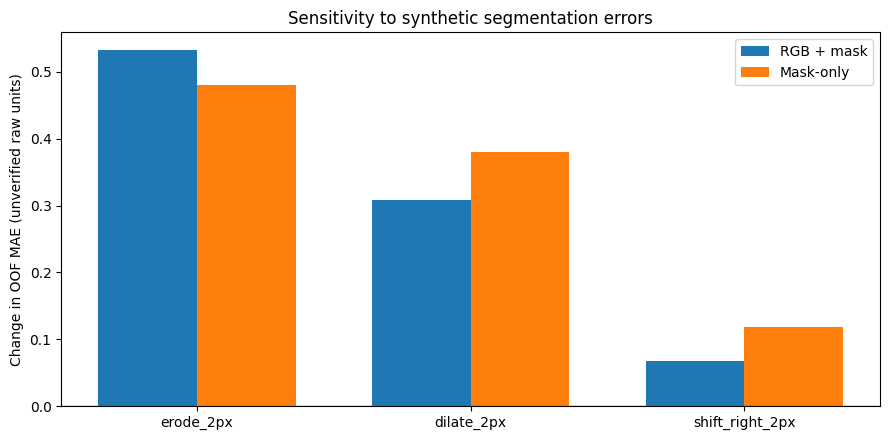


C3-08 SECTION 10 — SEGMENTATION ROBUSTNESS
Source checkpoints verified: PASS
Original OOF reproduced: PASS
Inference runs: 264

original
  rgb_mask   | MAE=13.336 | delta=+0.000 | worsened=0/33
  mask_only  | MAE=12.866 | delta=+0.000 | worsened=0/33

erode_2px
  rgb_mask   | MAE=13.869 | delta=+0.533 | worsened=23/33
  mask_only  | MAE=13.346 | delta=+0.480 | worsened=21/33

dilate_2px
  rgb_mask   | MAE=13.645 | delta=+0.309 | worsened=21/33
  mask_only  | MAE=13.246 | delta=+0.380 | worsened=19/33

shift_right_2px
  rgb_mask   | MAE=13.404 | delta=+0.067 | worsened=20/33
  mask_only  | MAE=12.984 | delta=+0.118 | worsened=21/33

Actual teammate masks used: NO
Physical units verified: NO
New model training: NO
Physical severity authorized: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-08_section10_MASK_ROBUSTNESS_20261021T011449_572970Z


In [ ]:

# ============================================================
# C3-08 SECTION 10 — SEGMENTATION ROBUSTNESS EXPERIMENT
#
# Out-of-fold RGB vs mask-only models
# Synthetic segmentation boundary perturbations
# No new training, no manual file selection
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
import importlib.util
import hashlib, json, csv, sys

import numpy as np
import torch
import torch.nn.functional as F
from scipy.ndimage import binary_erosion, binary_dilation
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

NAME8 = (
    "C3-08_section08_GROUPED_ROADNORMAL_ML_HANDOFF_"
    "20261020T184716_733041Z"
)

NAME9 = (
    "C3-08_section09_ROADNORMAL_RGB_ABLATION_"
    "20261021T010156_111282Z"
)

DATA = BASE / "04_geometry_targets" / NAME8
RUN = BASE / "05_training_runs" / NAME9
CKPT = BASE / "06_model_checkpoints" / NAME9

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for folder in (DATA, RUN, CKPT):
    assert folder.is_dir(), folder


# ------------------------------------------------------------
# 1. SOURCE INTEGRITY
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def check(folder, filename):
    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():
            digest, name = line.split(None, 1)
            expected[name.strip()] = digest

    assert filename in expected
    assert sha(folder / filename) == expected[filename]

    return expected[filename]


data_sha = check(
    DATA, "roadnormal_development_33_raw.npz"
)

fold_sha = check(
    DATA, "provisional_burst_development_folds.json"
)

oof_sha = check(
    RUN, "oof_predictions_96_DEVELOPMENT_ONLY.npz"
)

check(RUN, "ablation_report.json")
check(CKPT, "crdl_dev_model.py")

source_report = json.loads(
    (RUN / "ablation_report.json").read_text()
)

folds = json.loads(
    (
        DATA
        / "provisional_burst_development_folds.json"
    ).read_text()
)

assert len(folds) == 5

with np.load(
    DATA / "roadnormal_development_33_raw.npz",
    allow_pickle=False
) as f:

    X160 = f["X"].astype("float32")
    Y160 = f["Y_raw"].astype("float32")
    W160 = f["W"].astype("float32")

    ids = f["sample_ids"].astype(str).tolist()
    groups = f["bursts"].astype(str).tolist()

    assert not bool(f["physical_units_verified"])

with np.load(
    RUN / "oof_predictions_96_DEVELOPMENT_ONLY.npz",
    allow_pickle=False
) as f:

    original_oof = {
        "rgb_mask": f["rgb_mask"].copy(),
        "mask_only": f["mask_only"].copy()
    }

    assert f["sample_ids"].astype(str).tolist() == ids

    assert f["bursts"].astype(str).tolist() == groups

    assert not bool(f["physical_units_verified"])

assert X160.shape == (33, 5, 160, 160)
assert Y160.shape == W160.shape == (33, 1, 160, 160)

print("Section 8 and 9 source integrity: PASS")


# ------------------------------------------------------------
# 2. RECONSTRUCT THE IDENTICAL 96x96 INPUTS
# ------------------------------------------------------------

SIZE = 96

with torch.no_grad():

    X = F.interpolate(
        torch.from_numpy(X160),
        size=(SIZE, SIZE),
        mode="area"
    ).numpy()

    coverage = F.interpolate(
        torch.from_numpy(W160),
        size=(SIZE, SIZE),
        mode="area"
    )

    numerator = F.interpolate(
        torch.from_numpy(Y160 * W160),
        size=(SIZE, SIZE),
        mode="area"
    )

    mask96 = F.interpolate(
        torch.from_numpy(X160[:, 3:4]),
        size=(SIZE, SIZE),
        mode="nearest"
    )

    valid = (
        (coverage >= 0.90)
        & (mask96 > 0.5)
    ).float()

    Y = (
        numerator / coverage.clamp_min(1e-8)
        * valid
    ).numpy()

    W = valid.numpy()

assert X.shape == (33, 5, 96, 96)
assert Y.shape == W.shape == (33, 1, 96, 96)


# ------------------------------------------------------------
# 3. LOAD ARCHITECTURE FROM ITS VERIFIED PATH
# ------------------------------------------------------------

module_path = CKPT / "crdl_dev_model.py"

spec = importlib.util.spec_from_file_location(
    "c308_section10_architecture",
    module_path
)

architecture = importlib.util.module_from_spec(spec)
spec.loader.exec_module(architecture)

CRDLDevUNet = architecture.CRDLDevUNet

torch.set_num_threads(2)

device = torch.device("cpu")


# ------------------------------------------------------------
# 4. DEFINE SYNTHETIC MASK PERTURBATIONS
# ------------------------------------------------------------

CONDITIONS = [
    "original",
    "erode_2px",
    "dilate_2px",
    "shift_right_2px"
]


def perturb(mask, condition):

    m = np.asarray(mask, dtype=bool)

    if condition == "original":
        return m.copy()

    if condition == "erode_2px":
        return binary_erosion(
            m, iterations=2
        )

    if condition == "dilate_2px":
        return binary_dilation(
            m, iterations=2
        )

    if condition == "shift_right_2px":

        shifted = np.zeros_like(m)
        shifted[:, 2:] = m[:, :-2]
        return shifted

    raise ValueError(condition)


def iou(a, b):

    intersection = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()

    return float(
        intersection / max(union, 1)
    )


# ------------------------------------------------------------
# 5. RUN OUT-OF-FOLD SEGMENTATION ROBUSTNESS
# ------------------------------------------------------------

ARMS = ["rgb_mask", "mask_only"]

results = []
baseline_rechecks = []

for fold in folds:

    fold_id = int(fold["fold_id"])
    train_indices = fold["train_indices"]
    val_indices = fold["validation_indices"]

    assert set(train_indices).isdisjoint(
        val_indices
    )

    for arm in ARMS:

        checkpoint_name = (
            f"fold{fold_id:02d}_{arm}.pt"
        )

        check(CKPT, checkpoint_name)

        meta = torch.load(
            CKPT / checkpoint_name,
            map_location=device,
            weights_only=True
        )

        assert meta["arm"] == arm
        assert meta["metric_calibrated"] is False
        assert meta["severity_authorized"] is False

        assert meta["source_handoff_sha256"] == data_sha

        assert meta["architecture_sha256"] == sha(
            module_path
        )

        assert meta["resolution"] == SIZE

        training_ids = set(meta["train_ids"])

        assert training_ids == {
            ids[i] for i in train_indices
        }

        assert training_ids.isdisjoint({
            ids[i] for i in val_indices
        })

        model = CRDLDevUNet()

        model.load_state_dict(
            meta["state_dict"],
            strict=True
        )

        model.eval()

        scale = float(meta["scale_raw"])

        for index in val_indices:

            original_mask = (
                X[index, 3] > 0.5
            )

            truth = Y[index, 0]
            evaluate = W[index, 0] > 0.5

            assert evaluate.sum() > 30

            for condition in CONDITIONS:

                modified = perturb(
                    original_mask,
                    condition
                )

                assert modified.any()

                inp = np.array(
                    X[index:index+1],
                    copy=True
                )

                if arm == "mask_only":
                    inp[:, :3] = 0.0

                if condition != "original":
                    inp[0, 3] = (
                        modified.astype("float32")
                    )

                with torch.inference_mode():

                    predicted = (
                        F.softplus(
                            model(
                                torch.from_numpy(inp)
                            )
                        ) * scale
                    )[0, 0].numpy()

                assert np.isfinite(predicted).all()

                mae = float(np.mean(
                    np.abs(
                        predicted[evaluate]
                        - truth[evaluate]
                    )
                ))

                d95_error = float(abs(
                    np.percentile(
                        predicted[evaluate], 95
                    )
                    - np.percentile(
                        truth[evaluate], 95
                    )
                ))

                if condition == "original":

                    saved = original_oof[arm][index]

                    # Prove that this code reproduces
                    # the previously evaluated model.
                    max_difference = float(
                        np.max(
                            np.abs(predicted - saved)
                        )
                    )

                    assert max_difference < 0.01, (
                        "Original OOF predictions "
                        "not reproduced."
                    )

                    baseline_rechecks.append(
                        max_difference
                    )

                results.append({
                    "sample_id": ids[index],
                    "fold": fold_id,
                    "burst": groups[index],
                    "arm": arm,
                    "condition": condition,

                    "mask_iou": iou(
                        original_mask, modified
                    ),

                    "mae_raw": mae,
                    "D95_error_raw": d95_error,

                    "original_valid_pixels": int(
                        evaluate.sum()
                    ),

                    "metric_units_verified": False
                })

        print(
            f"Fold {fold_id+1}/5 | {arm}: COMPLETE",
            flush=True
        )


assert len(results) == (
    33 * len(ARMS) * len(CONDITIONS)
)

assert len(baseline_rechecks) == 66

print(
    "\nOriginal OOF checkpoint reproduction: PASS"
)


# ------------------------------------------------------------
# 6. MEASURE CHANGE IN ERROR FROM EACH MASK PERTURBATION
# ------------------------------------------------------------

lookup = {
    (
        r["sample_id"],
        r["arm"],
        r["condition"]
    ): r
    for r in results
}

for r in results:

    original = lookup[
        (
            r["sample_id"],
            r["arm"],
            "original"
        )
    ]

    r["delta_mae_raw"] = float(
        r["mae_raw"] - original["mae_raw"]
    )

    r["delta_D95_error_raw"] = float(
        r["D95_error_raw"]
        - original["D95_error_raw"]
    )

summary = {}

for arm in ARMS:

    summary[arm] = {}

    for condition in CONDITIONS:

        subset = [
            r for r in results
            if (
                r["arm"] == arm
                and r["condition"] == condition
            )
        ]

        assert len(subset) == 33

        summary[arm][condition] = {
            "n": 33,

            "mean_mask_iou": float(
                np.mean([
                    r["mask_iou"]
                    for r in subset
                ])
            ),

            "mean_MAE_raw": float(
                np.mean([
                    r["mae_raw"]
                    for r in subset
                ])
            ),

            "mean_delta_MAE_raw": float(
                np.mean([
                    r["delta_mae_raw"]
                    for r in subset
                ])
            ),

            "mean_D95_error_raw": float(
                np.mean([
                    r["D95_error_raw"]
                    for r in subset
                ])
            ),

            "worsened_MAE_images": sum(
                r["delta_mae_raw"] > 0
                for r in subset
            )
        }

    prior_mae = float(
        source_report["summary"][arm][
            "out_of_fold_MAE_raw"
        ]
    )

    now_mae = summary[arm][
        "original"
    ]["mean_MAE_raw"]

    assert abs(prior_mae - now_mae) < 0.01


# ------------------------------------------------------------
# 7. CREATE VERSIONED OUTPUTS
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "07_evaluation" / (
    "C3-08_section10_MASK_ROBUSTNESS_"
    + stamp
)

OUT.mkdir(parents=True, exist_ok=False)

report = {
    "stage": "C3-08_SECTION10",
    "experiment": (
        "Synthetic segmentation perturbations "
        "on never-trained-on fold images"
    ),

    "source_checksums": {
        "section08_dataset": data_sha,
        "section08_folds": fold_sha,
        "section09_oof": oof_sha
    },

    "perturbations": CONDITIONS,
    "results": summary,

    "source_model_predictions_reproduced": True,
    "total_inference_runs": len(results),

    "no_new_training": True,
    "actual_predicted_masks_tested": False,
    "ground_truth_labels_from_original_masks": True,
    "independent_scene_validation": False,
    "physical_units_verified": False,
    "physical_severity_authorized": False,

    "interpretation_limit": (
        "This measures sensitivity to controlled "
        "segmentation errors on existing development "
        "references, not real teammate-segmentation "
        "performance or physical depth accuracy."
    )
}

(
    OUT / "robustness_report.json"
).write_text(
    json.dumps(report, indent=2)
)

with (
    OUT / "all33_mask_robustness.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(results[0])
    )

    writer.writeheader()
    writer.writerows(results)


# ------------------------------------------------------------
# 8. VISUALIZE ERROR SENSITIVITY
# ------------------------------------------------------------

conditions = CONDITIONS[1:]

positions = np.arange(len(conditions))
width = 0.36

rgb_changes = [
    summary["rgb_mask"][c][
        "mean_delta_MAE_raw"
    ]
    for c in conditions
]

mask_changes = [
    summary["mask_only"][c][
        "mean_delta_MAE_raw"
    ]
    for c in conditions
]

fig, ax = plt.subplots(
    figsize=(9, 4.5)
)

ax.bar(
    positions-width/2,
    rgb_changes,
    width,
    label="RGB + mask"
)

ax.bar(
    positions+width/2,
    mask_changes,
    width,
    label="Mask-only"
)

ax.axhline(0, linewidth=1)

ax.set_xticks(
    positions,
    conditions
)

ax.set_ylabel(
    "Change in OOF MAE (unverified raw units)"
)

ax.set_title(
    "Sensitivity to synthetic segmentation errors"
)

ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "mask_robustness_comparison.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 9. SAVE CHECKSUMS
# ------------------------------------------------------------

lines = []

for file in sorted(OUT.iterdir()):

    if (
        file.is_file()
        and file.name != "checksums.sha256"
    ):

        lines.append(
            f"{sha(file)}  {file.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("C3-08 SECTION 10 — SEGMENTATION ROBUSTNESS")
print("=" * 68)

print("Source checkpoints verified: PASS")
print("Original OOF reproduced: PASS")
print("Inference runs:", len(results))

for condition in CONDITIONS:

    print(f"\n{condition}")

    for arm in ARMS:

        item = summary[arm][condition]

        print(
            f"  {arm:10s} | "
            f"MAE={item['mean_MAE_raw']:.3f} | "
            f"delta={item['mean_delta_MAE_raw']:+.3f} | "
            f"worsened={item['worsened_MAE_images']}/33"
        )

print("\nActual teammate masks used: NO")
print("Physical units verified: NO")
print("New model training: NO")
print("Physical severity authorized: NO")

print("\nSaved:", OUT)
print("=" * 68)


Pothole440 TRAIN file counts
RGB: 350
Mask: 350
Depth: 350
Matched triplets: 350
Likely distinct original pothole families: 98
Augmented/related filenames: 252
Selected independent filename families: 12
01/12 | 2022_05_22_pothole_10.png | uint8 | range 0–175 | unique=176
02/12 | 2022_05_22_pothole_18.png | uint8 | range 85–169 | unique=84
03/12 | 2022_05_23_pothole_2.png | uint8 | range 9–178 | unique=170
04/12 | 2022_05_25_pothole_8.png | uint8 | range 104–164 | unique=61
05/12 | 2022_06_01_pothole_18.png | uint8 | range 78–168 | unique=91
06/12 | 2022_06_01_pothole_3.png | uint8 | range 90–179 | unique=90
07/12 | 2022_06_02_pothole_4.png | uint8 | range 82–176 | unique=95
08/12 | 2022_06_03_pothole_14_horizantal.png | uint8 | range 66–153 | unique=88
09/12 | 2022_06_03_pothole_22_horizantal_vertical.png | uint8 | range 63–174 | unique=112
10/12 | 2022_06_03_pothole_30.png | uint8 | range 41–186 | unique=146
11/12 | 2022_06_03_pothole_7.png | uint8 | range 62–160 | unique=99
12/12 | 2

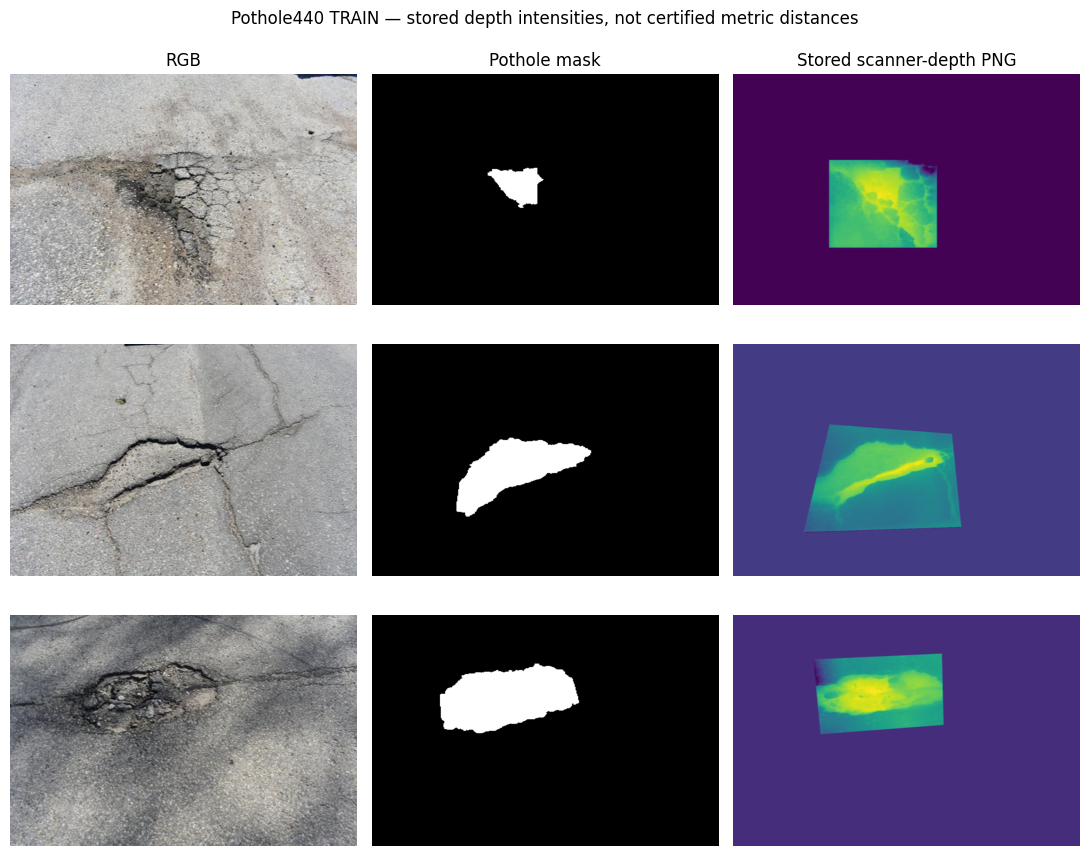


C3-08 SECTION 11 — POTHOLE440 SCANNER LABEL AUDIT
Matched training triplets: 350
Likely original pothole families: 98
Scanner-label examples inspected: 12
Depth dtypes: {'uint8': 12}
Depth PNG modes: {'L': 12}
All sampled maps 8-bit: True
Embedded depth metadata detected: False
Depth range median: 92.0
Official validation/test data read: NO
Millimetres per PNG intensity verified: NO
Metric training authorized: NO
Source-image checksums: SAVED

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-08_section11_POTHOLE440_TRAIN_ENCODING_20261021T012300_005447Z


In [ ]:

# ============================================================
# C3-08 SECTION 11 — POTHOLE440 SCANNER LABEL AUDIT
#
# Fixed Google Drive paths. No file picker.
# TRAIN split only — val/test remain untouched.
# Read-only inspection of source data.
# CPU / limited-RAM safe.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import hashlib, re, csv, json

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

ROOT = Path(
    "/content/drive/MyDrive/"
    "manushi_research_data/Pothole440-main"
)

if not ROOT.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

assert BASE.is_dir()
assert ROOT.is_dir()

TRAIN = ROOT / "train"

RGB_DIR = TRAIN / "rgb"
MASK_DIR = TRAIN / "mask"
DEPTH_DIR = TRAIN / "depth"

for folder in (RGB_DIR, MASK_DIR, DEPTH_DIR):
    assert folder.is_dir(), folder


# ------------------------------------------------------------
# 1. FILE INTEGRITY HELPER
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


# ------------------------------------------------------------
# 2. INDEX TRAINING FILES ONLY
# ------------------------------------------------------------

def png_files(folder):
    result = {}

    for path in folder.iterdir():
        if path.is_file() and path.suffix.lower() == ".png":
            assert path.name not in result
            result[path.name] = path

    return result


rgb_files = png_files(RGB_DIR)
mask_files = png_files(MASK_DIR)
depth_files = png_files(DEPTH_DIR)

rgb_names = set(rgb_files)
mask_names = set(mask_files)
depth_names = set(depth_files)

matched_names = sorted(
    rgb_names & mask_names & depth_names
)

missing = {
    "rgb_without_complete_triplet": sorted(
        rgb_names - (mask_names & depth_names)
    ),
    "mask_without_complete_triplet": sorted(
        mask_names - (rgb_names & depth_names)
    ),
    "depth_without_complete_triplet": sorted(
        depth_names - (rgb_names & mask_names)
    )
}

print("Pothole440 TRAIN file counts")
print("RGB:", len(rgb_names))
print("Mask:", len(mask_names))
print("Depth:", len(depth_names))
print("Matched triplets:", len(matched_names))

assert len(matched_names) > 20, (
    "Not enough matched samples: inspect dataset."
)


# ------------------------------------------------------------
# 3. GROUP LIKELY AUGMENTATIONS OF SAME POTHOLE
# ------------------------------------------------------------

def original_group(filename):

    name = Path(filename).stem

    while True:
        previous = name

        name = re.sub(
            r"_aug\d+$", "", name,
            flags=re.IGNORECASE
        )

        name = re.sub(
            r"_(horizantal_vertical|horizontal_vertical"
            r"|horizantal|horizontal|vertical)$",
            "", name, flags=re.IGNORECASE
        )

        if name == previous:
            break

    return name


families = defaultdict(list)

for filename in matched_names:
    families[original_group(filename)].append(filename)

print("Likely distinct original pothole families:",
      len(families))

print("Augmented/related filenames:",
      len(matched_names) - len(families))


# ------------------------------------------------------------
# 4. PRESELECT 12 DIFFERENT POTHOLE FAMILIES
# ------------------------------------------------------------

# Prefer a nonaugmented original image.
# No depth values are examined before selection.

representatives = []

for group in sorted(families):

    choices = sorted(
        families[group],
        key=lambda name: (
            Path(name).stem != group,
            "_aug" in name.lower(),
            name
        )
    )

    representatives.append({
        "group": group,
        "filename": choices[0],
        "family_size": len(families[group])
    })

N = min(12, len(representatives))

assert N >= 5

selection_indices = np.linspace(
    0, len(representatives) - 1,
    N, dtype=int
)

selected = [
    representatives[int(i)]
    for i in selection_indices
]

assert len({
    s["group"] for s in selected
}) == len(selected)

print("Selected independent filename families:", N)


# ------------------------------------------------------------
# 5. CREATE VERSIONED AUDIT OUTPUT
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "02_dataset_audits" / (
    "C3-08_section11_POTHOLE440_TRAIN_ENCODING_"
    + stamp
)

OUT.mkdir(parents=True, exist_ok=False)

protocol = {
    "stage": "C3-08_SECTION11",
    "source": str(ROOT),

    "examined_split": "train",
    "validation_split_accessed": False,
    "test_split_accessed": False,
    "frozen_399_benchmark_accessed": False,

    "sampling": (
        "Evenly spaced representatives of "
        "distinct inferred augmentation families"
    ),

    "selected_filenames": [
        x["filename"] for x in selected
    ],

    "reference_units_verified": False,
    "metric_model_training_authorized": False,
    "model_training_performed": False,

    "warning": (
        "Scanner-derived PNG intensity values "
        "are not automatically physical depths. "
        "Augmentation-family groups are filename "
        "heuristics, not verified independent scenes."
    )
}

(
    OUT / "locked_protocol.json"
).write_text(
    json.dumps(protocol, indent=2)
)


# ------------------------------------------------------------
# 6. INSPECT ACTUAL RGB / MASK / DEPTH TRIPLETS
# ------------------------------------------------------------

records = []
previews = []

for number, chosen in enumerate(selected, 1):

    name = chosen["filename"]

    paths = {
        "rgb": rgb_files[name],
        "mask": mask_files[name],
        "depth": depth_files[name]
    }

    with Image.open(paths["rgb"]) as im:
        rgb_mode = im.mode
        rgb = np.asarray(
            im.convert("RGB")
        ).copy()

    with Image.open(paths["mask"]) as im:
        mask_mode = im.mode
        mask = np.asarray(
            im.convert("L")
        ).copy()

    with Image.open(paths["depth"]) as im:
        depth_mode = im.mode
        depth_info_keys = sorted(
            str(key) for key in im.info.keys()
        )
        depth = np.asarray(im).copy()

    assert depth.ndim == 2, (
        f"Unexpected multichannel depth: {name}"
    )

    assert rgb.shape[:2] == mask.shape
    assert depth.shape == mask.shape

    mask_values = np.unique(mask)

    # Only binary mask encodings are accepted.
    assert len(mask_values) == 2, (
        f"Unexpected mask encoding: {name}"
    )

    assert mask_values[0] == 0

    foreground = mask > 0

    assert foreground.sum() > 100
    assert (~foreground).sum() > 100

    inside = depth[foreground].astype("float64")
    outside = depth[~foreground].astype("float64")

    unique_depth = np.unique(depth)

    outside_values, outside_counts = np.unique(
        depth[~foreground],
        return_counts=True
    )

    outside_mode = float(
        outside_values[
            np.argmax(outside_counts)
        ]
    )

    row = {
        "sample": name,
        "inferred_original_group": chosen["group"],
        "family_size": chosen["family_size"],

        "rgb_mode": rgb_mode,
        "mask_mode": mask_mode,
        "depth_mode": depth_mode,

        "depth_dtype": str(depth.dtype),
        "height": depth.shape[0],
        "width": depth.shape[1],

        "mask_values": mask_values.tolist(),
        "mask_fraction": float(
            foreground.mean()
        ),

        "depth_min": float(depth.min()),
        "depth_max": float(depth.max()),

        "depth_unique_values": int(
            len(unique_depth)
        ),

        "depth_inside_p05": float(
            np.percentile(inside, 5)
        ),

        "depth_inside_p50": float(
            np.median(inside)
        ),

        "depth_inside_p95": float(
            np.percentile(inside, 95)
        ),

        "depth_outside_p50": float(
            np.median(outside)
        ),

        "depth_outside_mode": outside_mode,

        "outside_modal_fraction": float(
            np.mean(
                depth[~foreground] == outside_mode
            )
        ),

        "depth_png_metadata_keys":
            depth_info_keys,

        "rgb_sha256": sha(paths["rgb"]),
        "mask_sha256": sha(paths["mask"]),
        "depth_sha256": sha(paths["depth"]),

        "physical_units_verified": False,
        "scanner_to_png_conversion_known": False
    }

    records.append(row)

    if len(previews) < 3:

        previews.append((
            name, rgb, foreground.copy(), depth
        ))

    print(
        f"{number:02d}/{N} | "
        f"{name} | "
        f"{depth.dtype} | "
        f"range {depth.min()}–{depth.max()} | "
        f"unique={len(unique_depth)}",
        flush=True
    )


# ------------------------------------------------------------
# 7. SUMMARY OF TRAINING-LABEL ENCODING
# ------------------------------------------------------------

dtypes = dict(
    Counter(r["depth_dtype"] for r in records)
)

modes = dict(
    Counter(r["depth_mode"] for r in records)
)

range_values = [
    r["depth_max"] - r["depth_min"]
    for r in records
]

all_8bit = all(
    r["depth_dtype"] == "uint8"
    for r in records
)

any_embedded_metadata = any(
    bool(r["depth_png_metadata_keys"])
    for r in records
)

summary = {
    "train_rgb_count": len(rgb_names),
    "train_mask_count": len(mask_names),
    "train_depth_count": len(depth_names),

    "matched_train_triplets": len(matched_names),

    "inferred_original_families": len(families),

    "sampled_families": len(records),

    "depth_dtypes": dtypes,
    "depth_modes": modes,

    "all_sampled_depths_uint8": all_8bit,

    "any_sampled_depth_png_metadata":
        any_embedded_metadata,

    "depth_dynamic_range_median": float(
        np.median(range_values)
    ),

    "missing_triplets": {
        k: len(v)
        for k, v in missing.items()
    },

    "original_scanner_depth_maps_reported": True,

    "dataset_specific_mm_per_png_value_verified":
        False,

    "cross_image_depth_normalization_known":
        False,

    "source_3d_scanner_to_png_mapping_verified":
        False,

    "metric_training_authorized": False,

    "training_recommendation": (
        "Do not treat PNG intensity as mm until "
        "the scanner-to-image encoding is verified."
    )
}


# ------------------------------------------------------------
# 8. SAVE DATASET GROUP AND LABEL REPORTS
# ------------------------------------------------------------

(
    OUT / "encoding_report.json"
).write_text(
    json.dumps({
        "summary": summary,
        "selected_records": records,
        "unmatched_filenames": missing,

        "known_source": (
            "Pothole440 public dataset README "
            "describes depth maps originating "
            "from Go!SCAN 3D scanner data."
        ),

        "scientific_limit": (
            "Scanner acquisition provenance "
            "does not prove the downloadable "
            "PNG pixel intensity is an "
            "absolute physical depth value."
        )
    }, indent=2)
)

with (
    OUT / "sample_encoding_profiles.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(records[0])
    )

    writer.writeheader()
    writer.writerows({
        k: json.dumps(v)
        if isinstance(v, list) else v
        for k, v in row.items()
    } for row in records)

with (
    OUT / "train_augmentation_families.csv"
).open("w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "inferred_original_group",
        "filename",
        "family_size"
    ])

    for group, filenames in sorted(
        families.items()
    ):

        for filename in sorted(filenames):
            writer.writerow([
                group, filename, len(filenames)
            ])


# ------------------------------------------------------------
# 9. VISUALIZE THREE SCANNER-DEPTH EXAMPLES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 3,
    figsize=(11, 9)
)

for i, (name, rgb, mask, depth) in enumerate(
    previews
):

    axes[i, 0].imshow(rgb)

    axes[i, 1].imshow(
        mask,
        cmap="gray",
        vmin=0, vmax=1
    )

    axes[i, 2].imshow(
        depth,
        cmap="viridis"
    )

    axes[i, 0].set_ylabel(
        name[:28],
        fontsize=8
    )

    for j in range(3):
        axes[i, j].axis("off")

for ax, title in zip(
    axes[0],
    ["RGB", "Pothole mask", "Stored scanner-depth PNG"]
):
    ax.set_title(title)

fig.suptitle(
    "Pothole440 TRAIN — stored depth intensities, "
    "not certified metric distances"
)

fig.tight_layout()

fig.savefig(
    OUT / "scanner_label_visual_audit.png",
    dpi=120
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 10. SAVE REPRODUCIBILITY CHECKSUMS
# ------------------------------------------------------------

lines = []

for path in sorted(OUT.iterdir()):

    if (
        path.is_file()
        and path.name != "checksums.sha256"
    ):
        lines.append(
            f"{sha(path)}  {path.name}"
        )

(
    OUT / "checksums.sha256"
).write_text(
    "\n".join(lines) + "\n"
)


# ------------------------------------------------------------
# 11. FINAL SCIENTIFIC SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 66)
print("C3-08 SECTION 11 — POTHOLE440 SCANNER LABEL AUDIT")
print("=" * 66)

print(
    "Matched training triplets:",
    len(matched_names)
)

print(
    "Likely original pothole families:",
    len(families)
)

print(
    "Scanner-label examples inspected:",
    len(records)
)

print("Depth dtypes:", dtypes)
print("Depth PNG modes:", modes)

print(
    "All sampled maps 8-bit:",
    all_8bit
)

print(
    "Embedded depth metadata detected:",
    any_embedded_metadata
)

print(
    "Depth range median:",
    summary["depth_dynamic_range_median"]
)

print("Official validation/test data read: NO")
print("Millimetres per PNG intensity verified: NO")
print("Metric training authorized: NO")
print("Source-image checksums: SAVED")

print("\nSaved:", OUT)
print("=" * 66)


Section 11 source evidence: VERIFIED
01/12 | 2022_05_22_pothole_10.png | border=1 | mask coverage=1.000 | INSPECT
02/12 | 2022_05_22_pothole_18.png | border=100 | mask coverage=1.000 | INSPECT
03/12 | 2022_05_23_pothole_2.png | border=31 | mask coverage=0.912 | INSPECT
04/12 | 2022_05_25_pothole_8.png | border=114 | mask coverage=0.944 | INSPECT
05/12 | 2022_06_01_pothole_18.png | border=107 | mask coverage=0.994 | INSPECT
06/12 | 2022_06_01_pothole_3.png | border=95 | mask coverage=1.000 | INSPECT
07/12 | 2022_06_02_pothole_4.png | border=89 | mask coverage=1.000 | INSPECT
08/12 | 2022_06_03_pothole_14_horizantal.png | border=73 | mask coverage=0.998 | INSPECT
09/12 | 2022_06_03_pothole_22_horizantal_vertical.png | border=106 | mask coverage=0.983 | INSPECT
10/12 | 2022_06_03_pothole_30.png | border=84 | mask coverage=0.977 | INSPECT
11/12 | 2022_06_03_pothole_7.png | border=68 | mask coverage=1.000 | INSPECT
12/12 | 2022_06_04_pothole_18.png | border=98 | mask coverage=1.000 | INSPEC

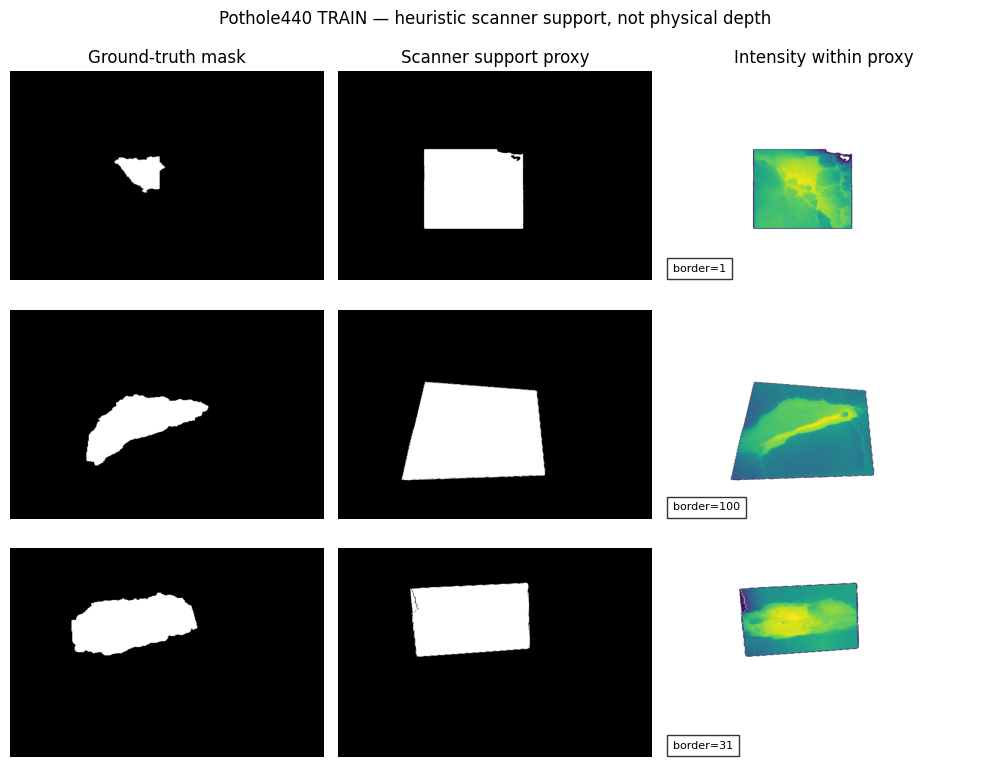


C3-08 SECTION 12 — SCANNER LABEL SEMANTICS
Training samples inspected: 12
Augmentation pairs inspected: 12
Scanner background intensity values: {1: 1, 100: 1, 31: 1, 114: 1, 107: 1, 95: 1, 89: 1, 73: 1, 106: 1, 84: 1, 68: 1, 98: 1}
Scanner support flags: {'INSPECT': 12}
Inside-versus-ring intensity direction: {'INSIDE_BRIGHTER': 12}
Simple mask-flip matches: 10 / 12
Metric depth scale verified: NO
Road-normal physical sign verified: NO
Physical ML training authorized: NO
New model training performed: NO
Official validation/test data opened: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/02_dataset_audits/C3-08_section12_P440_LABEL_SEMANTICS_20261021T013225_513637Z


In [ ]:

# ============================================================
# C3-08 SECTION 12 — POTHOLE440 SCANNER LABEL SEMANTICS
#
# TRAIN split only
# Scanner footprint + augmentation consistency
# No file picker, no metric assumptions, no training
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict, Counter
from PIL import Image
from scipy.ndimage import distance_transform_edt
import csv, hashlib, json
import numpy as np
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

ROOT = Path(
    "/content/drive/MyDrive/"
    "manushi_research_data/Pothole440-main"
)

S11 = BASE / "02_dataset_audits" / (
    "C3-08_section11_POTHOLE440_TRAIN_ENCODING_"
    "20261021T012300_005447Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

assert S11.is_dir()
assert (ROOT / "train").is_dir()

TRAIN = ROOT / "train"


# ------------------------------------------------------------
# 1. VERIFY PREVIOUS SOURCE EVIDENCE
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


def verify(folder, filename):

    expected = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():

            digest, name = line.split(None, 1)
            name = name.strip()

            assert name not in expected
            expected[name] = digest

    assert filename in expected
    assert sha(folder / filename) == expected[filename]

    return expected[filename]


h11 = verify(
    S11, "encoding_report.json"
)

verify(S11, "locked_protocol.json")
verify(S11, "train_augmentation_families.csv")

previous = json.loads(
    (S11 / "encoding_report.json").read_text()
)

previous_protocol = json.loads(
    (S11 / "locked_protocol.json").read_text()
)

assert previous_protocol[
    "validation_split_accessed"
] is False

assert previous_protocol[
    "test_split_accessed"
] is False

selected = previous_protocol["selected_filenames"]

assert len(selected) == 12

previous_records = {
    r["sample"]: r
    for r in previous["selected_records"]
}

assert set(selected) == set(previous_records)

families = defaultdict(list)

with (
    S11 / "train_augmentation_families.csv"
).open(newline="") as f:

    for row in csv.DictReader(f):

        families[
            row["inferred_original_group"]
        ].append(row["filename"])

assert len(families) == (
    previous["summary"]["inferred_original_families"]
)

print("Section 11 source evidence: VERIFIED")


# ------------------------------------------------------------
# 2. LOCK RESEARCH CONFIGURATION AND SAMPLE CHOICE
# ------------------------------------------------------------

# These are exploratory diagnostics, not
# certified measurement-quality thresholds.

INTENSITY_DIFFERENCE = 2
RING_MIN = 4
RING_MAX = 28
MIN_RING_PIXELS = 150
MIN_SUPPORT_COVERAGE = 0.75
SIMPLE_FLIP_IOU = 0.95

choices = []

for name in selected:

    family = previous_records[name][
        "inferred_original_group"
    ]

    variants = sorted(
        f for f in families[family]
        if f != name
    )

    choices.append({
        "family": family,
        "reference": name,
        "variant": variants[0] if variants else None
    })


stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "02_dataset_audits" / (
    "C3-08_section12_P440_LABEL_SEMANTICS_"
    + stamp
)

OUT.mkdir(
    parents=True,
    exist_ok=False
)

protocol = {
    "stage": "C3-08_SECTION12",
    "section11_report_sha256": h11,

    "selected_choices": choices,

    "scanner_background_estimator": (
        "Median intensity on 5-pixel image border"
    ),

    "support_proxy_rule": (
        "Absolute difference from border "
        "intensity >= 2"
    ),

    "ring_pixels": [RING_MIN, RING_MAX],

    "minimum_ring_pixels": MIN_RING_PIXELS,

    "minimum_exploratory_support_coverage":
        MIN_SUPPORT_COVERAGE,

    "metric_units_verified": False,
    "road_normal_sign_verified": False,
    "scanner_support_ground_truth_available": False,

    "new_model_training": False,
    "official_val_or_test_opened": False
}

(
    OUT / "locked_protocol.json"
).write_text(
    json.dumps(protocol, indent=2)
)


# ------------------------------------------------------------
# 3. BOUNDED SOURCE-IMAGE LOADING
# ------------------------------------------------------------

def load_pair(filename):

    depth_path = TRAIN / "depth" / filename
    mask_path = TRAIN / "mask" / filename

    assert depth_path.is_file()
    assert mask_path.is_file()

    with Image.open(depth_path) as image:
        depth = np.asarray(image).copy()

    with Image.open(mask_path) as image:
        mask = (
            np.asarray(image.convert("L")) > 127
        )

    assert depth.ndim == 2
    assert depth.shape == mask.shape
    assert depth.dtype == np.uint8

    return (
        depth,
        mask,
        sha(depth_path),
        sha(mask_path)
    )


# ------------------------------------------------------------
# 4. ESTIMATE THE SCANNER FOOTPRINT
# ------------------------------------------------------------

def estimate_support(depth):

    # This is only a heuristic support indicator.
    # We do NOT assume all nonbackground pixels
    # are valid physical scanner measurements.

    edge = np.concatenate([
        depth[:5, :].ravel(),
        depth[-5:, :].ravel(),
        depth[:, :5].ravel(),
        depth[:, -5:].ravel()
    ]).astype(np.int16)

    background = int(np.median(edge))

    border_consistency = float(
        np.mean(edge == background)
    )

    support = (
        np.abs(
            depth.astype(np.int16) - background
        ) >= INTENSITY_DIFFERENCE
    )

    return (
        background,
        border_consistency,
        support
    )


def profile(depth, mask):

    background, border_fraction, support = (
        estimate_support(depth)
    )

    # A local intact-road candidate ring.
    distance = distance_transform_edt(~mask)

    ring = (
        (distance >= RING_MIN)
        & (distance <= RING_MAX)
        & support
    )

    supported_defect = depth[
        mask & support
    ].astype(np.float32)

    supported_ring = depth[
        ring
    ].astype(np.float32)

    inside_median = (
        float(np.median(supported_defect))
        if len(supported_defect)
        else None
    )

    ring_median = (
        float(np.median(supported_ring))
        if len(supported_ring)
        else None
    )

    coverage = float(
        np.mean(support[mask])
    )

    difference = (
        inside_median - ring_median
        if (
            inside_median is not None
            and ring_median is not None
        )
        else None
    )

    flag = (
        "INSPECT"
        if (
            coverage >= MIN_SUPPORT_COVERAGE
            and int(ring.sum()) >= MIN_RING_PIXELS
        )
        else "REVIEW_SCAN_FOOTPRINT"
    )

    return {
        "background_intensity": background,
        "border_background_fraction":
            border_fraction,

        "support_proxy_image_fraction":
            float(support.mean()),

        "pothole_mask_support_coverage":
            coverage,

        "ring_support_pixels":
            int(ring.sum()),

        "inside_intensity_median":
            inside_median,

        "ring_intensity_median":
            ring_median,

        "inside_minus_ring_intensity":
            difference,

        "engineering_flag": flag
    }, support


# ------------------------------------------------------------
# 5. TEST RELATED IMAGES FOR SIMPLE FLIP CONSISTENCY
# ------------------------------------------------------------

def transform(array, operation):

    if operation == "identity":
        return array

    if operation == "horizontal_flip":
        return array[:, ::-1]

    if operation == "vertical_flip":
        return array[::-1, :]

    if operation == "both_flips":
        return array[::-1, ::-1]

    raise ValueError(operation)


def mask_iou(a, b):

    intersection = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()

    return float(
        intersection / max(int(union), 1)
    )


# ------------------------------------------------------------
# 6. RUN 12 SOURCE INSPECTIONS
# ------------------------------------------------------------

observations = []
augmentations = []
previews = []
failures = []

for number, chosen in enumerate(choices, 1):

    filename = chosen["reference"]

    try:

        depth, mask, depth_hash, mask_hash = (
            load_pair(filename)
        )

        prior = previous_records[filename]

        assert (
            depth_hash == prior["depth_sha256"]
        )

        assert (
            mask_hash == prior["mask_sha256"]
        )

        info, support = profile(depth, mask)

        observations.append({
            "filename": filename,
            "family": chosen["family"],
            "depth_sha256": depth_hash,
            "mask_sha256": mask_hash,
            **info
        })

        if len(previews) < 3:
            previews.append((
                filename,
                mask.copy(),
                support.copy(),
                depth.copy(),
                info["background_intensity"]
            ))

        variant_name = chosen["variant"]

        if variant_name is not None:

            variant_depth, variant_mask, vdh, vmh = (
                load_pair(variant_name)
            )

            assert variant_depth.shape == depth.shape
            assert variant_mask.shape == mask.shape

            variant_bg, _, variant_support = (
                estimate_support(variant_depth)
            )

            comparisons = []

            for operation in (
                "identity",
                "horizontal_flip",
                "vertical_flip",
                "both_flips"
            ):

                transformed_mask = transform(
                    mask, operation
                )

                transformed_depth = transform(
                    depth, operation
                )

                transformed_support = transform(
                    support, operation
                )

                agreement = mask_iou(
                    transformed_mask,
                    variant_mask
                )

                overlap = (
                    transformed_support
                    & variant_support
                    & transformed_mask
                    & variant_mask
                )

                n = int(overlap.sum())

                if n >= 100:

                    diff = (
                        transformed_depth[overlap]
                        .astype(np.int16)

                        - variant_depth[overlap]
                        .astype(np.int16)
                    )

                    offset = float(np.median(diff))

                    residual = float(
                        np.percentile(
                            np.abs(diff - offset),
                            95
                        )
                    )

                    exact_fraction = float(
                        np.mean(diff == 0)
                    )

                else:

                    offset = None
                    residual = None
                    exact_fraction = None

                comparisons.append({
                    "transform": operation,
                    "mask_iou": agreement,
                    "overlap_pixels": n,

                    "depth_median_offset":
                        offset,

                    "depth_offset_corrected_p95":
                        residual,

                    "depth_exact_match_fraction":
                        exact_fraction
                })

            best = max(
                comparisons,
                key=lambda item: item["mask_iou"]
            )

            augmentations.append({
                "family": chosen["family"],
                "base_filename": filename,
                "variant_filename": variant_name,

                "variant_depth_sha256": vdh,
                "variant_mask_sha256": vmh,

                "variant_background_intensity":
                    variant_bg,

                "best_mask_transform":
                    best["transform"],

                "best_mask_iou":
                    best["mask_iou"],

                "simple_flip_match":
                    best["mask_iou"] >= SIMPLE_FLIP_IOU,

                "depth_p95_after_offset":
                    best["depth_offset_corrected_p95"],

                "depth_exact_match_fraction":
                    best["depth_exact_match_fraction"],

                "all_transform_diagnostics":
                    comparisons
            })

        print(
            f"{number:02d}/12 | {filename} | "
            f"border={info['background_intensity']} | "
            f"mask coverage="
            f"{info['pothole_mask_support_coverage']:.3f} | "
            f"{info['engineering_flag']}",
            flush=True
        )

    except Exception as exc:

        failures.append({
            "filename": filename,
            "error": (
                type(exc).__name__ + ": " + str(exc)
            )
        })

        print(
            f"{number:02d}/12 | FAILED: {filename}: {exc}",
            flush=True
        )


# ------------------------------------------------------------
# 7. REQUIRE COMPLETE AUDIT
# ------------------------------------------------------------

assert (
    len(observations) + len(failures)
    == len(choices)
)

if failures:

    (
        OUT / "failures.json"
    ).write_text(
        json.dumps(failures, indent=2)
    )

    raise RuntimeError(
        f"Audit failures: {len(failures)}. "
        f"Review {OUT / 'failures.json'}"
    )


# ------------------------------------------------------------
# 8. SUMMARIZE SCANNER-LABEL BEHAVIOR
# ------------------------------------------------------------

backgrounds = Counter(
    row["background_intensity"]
    for row in observations
)

flags = Counter(
    row["engineering_flag"]
    for row in observations
)

polarity = Counter()

for row in observations:

    value = row["inside_minus_ring_intensity"]

    if value is None:
        polarity["UNAVAILABLE"] += 1

    elif value > 0:
        polarity["INSIDE_BRIGHTER"] += 1

    elif value < 0:
        polarity["INSIDE_DARKER"] += 1

    else:
        polarity["EQUAL"] += 1


summary = {
    "samples_inspected": len(observations),
    "augmentation_pairs_inspected":
        len(augmentations),

    "border_background_intensities":
        dict(backgrounds),

    "scanner_support_flags":
        dict(flags),

    "inside_vs_road_ring_intensity_direction":
        dict(polarity),

    "simple_flip_matches": sum(
        r["simple_flip_match"]
        for r in augmentations
    ),

    "physical_depth_encoding_verified": False,

    "scanner_support_proxy_is_ground_truth":
        False,

    "road_normal_sign_verified": False,
    "metric_training_authorized": False,
    "physical_severity_authorized": False,

    "independent_scene_validation": False,
    "official_val_test_accessed": False
}


# ------------------------------------------------------------
# 9. SAVE REPORTS
# ------------------------------------------------------------

(
    OUT / "label_semantics_report.json"
).write_text(
    json.dumps({
        "summary": summary,
        "source_protocol": protocol,
        "per_image": observations,
        "augmentation_results": augmentations,
        "failures": failures
    }, indent=2)
)

with (
    OUT / "sample_support_profiles.csv"
).open("w", newline="") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=list(observations[0])
    )

    writer.writeheader()
    writer.writerows(observations)


# ------------------------------------------------------------
# 10. VISUALIZE SCANNER SUPPORT VS DEFECT MASK
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3, 3,
    figsize=(10, 8)
)

for i, item in enumerate(previews):

    filename, mask, support, depth, background = item

    axes[i, 0].imshow(
        mask,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i, 1].imshow(
        support,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i, 2].imshow(
        np.where(
            support, depth, np.nan
        ),
        cmap="viridis"
    )

    axes[i, 0].set_ylabel(
        filename[:28],
        fontsize=8
    )

    axes[i, 2].text(
        0.02, 0.04,
        f"border={background}",
        transform=axes[i, 2].transAxes,
        fontsize=8,
        bbox={
            "facecolor": "white",
            "alpha": 0.8
        }
    )

    for ax in axes[i]:
        ax.axis("off")

for ax, title in zip(
    axes[0],
    [
        "Ground-truth mask",
        "Scanner support proxy",
        "Intensity within proxy"
    ]
):
    ax.set_title(title)

fig.suptitle(
    "Pothole440 TRAIN — "
    "heuristic scanner support, not physical depth"
)

fig.tight_layout()

fig.savefig(
    OUT / "scanner_support_diagnostic.png",
    dpi=130
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 11. SAVE FILE INTEGRITY CHECKSUMS
# ------------------------------------------------------------

with (
    OUT / "checksums.sha256"
).open("w") as file:

    for path in sorted(OUT.iterdir()):

        if (
            path.is_file()
            and path.name != "checksums.sha256"
        ):

            file.write(
                f"{sha(path)}  {path.name}\n"
            )


# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("C3-08 SECTION 12 — SCANNER LABEL SEMANTICS")
print("=" * 68)

print("Training samples inspected:", len(observations))

print(
    "Augmentation pairs inspected:",
    len(augmentations)
)

print(
    "Scanner background intensity values:",
    dict(backgrounds)
)

print("Scanner support flags:", dict(flags))

print(
    "Inside-versus-ring intensity direction:",
    dict(polarity)
)

print(
    "Simple mask-flip matches:",
    summary["simple_flip_matches"],
    "/", len(augmentations)
)

print("Metric depth scale verified: NO")
print("Road-normal physical sign verified: NO")
print("Physical ML training authorized: NO")
print("New model training performed: NO")
print("Official validation/test data opened: NO")

print("\nSaved:", OUT)
print("=" * 68)


Source integrity: PASS
Original-priority training families: 98


/tmp/ipykernel_672/162575084.py:265: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  else Image.fromarray(arr, mode=mode)


Training families inspected: 15/98 | accepted: 15
Training families inspected: 30/98 | accepted: 30
Training families inspected: 45/98 | accepted: 45
Training families inspected: 60/98 | accepted: 60
Training families inspected: 75/98 | accepted: 75
Training families inspected: 90/98 | accepted: 90
Training families inspected: 98/98 | accepted: 98
Development folds frozen: 5
Training device: cpu

Fold 1/5 | training 78, validation 20 families
  rgb_mask: complete in 46.8s
  mask_only: complete in 46.9s

Fold 2/5 | training 78, validation 20 families
  rgb_mask: complete in 45.3s
  mask_only: complete in 42.6s

Fold 3/5 | training 78, validation 20 families
  rgb_mask: complete in 45.8s
  mask_only: complete in 45.5s

Fold 4/5 | training 79, validation 19 families
  rgb_mask: complete in 47.2s
  mask_only: complete in 46.8s

Fold 5/5 | training 79, validation 19 families
  rgb_mask: complete in 46.9s
  mask_only: complete in 46.7s
Final model reload and inference: PASS


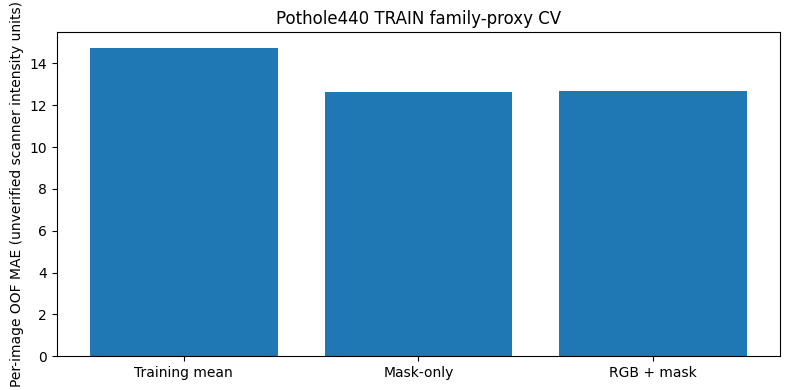


C3-08 SECTION 13 — POTHOLE440 RELATIVE SCANNER ML
Eligible original families: 98
Rejected: 0
Out-of-fold predictions: 196
Development folds: 5
Training-only mean baseline MAE: 14.749
Mask-only OOF MAE: 12.62
RGB + mask OOF MAE: 12.687
RGB wins: 55 / 98
Final development checkpoints: 2
Checkpoint reload/inference: PASS
Verified physical depth: NO
Metric severity authorized: NO
Official val/test accessed: NO

ML dataset: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/04_geometry_targets/C3-08_section13_P440_RELATIVE_INTENSITY_ML_20261021T014247_895190Z
Training results: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-08_section13_P440_RELATIVE_INTENSITY_ML_20261021T014247_895190Z
Model checkpoints: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/06_model_checkpoints/C3-08_section13_P440_RELATIVE_INTENSITY_ML_20261021T014247_895190Z


In [ ]:

# ============================================================
# C3-08 SECTION 13 — POTHOLE440 RELATIVE SCANNER ML
# No file picker, no uploads, no metric assumptions.
# TRAIN split only; augmented copies excluded.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict, Counter
from PIL import Image
from scipy.ndimage import distance_transform_edt
import numpy as np
import torch
import torch.nn.functional as F
import hashlib, json, csv, os, random, shutil
import importlib.util, time, sys
import matplotlib.pyplot as plt

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)
ROOT = Path(
    "/content/drive/MyDrive/"
    "manushi_research_data/Pothole440-main"
)
S11 = BASE / "02_dataset_audits" / (
    "C3-08_section11_POTHOLE440_TRAIN_ENCODING_"
    "20261021T012300_005447Z"
)
S12 = BASE / "02_dataset_audits" / (
    "C3-08_section12_P440_LABEL_SEMANTICS_"
    "20261021T013225_513637Z"
)
ARCH = BASE / "06_model_checkpoints" / (
    "C3-03_section02_MULTIIMAGE_NONMETRIC_"
    "20261020T090136_046938Z"
)

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for p in (
    ROOT / "train/rgb",
    ROOT / "train/depth",
    ROOT / "train/mask",
    S11, S12, ARCH
):
    assert p.is_dir(), p


# ------------------------------------------------------------
# 1. VERIFY EXISTING RESEARCH ARTIFACTS
# ------------------------------------------------------------

def digest(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()


def verify(folder, name):
    found = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():
        if line.strip():
            h, n = line.split(None, 1)
            n = n.strip()
            assert n not in found
            found[n] = h

    assert name in found
    assert digest(folder / name) == found[name]
    return found[name]


sha11 = verify(
    S11, "train_augmentation_families.csv"
)
sha12 = verify(
    S12, "label_semantics_report.json"
)
sha_arch = verify(
    ARCH, "crdl_dev_model.py"
)

prior = json.loads(
    (S12 / "label_semantics_report.json").read_text()
)

assert prior["summary"]["samples_inspected"] == 12
assert prior["summary"][
    "inside_vs_road_ring_intensity_direction"
] == {"INSIDE_BRIGHTER": 12}
assert prior["summary"]["metric_training_authorized"] is False

families = defaultdict(list)

with (
    S11 / "train_augmentation_families.csv"
).open(newline="") as f:

    for r in csv.DictReader(f):
        families[
            r["inferred_original_group"]
        ].append(r["filename"])

assert len(families) == 98

# Choose only one original-priority image per family.
selected = []

for group, names in sorted(families.items()):

    candidates = sorted(
        names,
        key=lambda n: (
            Path(n).stem != group,
            "_aug" in n.lower(),
            n
        )
    )

    selected.append((group, candidates[0]))

assert len(set(name for _, name in selected)) == 98

print("Source integrity: PASS")
print("Original-priority training families:", len(selected))


# ------------------------------------------------------------
# 2. LOCK CONFIGURATION BEFORE TRAINING
# ------------------------------------------------------------

SEED = 20261021
SIZE = 96
EPOCHS = 8
BATCH = 8
LR = 0.002
MIN_GOOD = 40

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

NAME = (
    "C3-08_section13_P440_RELATIVE_INTENSITY_ML_"
    + stamp
)

OUT = BASE / "04_geometry_targets" / NAME
RUN = BASE / "05_training_runs" / NAME
CKPT = BASE / "06_model_checkpoints" / NAME

for p in (OUT, RUN, CKPT):
    p.mkdir(parents=True, exist_ok=False)

shutil.copy2(
    ARCH / "crdl_dev_model.py",
    CKPT / "crdl_dev_model.py"
)

assert digest(
    CKPT / "crdl_dev_model.py"
) == sha_arch

config = {
    "stage": "C3-08_SECTION13",
    "dataset": "Pothole440 TRAIN ONLY",
    "selected_families": 98,
    "selection": (
        "One original-priority representative "
        "per inferred family; exclude augmentations"
    ),
    "target": (
        "max(scanner intensity - supported "
        "surrounding-ring median, 0), "
        "in unverified intensity units"
    ),
    "ring_px": [4, 28],
    "support_proxy": (
        "abs(intensity - border median) >= 2"
    ),
    "quality_thresholds": {
        "min_mask_support": 0.75,
        "min_ring_pixels": 150,
        "min_inside_minus_ring": 1.0,
        "min_valid_downsampled_pixels": 25,
        "minimum_accepted_families": MIN_GOOD
    },
    "crop": (
        "Square around mask bounding box, "
        "side=max(96, ceil(1.8*max(bbox width,height)))"
    ),
    "size": SIZE,
    "epochs": EPOCHS,
    "batch_size": BATCH,
    "learning_rate": LR,
    "seed": SEED,
    "folds": (
        "Five family-proxy folds; "
        "NOT independently verified scenes"
    ),
    "physical_units_verified": False,
    "road_normal_depth_verified": False,
    "severity_authorized": False,
    "protected_399_opened": False,
    "official_val_test_opened": False,
    "sources": {
        "section11": sha11,
        "section12": sha12,
        "architecture": sha_arch
    }
}

(OUT / "locked_protocol.json").write_text(
    json.dumps(config, indent=2)
)


# ------------------------------------------------------------
# 3. GEOMETRY-ALIGNED CROPPING
# ------------------------------------------------------------

def crop_box(mask):
    yy, xx = np.nonzero(mask)

    if len(xx) < 30:
        raise ValueError("EMPTY_MASK")

    x0, x1 = int(xx.min()), int(xx.max() + 1)
    y0, y1 = int(yy.min()), int(yy.max() + 1)

    side = max(
        96,
        int(np.ceil(
            1.8 * max(x1-x0, y1-y0)
        ))
    )

    cx = (x0+x1)//2
    cy = (y0+y1)//2

    return (
        cx-side//2,
        cy-side//2,
        cx-side//2+side,
        cy-side//2+side
    )


def resize(arr, box, method, mode=None):

    im = (
        Image.fromarray(arr)
        if mode is None
        else Image.fromarray(arr, mode=mode)
    )

    return np.asarray(
        im.crop(box).resize(
            (SIZE, SIZE), method
        )
    ).copy()


# ------------------------------------------------------------
# 4. PROCESS REAL TRAINING SOURCES
# ------------------------------------------------------------

Xlist, Ylist, Wlist = [], [], []
used, accepted, rejected = [], [], []

for idx, (group, name) in enumerate(selected, 1):

    paths = {
        kind: ROOT / "train" / kind / name
        for kind in ("rgb", "mask", "depth")
    }

    basic = {
        "group": group,
        "filename": name
    }

    try:
        assert all(p.is_file() for p in paths.values())

        with Image.open(paths["rgb"]) as im:
            rgb = np.asarray(
                im.convert("RGB")
            ).copy()

        with Image.open(paths["mask"]) as im:
            mask = (
                np.asarray(im.convert("L")).copy()
                > 127
            )

        with Image.open(paths["depth"]) as im:
            assert im.mode == "L"
            depth = np.asarray(im).copy()

        assert depth.dtype == np.uint8
        assert depth.shape == mask.shape
        assert depth.shape == rgb.shape[:2]

        border = np.concatenate([
            depth[:5].ravel(),
            depth[-5:].ravel(),
            depth[:, :5].ravel(),
            depth[:, -5:].ravel()
        ])

        background = int(np.median(border))

        support = (
            np.abs(
                depth.astype("int16") - background
            ) >= 2
        )

        distance = distance_transform_edt(~mask)

        ring = (
            (distance >= 4)
            & (distance <= 28)
            & support
        )

        coverage = float(
            np.mean(support[mask])
        )

        ring_count = int(ring.sum())

        assert (
            ring_count >= 150
            and coverage >= 0.75
        ), "WEAK_SCANNER_SUPPORT"

        reference = float(
            np.median(depth[ring])
        )

        inside = float(
            np.median(depth[mask & support])
        )

        contrast = inside - reference

        assert contrast >= 1.0, (
            "NO_POSITIVE_CONTRAST"
        )

        valid = mask & support

        # This is relative intensity contrast,
        # not physically measured depression.
        target = np.where(
            valid,
            np.maximum(
                depth.astype("float32") - reference,
                0.0
            ),
            0.0
        ).astype("float32")

        box = crop_box(mask)

        rgb96 = resize(
            rgb, box, Image.Resampling.BOX
        ).transpose(2, 0, 1).astype("float32") / 255

        mask96 = (
            resize(
                (mask * 255).astype("uint8"),
                box,
                Image.Resampling.NEAREST
            ) > 127
        )

        valid96 = resize(
            valid.astype("float32"),
            box,
            Image.Resampling.BOX,
            mode="F"
        )

        numerator96 = resize(
            target,
            box,
            Image.Resampling.BOX,
            mode="F"
        )

        weights96 = (
            (valid96 >= 0.80)
            & mask96
        )

        label96 = np.maximum(
            numerator96 / np.maximum(valid96, 1e-8),
            0
        ).astype("float32")

        label96[~weights96] = 0

        assert weights96.sum() >= 25, (
            "INSUFFICIENT_DOWNSAMPLED_TARGET"
        )

        x = np.concatenate([
            rgb96,
            mask96[None].astype("float32"),
            np.ones(
                (1, SIZE, SIZE), dtype="float32"
            )
        ])

        assert x.shape == (5, SIZE, SIZE)
        assert np.isfinite(label96).all()

        Xlist.append(x)
        Ylist.append(label96[None])
        Wlist.append(
            weights96[None].astype("float32")
        )
        used.append((group, name))

        accepted.append({
            **basic,
            "status": "ACCEPTED",
            "contrast_intensity": contrast,
            "reference_ring_intensity": reference,
            "scanner_support_coverage": coverage,
            "ring_support_pixels": ring_count,
            "valid_96_pixels": int(weights96.sum()),
            "crop_box": list(box),
            "rgb_sha256": digest(paths["rgb"]),
            "mask_sha256": digest(paths["mask"]),
            "depth_sha256": digest(paths["depth"])
        })

    except Exception as e:
        rejected.append({
            **basic,
            "status": "REJECTED",
            "reason": str(e)[:180]
        })

    if idx % 15 == 0 or idx == 98:
        print(
            f"Training families inspected: {idx}/98 | "
            f"accepted: {len(used)}",
            flush=True
        )


# ------------------------------------------------------------
# 5. SAVE QUALITY EVIDENCE BEFORE ANY FITTING
# ------------------------------------------------------------

fields = [
    "group", "filename", "status", "reason",
    "contrast_intensity",
    "reference_ring_intensity",
    "scanner_support_coverage",
    "ring_support_pixels",
    "valid_96_pixels",
    "crop_box",
    "rgb_sha256",
    "mask_sha256",
    "depth_sha256"
]

with (
    OUT / "family_QA_manifest.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f, fieldnames=fields
    )
    writer.writeheader()

    for r in accepted + rejected:
        writer.writerow({
            k: (
                json.dumps(r[k])
                if isinstance(r.get(k), list)
                else r.get(k, "")
            )
            for k in fields
        })

qa = {
    "selected_families": 98,
    "accepted": len(used),
    "rejected": len(rejected),
    "rejection_reasons": dict(
        Counter(r["reason"] for r in rejected)
    ),
    "minimum_required": MIN_GOOD,
    "physical_units_verified": False
}

(OUT / "family_QA_report.json").write_text(
    json.dumps(qa, indent=2)
)

if len(used) < MIN_GOOD:
    raise RuntimeError(
        "Too few valid scanner labels for training. "
        f"Review: {OUT / 'family_QA_report.json'}"
    )


# ------------------------------------------------------------
# 6. SAVE ML DATASET AND FREEZE FOLDS
# ------------------------------------------------------------

X = np.stack(Xlist).astype("float32")
Y = np.stack(Ylist).astype("float32")
W = np.stack(Wlist).astype("float32")

N = len(used)

assert X.shape == (N, 5, SIZE, SIZE)
assert Y.shape == W.shape == (N, 1, SIZE, SIZE)
assert np.isfinite(X).all()
assert np.isfinite(Y).all()

np.savez_compressed(
    OUT / "scanner_relative_development_data.npz",
    X=X, Y=Y, W=W,
    group_ids=np.array([g for g, _ in used]),
    filenames=np.array([n for _, n in used]),
    metric_units_verified=np.array(False)
)

rng = np.random.default_rng(SEED)
permutation = rng.permutation(N)

folds = []

for k, val in enumerate(
    np.array_split(permutation, 5)
):

    val = sorted(map(int, val))
    train = sorted(
        set(range(N)) - set(val)
    )

    assert set(
        used[i][0] for i in val
    ).isdisjoint(set(
        used[i][0] for i in train
    ))

    folds.append({
        "fold": k,
        "train_indices": train,
        "val_indices": val,
        "val_families": [
            used[i][0] for i in val
        ]
    })

assert sorted(
    i for f in folds for i in f["val_indices"]
) == list(range(N))

(OUT / "family_proxy_folds.json").write_text(
    json.dumps(folds, indent=2)
)

print("Development folds frozen:", len(folds))


# ------------------------------------------------------------
# 7. INITIALIZE THE ORIGINAL UNET ARCHITECTURE
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "c308_p440_network",
    CKPT / "crdl_dev_model.py"
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

Model = module.CRDLDevUNet

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

if DEVICE.type == "cpu":
    torch.set_num_threads(
        min(2, os.cpu_count() or 1)
    )

if DEVICE.type == "cuda":
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Training device:", DEVICE)


def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def fit(train_idx, arm, fold_id):

    pixels = Y[train_idx][
        W[train_idx] > 0.5
    ]

    scale = float(
        np.percentile(pixels, 95)
    )
    mean = float(pixels.mean())

    assert np.isfinite(scale) and scale > 0

    # Both arms start with the same initialization.
    seed_all(SEED + 100 * fold_id)

    net = Model().to(DEVICE)

    optimizer = torch.optim.AdamW(
        net.parameters(),
        lr=LR,
        weight_decay=1e-4
    )

    generator = np.random.default_rng(
        SEED + 100 * fold_id + 1
    )

    history = []

    for epoch in range(EPOCHS):

        net.train()
        order = generator.permutation(train_idx)
        losses = []

        for start in range(
            0, len(order), BATCH
        ):

            indices = order[start:start+BATCH]

            inp = torch.from_numpy(
                X[indices].copy()
            )

            if arm == "mask_only":
                inp[:, :3] = 0

            xb = inp.to(DEVICE)

            yb = (
                torch.from_numpy(Y[indices])
                .to(DEVICE) / scale
            )

            wb = torch.from_numpy(
                W[indices]
            ).to(DEVICE)

            optimizer.zero_grad(
                set_to_none=True
            )

            pred = F.softplus(net(xb))

            loss = (
                F.smooth_l1_loss(
                    pred, yb,
                    beta=0.2,
                    reduction="none"
                ) * wb
            ).sum() / wb.sum().clamp_min(1)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                net.parameters(), 1.0
            )

            optimizer.step()
            losses.append(float(loss.item()))

        history.append({
            "fold": fold_id,
            "arm": arm,
            "epoch": epoch+1,
            "mean_batch_train_loss": float(
                np.mean(losses)
            )
        })

    return net, scale, mean, history


@torch.inference_mode()
def predict(net, indices, arm, scale):

    net.eval()
    outputs = []

    for i in indices:

        x = torch.from_numpy(
            X[i:i+1].copy()
        )

        if arm == "mask_only":
            x[:, :3] = 0

        result = (
            F.softplus(
                net(x.to(DEVICE))
            )[0, 0].cpu().numpy()
            * scale
        )

        outputs.append(result)

    return np.stack(outputs).astype("float32")


def save_checkpoint(
    net, scale, arm, fold_id, train_indices
):

    path = CKPT / f"{fold_id}_{arm}.pt"

    torch.save({
        "state_dict": {
            k: v.detach().cpu()
            for k, v in net.state_dict().items()
        },
        "arm": arm,
        "target_scale": scale,
        "fold": str(fold_id),
        "train_families": [
            used[i][0] for i in train_indices
        ],
        "architecture_sha256": sha_arch,
        "physical_units_verified": False,
        "source": "P440_RELATIVE_SCANNER_INTENSITY",
        "size": SIZE
    }, path)

    saved = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    reloaded = Model()

    reloaded.load_state_dict(
        saved["state_dict"],
        strict=True
    )

    assert saved["arm"] == arm
    assert saved["physical_units_verified"] is False

    return path


# ------------------------------------------------------------
# 8. TRAIN TEN FOLD-SPECIFIC ML MODELS
# ------------------------------------------------------------

ARMS = ("rgb_mask", "mask_only")

records = []
histories = []

for fold in folds:

    k = fold["fold"]
    train_idx = fold["train_indices"]
    val_idx = fold["val_indices"]

    print(
        f"\nFold {k+1}/5 | "
        f"training {len(train_idx)}, "
        f"validation {len(val_idx)} families",
        flush=True
    )

    for arm in ARMS:

        started = time.perf_counter()

        net, scale, baseline, hist = fit(
            train_idx, arm, k
        )

        estimated = predict(
            net, val_idx, arm, scale
        )

        save_checkpoint(
            net, scale, arm,
            f"fold{k:02d}", train_idx
        )

        histories.extend(hist)

        for j, i in enumerate(val_idx):

            valid = W[i, 0] > 0.5

            truth = Y[i, 0][valid]
            pred = estimated[j][valid]

            records.append({
                "family": used[i][0],
                "filename": used[i][1],
                "fold": k,
                "arm": arm,
                "mae_intensity": float(
                    np.mean(np.abs(truth-pred))
                ),
                "d95_error_intensity": float(
                    abs(
                        np.percentile(pred, 95)
                        - np.percentile(truth, 95)
                    )
                ),
                "train_mean_baseline_mae": float(
                    np.mean(
                        np.abs(truth-baseline)
                    )
                ),
                "scale_train_only": scale,
                "n_target_pixels": int(valid.sum())
            })

        print(
            f"  {arm}: complete in "
            f"{time.perf_counter()-started:.1f}s",
            flush=True
        )

        del net

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

assert len(records) == 2*N


# ------------------------------------------------------------
# 9. REPORT REAL OUT-OF-FOLD RESULTS
# ------------------------------------------------------------

summary = {}

for arm in ARMS:

    subset = [
        r for r in records
        if r["arm"] == arm
    ]

    summary[arm] = {
        "oof_mae_intensity": float(
            np.mean([
                r["mae_intensity"] for r in subset
            ])
        ),
        "oof_d95_error_intensity": float(
            np.mean([
                r["d95_error_intensity"]
                for r in subset
            ])
        ),
        "per_fold_mae": [
            float(np.mean([
                r["mae_intensity"]
                for r in subset
                if r["fold"] == k
            ]))
            for k in range(5)
        ]
    }

mask_lookup = {
    r["family"]: r
    for r in records
    if r["arm"] == "mask_only"
}

rgb_wins = sum(
    r["mae_intensity"]
    < mask_lookup[r["family"]]["mae_intensity"]
    for r in records
    if r["arm"] == "rgb_mask"
)

baseline = float(np.mean([
    r["train_mean_baseline_mae"]
    for r in records
    if r["arm"] == "mask_only"
]))


# ------------------------------------------------------------
# 10. TRAIN TWO FULL-DEVELOPMENT CHECKPOINTS
# ------------------------------------------------------------

for arm in ARMS:

    net, scale, _, hist = fit(
        list(range(N)), arm, 77
    )

    histories.extend(hist)

    save_checkpoint(
        net, scale, arm,
        "full_train_development_only",
        list(range(N))
    )

    del net


# ------------------------------------------------------------
# 11. STANDALONE RGB + MASK INFERENCE CONTRACT
# ------------------------------------------------------------

inference_code = r'''
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from crdl_dev_model import CRDLDevUNet

def predict(rgb, mask, checkpoint):

    rgb = np.asarray(rgb)
    mask = np.asarray(mask, dtype=bool)

    if (
        rgb.dtype != np.uint8
        or rgb.ndim != 3
        or rgb.shape[2] != 3
        or rgb.shape[:2] != mask.shape
        or not mask.any()
    ):
        raise ValueError(
            "Expected HxWx3 uint8 RGB "
            "and matching nonempty bool mask"
        )

    yy, xx = np.nonzero(mask)

    xa, xb = int(xx.min()), int(xx.max()+1)
    ya, yb = int(yy.min()), int(yy.max()+1)

    side = max(
        96,
        int(np.ceil(
            1.8 * max(xb-xa, yb-ya)
        ))
    )

    cx = (xa+xb)//2
    cy = (ya+yb)//2

    box = (
        cx-side//2,
        cy-side//2,
        cx-side//2+side,
        cy-side//2+side
    )

    rgb96 = np.asarray(
        Image.fromarray(rgb)
        .crop(box)
        .resize(
            (96,96),
            Image.Resampling.BOX
        )
    ).transpose(2,0,1).astype("float32") / 255.0

    mask96 = np.asarray(
        Image.fromarray(
            (mask*255).astype("uint8")
        ).crop(box).resize(
            (96,96),
            Image.Resampling.NEAREST
        )
    ) > 127

    inputs = np.concatenate([
        rgb96,
        mask96[None].astype("float32"),
        np.ones(
            (1,96,96),
            dtype="float32"
        )
    ])

    ck = torch.load(
        Path(checkpoint),
        map_location="cpu",
        weights_only=True
    )

    if ck["physical_units_verified"] is not False:
        raise ValueError(
            "Only nonmetric checkpoints supported"
        )

    if ck["arm"] == "mask_only":
        inputs[:3] = 0

    model = CRDLDevUNet()

    model.load_state_dict(
        ck["state_dict"],
        strict=True
    )

    model.eval()

    with torch.inference_mode():

        raw = F.softplus(
            model(
                torch.from_numpy(
                    inputs[None]
                )
            )
        )[0,0].numpy() * float(
            ck["target_scale"]
        )

    roi = np.asarray(
        Image.fromarray(
            raw.astype("float32"),
            mode="F"
        ).resize(
            (side,side),
            Image.Resampling.BILINEAR
        )
    )

    h,w = mask.shape

    output = np.zeros(
        (h,w),
        dtype="float32"
    )

    x0,y0,x1,y1 = box

    left = max(0,x0)
    top = max(0,y0)
    right = min(w,x1)
    bottom = min(h,y1)

    if right > left and bottom > top:

        output[top:bottom,left:right] = roi[
            top-y0:bottom-y0,
            left-x0:right-x0
        ]

    output[~mask] = 0

    return {
        "relative_scanner_intensity_contrast": output,
        "metric_units_verified": False,
        "physical_depth_mm": None,
        "severity": None,
        "status": "EXPERIMENTAL_NONMETRIC"
    }
'''

(CKPT / "relative_scanner_inference.py").write_text(
    inference_code
)

sys.path.insert(0, str(CKPT))

infer_spec = importlib.util.spec_from_file_location(
    "c308_relative_inference",
    CKPT / "relative_scanner_inference.py"
)

infer_module = importlib.util.module_from_spec(
    infer_spec
)

infer_spec.loader.exec_module(infer_module)

rgb_smoke = np.zeros(
    (96,96,3), dtype="uint8"
)

mask_smoke = np.zeros(
    (96,96), dtype=bool
)

mask_smoke[30:60,25:65] = True

for arm in ARMS:

    path = CKPT / (
        f"full_train_development_only_{arm}.pt"
    )

    smoke = infer_module.predict(
        rgb_smoke,
        mask_smoke,
        path
    )

    result = smoke[
        "relative_scanner_intensity_contrast"
    ]

    assert result.shape == (96,96)
    assert np.isfinite(result).all()
    assert not np.any(result[~mask_smoke])
    assert smoke["physical_depth_mm"] is None

print("Final model reload and inference: PASS")


# ------------------------------------------------------------
# 12. SAVE EVALUATION, CONFIGURATION AND CHECKSUMS
# ------------------------------------------------------------

with (
    RUN / "per_family_oof.csv"
).open("w",newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(records[0])
    )

    writer.writeheader()
    writer.writerows(records)

with (
    RUN / "training_history.csv"
).open("w",newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=list(histories[0])
    )

    writer.writeheader()
    writer.writerows(histories)

report = {
    "stage": "C3-08_SECTION13",
    "n_accepted": N,
    "n_rejected": len(rejected),
    "n_oof_predictions": len(records),
    "mean_train_pixel_baseline_mae": baseline,
    "results": summary,
    "rgb_wins": rgb_wins,

    "unit": (
        "UNVERIFIED_8BIT_SCANNER_INTENSITY_CONTRAST"
    ),

    "physical_depth_training": False,
    "physical_severity_authorized": False,
    "official_val_test_opened": False,
    "independent_scenes_verified": False,

    "full_checkpoint_reload_smoke": "PASS",

    "warnings": [
        "No scanner-to-PNG physical calibration",
        "Mask-defined relative intensity targets",
        "Augmentation families inferred by filename",
        "Development-only family-proxy cross-validation"
    ]
}

(RUN / "ablation_report.json").write_text(
    json.dumps(report, indent=2)
)

(CKPT / "preprocessing_and_api_contract.json").write_text(
    json.dumps({
        **config,
        "inference": "relative_scanner_inference.py",
        "output": (
            "Unverified relative scanner intensity only; "
            "physical_depth_mm=null; severity=null"
        )
    }, indent=2)
)

fig, ax = plt.subplots(
    figsize=(8,4)
)

ax.bar(
    [
        "Training mean",
        "Mask-only",
        "RGB + mask"
    ],
    [
        baseline,
        summary["mask_only"]["oof_mae_intensity"],
        summary["rgb_mask"]["oof_mae_intensity"]
    ]
)

ax.set_ylabel(
    "Per-image OOF MAE "
    "(unverified scanner intensity units)"
)

ax.set_title(
    "Pothole440 TRAIN family-proxy CV"
)

fig.tight_layout()

fig.savefig(
    RUN / "p440_relative_intensity_ablation.png",
    dpi=140
)

plt.show()
plt.close(fig)


def checksum_tree(folder):

    with (
        folder / "checksums.sha256"
    ).open("w") as f:

        for path in sorted(folder.rglob("*")):

            if (
                path.is_file()
                and path.name != "checksums.sha256"
            ):

                f.write(
                    f"{digest(path)}  "
                    f"{path.relative_to(folder).as_posix()}\n"
                )


for folder in (OUT, RUN, CKPT):
    checksum_tree(folder)


# ------------------------------------------------------------
# 13. FINAL RESEARCH SUMMARY
# ------------------------------------------------------------

print("\n" + "="*68)
print("C3-08 SECTION 13 — POTHOLE440 RELATIVE SCANNER ML")
print("="*68)

print("Eligible original families:", N)
print("Rejected:", len(rejected))
print("Out-of-fold predictions:", len(records))
print("Development folds:", len(folds))

print(
    "Training-only mean baseline MAE:",
    round(baseline, 3)
)

print(
    "Mask-only OOF MAE:",
    round(
        summary["mask_only"]["oof_mae_intensity"],
        3
    )
)

print(
    "RGB + mask OOF MAE:",
    round(
        summary["rgb_mask"]["oof_mae_intensity"],
        3
    )
)

print("RGB wins:", rgb_wins, "/", N)

print("Final development checkpoints:", 2)
print("Checkpoint reload/inference: PASS")

print("Verified physical depth: NO")
print("Metric severity authorized: NO")
print("Official val/test accessed: NO")

print("\nML dataset:", OUT)
print("Training results:", RUN)
print("Model checkpoints:", CKPT)

print("="*68)


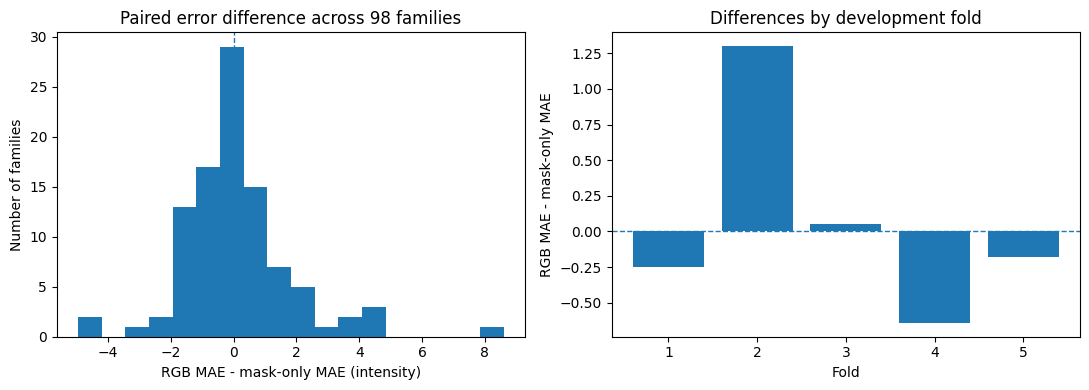


C3-08 SECTION 14 — P440 PAIRED MODEL AUDIT
Verified paired families: 98
RGB wins / mask wins / ties: 55 43 0
Mean RGB-minus-mask MAE: 0.0667
Median difference: -0.1577
Family bootstrap 95% interval: [-0.2832, 0.4322]
Fold-resampling 95% interval: [-0.405, 0.7277]
Exploratory sign-test p-value: 0.2664
RGB superiority established: NO
Verified physical units: NO
Additional training performed: NO

Saved: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/07_evaluation/C3-08_section14_P440_PAIRED_MODEL_AUDIT_20261021T021139_961672Z


In [ ]:

# ============================================================
# C3-08 SECTION 14 — P440 RGB CONTRIBUTION AUDIT
# No training, no file picker, fixed Google Drive paths.
# Uses existing 98-family out-of-fold predictions only.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
from scipy.stats import binomtest
import numpy as np
import matplotlib.pyplot as plt
import hashlib, csv, json

BASE = Path(
    "/content/drive/MyDrive/"
    "crdl_experiments/component3_fresh_v1"
)

NAME = (
    "C3-08_section13_P440_RELATIVE_INTENSITY_ML_"
    "20261021T014247_895190Z"
)

RUN = BASE / "05_training_runs" / NAME
DATA = BASE / "04_geometry_targets" / NAME
CKPT = BASE / "06_model_checkpoints" / NAME

if not BASE.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

for folder in (RUN, DATA, CKPT):
    assert folder.is_dir(), folder


# ------------------------------------------------------------
# 1. VERIFY RESEARCH SOURCES
# ------------------------------------------------------------

def sha(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


def verify(folder, filename):
    checks = {}

    for line in (
        folder / "checksums.sha256"
    ).read_text().splitlines():

        if line.strip():
            digest, name = line.split(None, 1)
            name = name.strip()

            assert name not in checks
            checks[name] = digest

    assert filename in checks
    assert sha(folder / filename) == checks[filename]

    return checks[filename]


source_hashes = {
    "oof": verify(RUN, "per_family_oof.csv"),
    "report": verify(RUN, "ablation_report.json"),
    "folds": verify(DATA, "family_proxy_folds.json"),
    "protocol": verify(DATA, "locked_protocol.json")
}

report = json.loads(
    (RUN / "ablation_report.json").read_text()
)

with (
    RUN / "per_family_oof.csv"
).open(newline="") as f:
    records = list(csv.DictReader(f))

assert report["n_accepted"] == 98
assert len(records) == 196
assert report["physical_depth_training"] is False


# ------------------------------------------------------------
# 2. PAIR IDENTICAL FAMILIES AND FOLDS
# ------------------------------------------------------------

paired = defaultdict(dict)

for row in records:

    family = row["family"]
    arm = row["arm"]

    assert arm in ("rgb_mask", "mask_only")
    assert arm not in paired[family]

    paired[family][arm] = row

assert len(paired) == 98

rows = []

for family in sorted(paired):

    entry = paired[family]

    assert set(entry) == {
        "rgb_mask", "mask_only"
    }

    rgb = entry["rgb_mask"]
    mask = entry["mask_only"]

    assert rgb["fold"] == mask["fold"]
    assert rgb["filename"] == mask["filename"]

    rgb_mae = float(rgb["mae_intensity"])
    mask_mae = float(mask["mae_intensity"])

    rows.append({
        "family": family,
        "fold": int(rgb["fold"]),
        "rgb_mae": rgb_mae,
        "mask_mae": mask_mae,

        # Negative means RGB is better.
        "rgb_minus_mask_mae": rgb_mae - mask_mae,

        "rgb_d95_error": float(
            rgb["d95_error_intensity"]
        ),

        "mask_d95_error": float(
            mask["d95_error_intensity"]
        )
    })


differences = np.array([
    r["rgb_minus_mask_mae"] for r in rows
])

rgb_errors = np.array([
    r["rgb_mae"] for r in rows
])

mask_errors = np.array([
    r["mask_mae"] for r in rows
])

assert abs(
    float(rgb_errors.mean())
    - report["results"]["rgb_mask"]["oof_mae_intensity"]
) < 1e-5

assert abs(
    float(mask_errors.mean())
    - report["results"]["mask_only"]["oof_mae_intensity"]
) < 1e-5


# ------------------------------------------------------------
# 3. FAMILY-LEVEL BOOTSTRAP
# ------------------------------------------------------------

SEED = 20261021
BOOTSTRAPS = 20000

rng = np.random.default_rng(SEED)

indices = rng.integers(
    0, len(rows),
    size=(BOOTSTRAPS, len(rows))
)

family_boot = differences[indices].mean(axis=1)

family_ci = np.percentile(
    family_boot, [2.5, 97.5]
)

rgb_wins = int(np.sum(differences < 0))
mask_wins = int(np.sum(differences > 0))
ties = int(np.sum(differences == 0))

sign_p = float(
    binomtest(
        rgb_wins,
        rgb_wins + mask_wins,
        0.5
    ).pvalue
)


# ------------------------------------------------------------
# 4. BURST/FOLD-LEVEL SENSITIVITY
# ------------------------------------------------------------

# There are only 5 development folds.
# This resampling is supplementary and unstable;
# it is NOT an independent-scene confidence interval.

fold_details = []

for k in range(5):

    selected = [
        r for r in rows
        if r["fold"] == k
    ]

    assert len(selected) >= 1

    fold_details.append({
        "fold": k,
        "n": len(selected),
        "mean_rgb_minus_mask": float(
            np.mean([
                r["rgb_minus_mask_mae"]
                for r in selected
            ])
        )
    })

fold_means = np.array([
    r["mean_rgb_minus_mask"]
    for r in fold_details
])

fold_sizes = np.array([
    r["n"] for r in fold_details
])

cluster_boot = []

for _ in range(BOOTSTRAPS):

    sampled = rng.integers(0, 5, size=5)

    cluster_boot.append(
        float(np.average(
            fold_means[sampled],
            weights=fold_sizes[sampled]
        ))
    )

cluster_ci = np.percentile(
    cluster_boot, [2.5, 97.5]
)


# ------------------------------------------------------------
# 5. IDENTIFY LARGE MODEL FAILURES
# ------------------------------------------------------------

rgb_failures = sorted(
    rows,
    key=lambda r: r["rgb_minus_mask_mae"],
    reverse=True
)[:5]

rgb_gains = sorted(
    rows,
    key=lambda r: r["rgb_minus_mask_mae"]
)[:5]

mean_without_three_largest = float(
    np.mean(
        np.sort(differences)[:-3]
    )
)


# ------------------------------------------------------------
# 6. SAVE AUDIT
# ------------------------------------------------------------

stamp = datetime.now(
    timezone.utc
).strftime("%Y%m%dT%H%M%S_%fZ")

OUT = BASE / "07_evaluation" / (
    "C3-08_section14_P440_PAIRED_MODEL_AUDIT_"
    + stamp
)

OUT.mkdir(parents=True, exist_ok=False)

summary = {
    "stage": "C3-08_SECTION14",

    "source_hashes": source_hashes,

    "family_count": len(rows),
    "rgb_wins": rgb_wins,
    "mask_wins": mask_wins,
    "ties": ties,

    "rgb_mean_MAE_intensity": float(
        rgb_errors.mean()
    ),

    "mask_mean_MAE_intensity": float(
        mask_errors.mean()
    ),

    "mean_rgb_minus_mask": float(
        differences.mean()
    ),

    "median_rgb_minus_mask": float(
        np.median(differences)
    ),

    "family_bootstrap_95ci": [
        float(v) for v in family_ci
    ],

    "fold_resampling_95ci_exploratory": [
        float(v) for v in cluster_ci
    ],

    "sign_test_p_exploratory": sign_p,

    "mean_difference_without_three_largest_losses":
        mean_without_three_largest,

    "folds": fold_details,
    "largest_rgb_failures": rgb_failures,
    "largest_rgb_gains": rgb_gains,

    "bootstrap_seed": SEED,
    "bootstrap_resamples": BOOTSTRAPS,

    "rgb_superiority_established": False,
    "mask_superiority_established": False,

    "metric_depth_supervision": False,
    "physical_severity": False,
    "independent_scenes_verified": False,

    "recommended_model_status": (
        "Keep both development checkpoints; "
        "do not select either as a validated "
        "physical-depth estimator."
    )
}

(
    OUT / "paired_model_evidence.json"
).write_text(
    json.dumps(summary, indent=2)
)

with (
    OUT / "paired_family_predictions.csv"
).open("w", newline="") as f:

    writer = csv.DictWriter(
        f, fieldnames=list(rows[0])
    )

    writer.writeheader()
    writer.writerows(rows)


# ------------------------------------------------------------
# 7. VISUALIZE PAIRED ERRORS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4)
)

axes[0].hist(
    differences, bins=18
)

axes[0].axvline(
    0, linestyle="--", linewidth=1
)

axes[0].set_title(
    "Paired error difference across 98 families"
)

axes[0].set_xlabel(
    "RGB MAE - mask-only MAE (intensity)"
)

axes[0].set_ylabel("Number of families")

axes[1].bar(
    range(1, 6),
    fold_means
)

axes[1].axhline(
    0, linestyle="--", linewidth=1
)

axes[1].set_title(
    "Differences by development fold"
)

axes[1].set_xlabel("Fold")
axes[1].set_ylabel("RGB MAE - mask-only MAE")

fig.tight_layout()

fig.savefig(
    OUT / "rgb_contribution_reliability.png",
    dpi=150
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 8. SAVE CHECKSUMS AND PRINT RESULTS
# ------------------------------------------------------------

with (
    OUT / "checksums.sha256"
).open("w") as f:

    for p in sorted(OUT.iterdir()):

        if (
            p.is_file()
            and p.name != "checksums.sha256"
        ):
            f.write(
                f"{sha(p)}  {p.name}\n"
            )

print("\n" + "="*65)
print("C3-08 SECTION 14 — P440 PAIRED MODEL AUDIT")
print("="*65)

print("Verified paired families:", len(rows))

print(
    "RGB wins / mask wins / ties:",
    rgb_wins, mask_wins, ties
)

print(
    "Mean RGB-minus-mask MAE:",
    round(float(differences.mean()), 4)
)

print(
    "Median difference:",
    round(float(np.median(differences)), 4)
)

print(
    "Family bootstrap 95% interval:",
    [round(float(v), 4) for v in family_ci]
)

print(
    "Fold-resampling 95% interval:",
    [round(float(v), 4) for v in cluster_ci]
)

print(
    "Exploratory sign-test p-value:",
    round(sign_p, 4)
)

print("RGB superiority established: NO")
print("Verified physical units: NO")
print("Additional training performed: NO")

print("\nSaved:", OUT)
print("="*65)
